In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

caradje_march = pd.read_csv(
    "/content/drive/MyDrive/Caradje_CEME/caradje_march_clean.csv",
    index_col=0,
)
caradje_march["origin_datetime"] = pd.to_datetime(
    caradje_march["origin_datetime"], utc=True, format="mixed"
)

In [4]:

# Install ObsPy
!pip -q install obspy

# Import ObsPy
from obspy import read

# Read three-component seismic waveforms
st = read("/content/drive/MyDrive/Caradje_CEME/ME.CEME..HH?.D.2024.074")

# Display waveform information
print(st)


3 Trace(s) in Stream:
ME.CEME..HHE | 2024-03-14T00:00:04.380000Z - 2024-03-15T00:00:01.920000Z | 100.0 Hz, 8639755 samples
ME.CEME..HHN | 2024-03-14T00:00:05.710000Z - 2024-03-15T00:00:04.150000Z | 100.0 Hz, 8639845 samples
ME.CEME..HHZ | 2024-03-14T00:00:02.180000Z - 2024-03-15T00:00:01.130000Z | 100.0 Hz, 8639896 samples


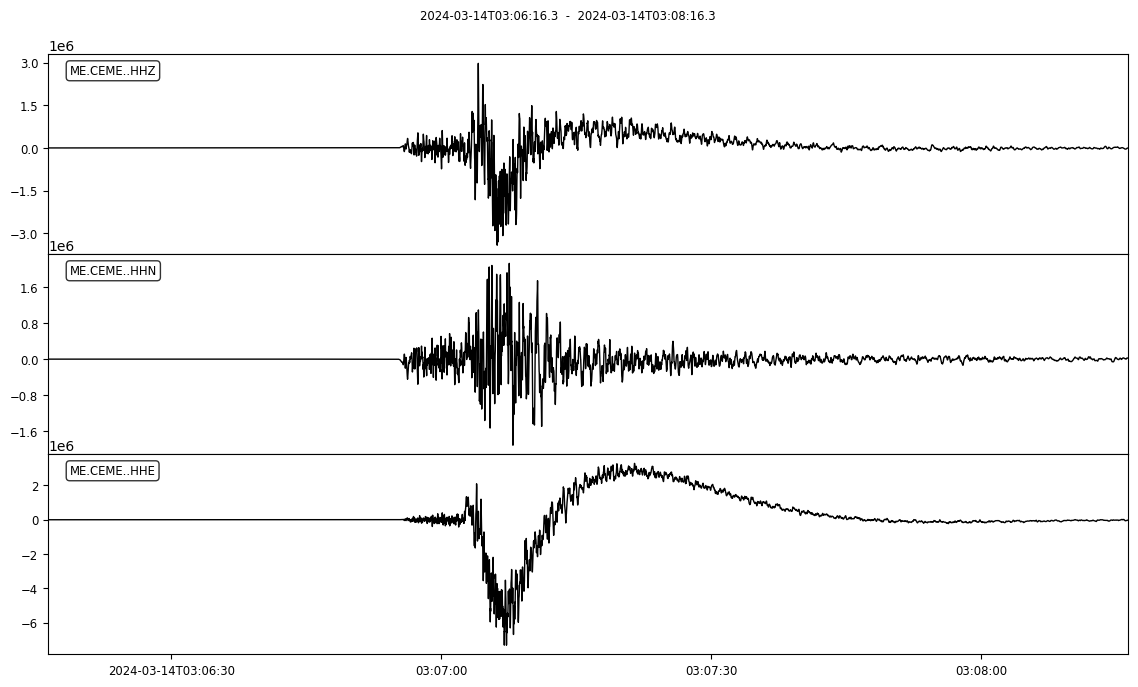

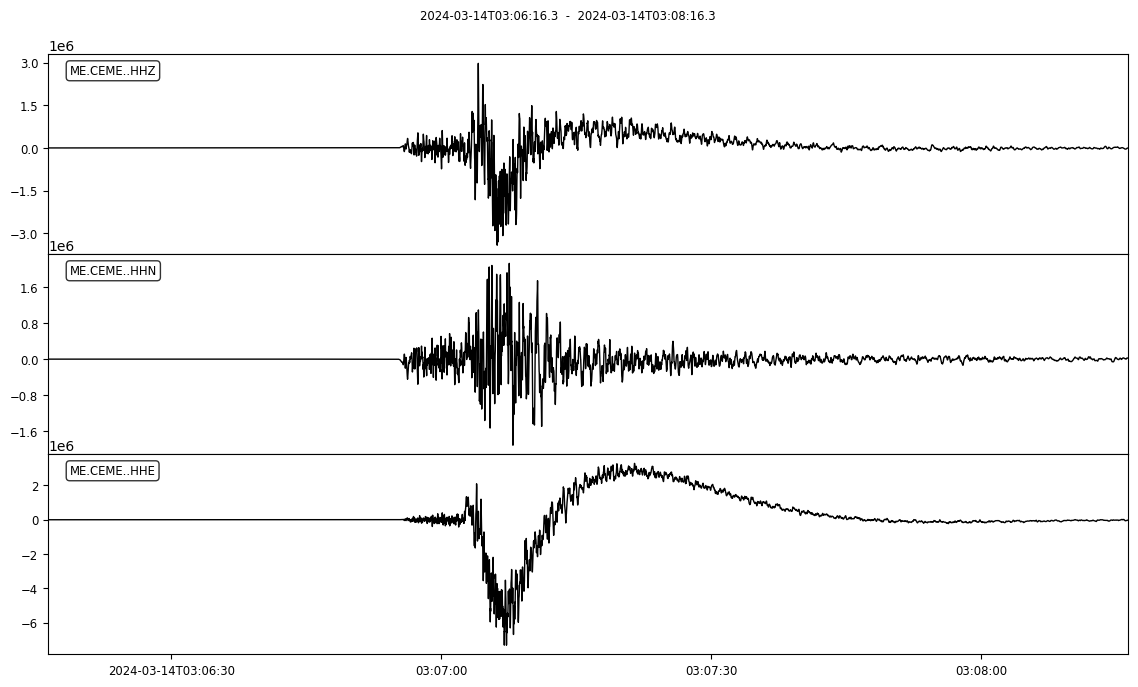

In [5]:

from obspy import UTCDateTime

# Mainshock origin time
t0 = UTCDateTime("2024-03-14T03:06:46.300")

# Extract a two-minute window around the mainshock
st_event = st.copy().trim(
    starttime=t0 - 30,
    endtime=t0 + 90
)

# Display three-component waveforms
st_event.plot(
    size=(1200, 700),
    equal_scale=False
)


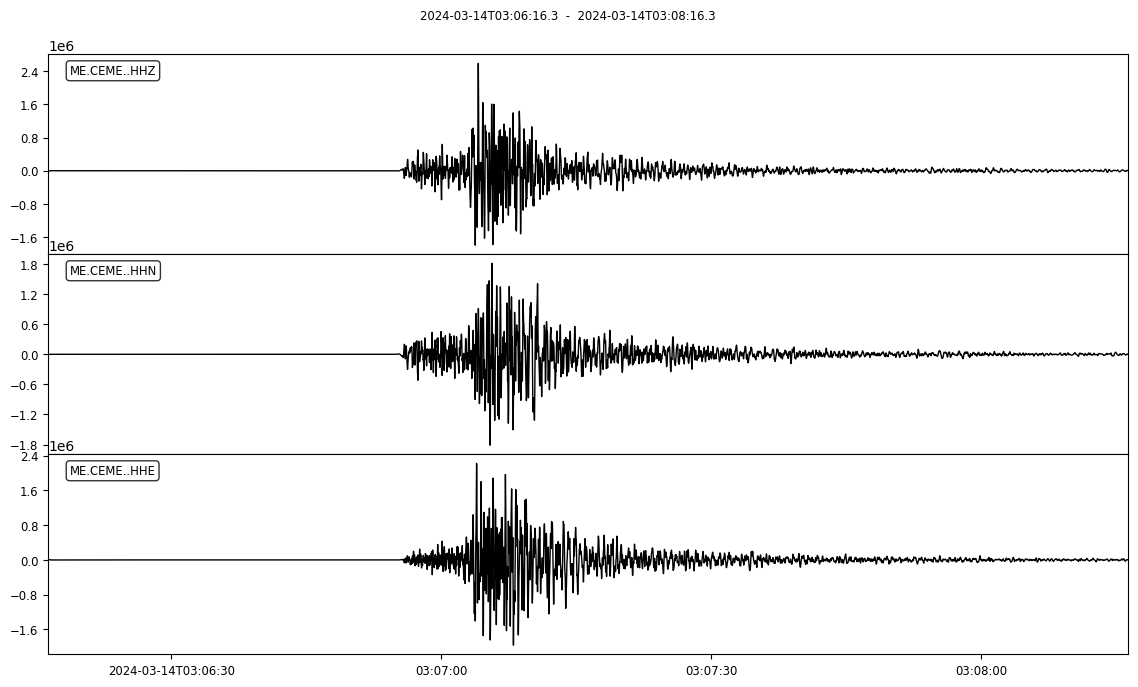

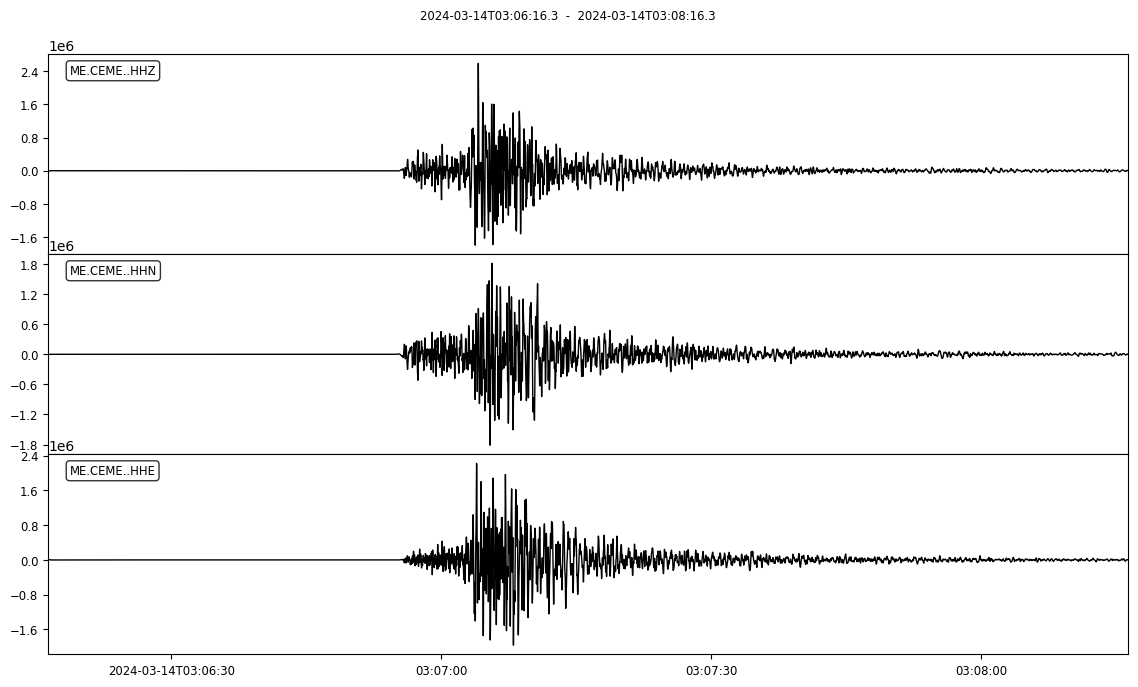

In [6]:

# Create a copy of the original waveforms
st_filtered = st_event.copy()

# Remove mean and linear trend
st_filtered.detrend("demean")
st_filtered.detrend("linear")

# Apply a bandpass filter
st_filtered.filter(
    "bandpass",
    freqmin=1.0,
    freqmax=15.0,
    corners=4,
    zerophase=True
)

# Plot filtered three-component waveforms
st_filtered.plot(
    size=(1200, 700),
    equal_scale=False
)



### Preliminary P- and S-Wave Arrival Detection — CEME

**Objective:** Develop a custom time series approach for identifying P- and S-wave onsets without pretrained models.

**Data:** 14 March 2024, Čarađe M5.3 earthquake; CEME station; 100 Hz MiniSEED waveforms.

#### P-wave detection (HHZ)
- Calculated absolute amplitude differences using `.diff()`.
- Estimated background noise over a 3.5-second window.
- Applied a robust threshold based on median and MAD.
- Selected the first threshold crossing as the P-arrival candidate.





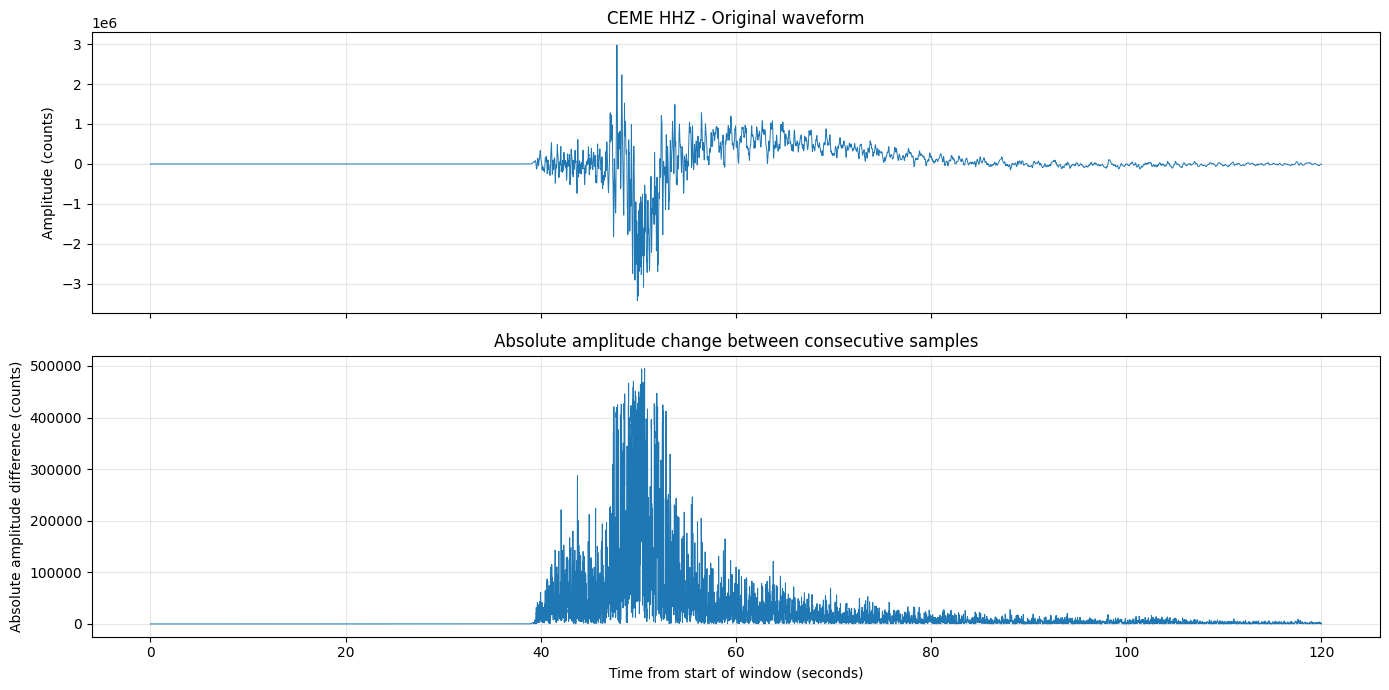

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the vertical component of the mainshock waveform
tr = st_event.select(channel="HHZ")[0].copy()

# Create a time series with amplitude values
time = tr.times()
amplitude = pd.Series(tr.data.astype(float))

# Calculate amplitude changes between consecutive samples
amplitude_diff = amplitude.diff().abs().fillna(0)

# Plot the original signal and amplitude changes
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time, amplitude, linewidth=0.7)
axes[0].set_title("CEME HHZ - Original waveform")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].grid(alpha=0.3)

axes[1].plot(time, amplitude_diff, linewidth=0.7)
axes[1].set_title("Absolute amplitude change between consecutive samples")
axes[1].set_xlabel("Time from start of window (seconds)")
axes[1].set_ylabel("Absolute amplitude difference (counts)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


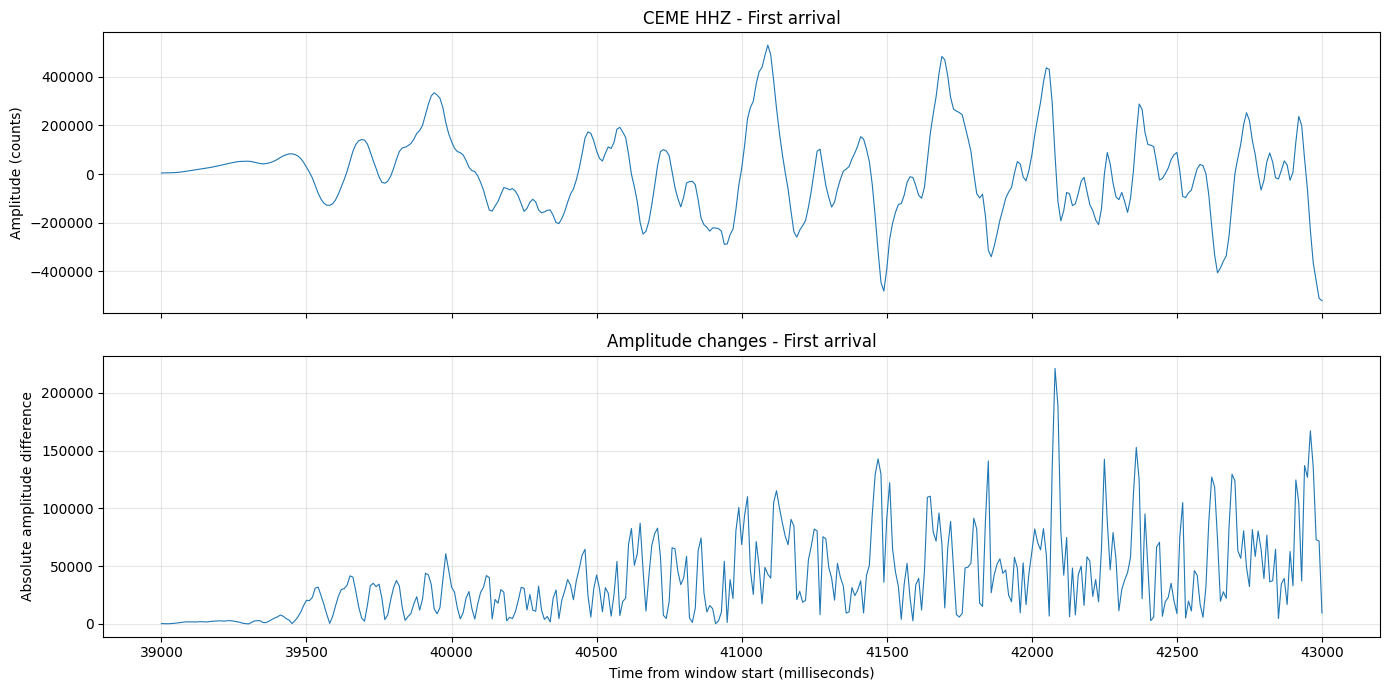

In [8]:

# Zoom into the beginning of the seismic signal
time_ms = time * 1000

# Select the interval from 39 to 43 seconds
mask = (time_ms >= 39000) & (time_ms <= 43000)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time_ms[mask], amplitude[mask], linewidth=0.8)
axes[0].set_title("CEME HHZ - First arrival")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].grid(alpha=0.3)

axes[1].plot(time_ms[mask], amplitude_diff[mask], linewidth=0.8)
axes[1].set_title("Amplitude changes - First arrival")
axes[1].set_xlabel("Time from window start (milliseconds)")
axes[1].set_ylabel("Absolute amplitude difference")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


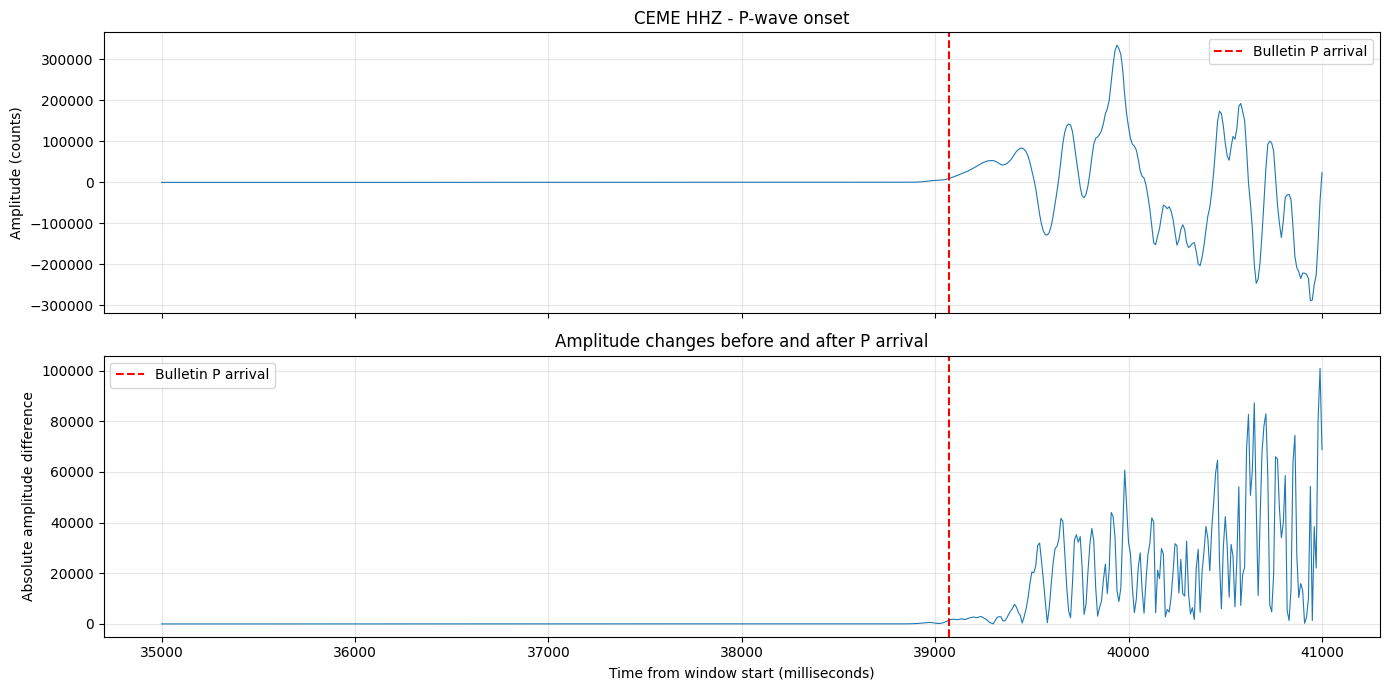

In [9]:

# Reference P arrival from the seismic bulletin
p_reference = 39070  # milliseconds from waveform start

# Select 35–41 seconds of the waveform
mask = (time_ms >= 35000) & (time_ms <= 41000)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Original waveform
axes[0].plot(time_ms[mask], amplitude[mask], linewidth=0.8)
axes[0].axvline(p_reference, color="red", linestyle="--",
                label="Bulletin P arrival")
axes[0].set_title("CEME HHZ - P-wave onset")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Amplitude differences
axes[1].plot(time_ms[mask], amplitude_diff[mask], linewidth=0.8)
axes[1].axvline(p_reference, color="red", linestyle="--",
                label="Bulletin P arrival")
axes[1].set_title("Amplitude changes before and after P arrival")
axes[1].set_xlabel("Time from window start (milliseconds)")
axes[1].set_ylabel("Absolute amplitude difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Detected P arrival: 38820 ms
Bulletin P arrival: 39070 ms
Difference: -250 ms


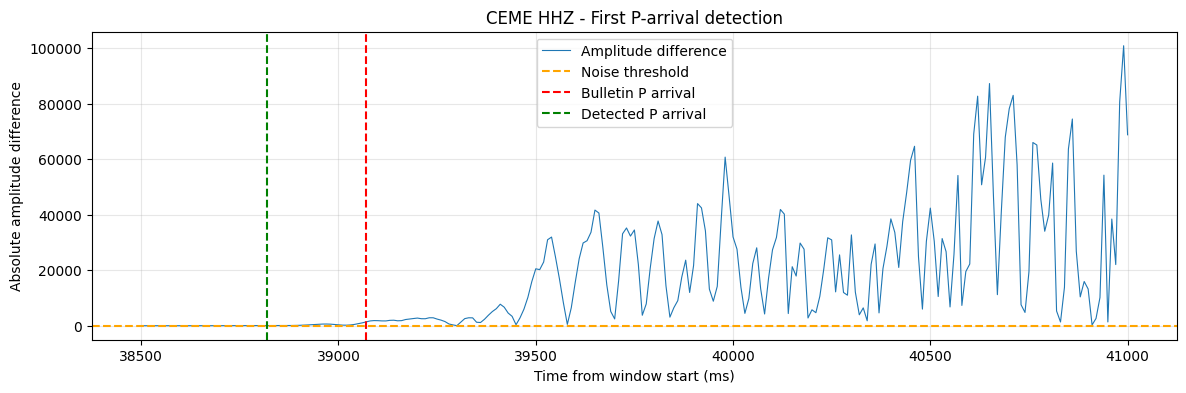

In [10]:

# Estimate background noise before the P arrival
noise_mask = (time_ms >= 35000) & (time_ms < 38500)

noise = amplitude_diff[noise_mask]

# Robust threshold using median and MAD
median_noise = np.median(noise)
mad_noise = np.median(np.abs(noise - median_noise))

threshold = median_noise + 6 * 1.4826 * mad_noise

# Search for the first significant amplitude change
search_mask = (time_ms >= 38500) & (time_ms <= 41000)

candidate_indices = np.where(
    search_mask & (amplitude_diff.to_numpy() > threshold)
)[0]

if len(candidate_indices) > 0:
    p_index = candidate_indices[0]
    p_time_ms = time_ms[p_index]

    print(f"Detected P arrival: {p_time_ms:.0f} ms")
    print(f"Bulletin P arrival: {p_reference:.0f} ms")
    print(f"Difference: {p_time_ms - p_reference:.0f} ms")
else:
    p_time_ms = None
    print("No P arrival detected.")

# Plot the detection threshold and reference arrival
plt.figure(figsize=(14, 4))
plt.plot(time_ms[search_mask], amplitude_diff[search_mask],
         linewidth=0.8, label="Amplitude difference")
plt.axhline(threshold, color="orange", linestyle="--",
            label="Noise threshold")
plt.axvline(p_reference, color="red", linestyle="--",
            label="Bulletin P arrival")

if p_time_ms is not None:
    plt.axvline(p_time_ms, color="green", linestyle="--",
                label="Detected P arrival")

plt.xlabel("Time from window start (ms)")
plt.ylabel("Absolute amplitude difference")
plt.title("CEME HHZ - First P-arrival detection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [11]:

# Convert detected arrival to absolute UTC time
p_arrival_utc = tr.stats.starttime + p_time_ms / 1000

print(f"Detected P arrival (UTC): {p_arrival_utc}")


Detected P arrival (UTC): 2024-03-14T03:06:55.120000Z


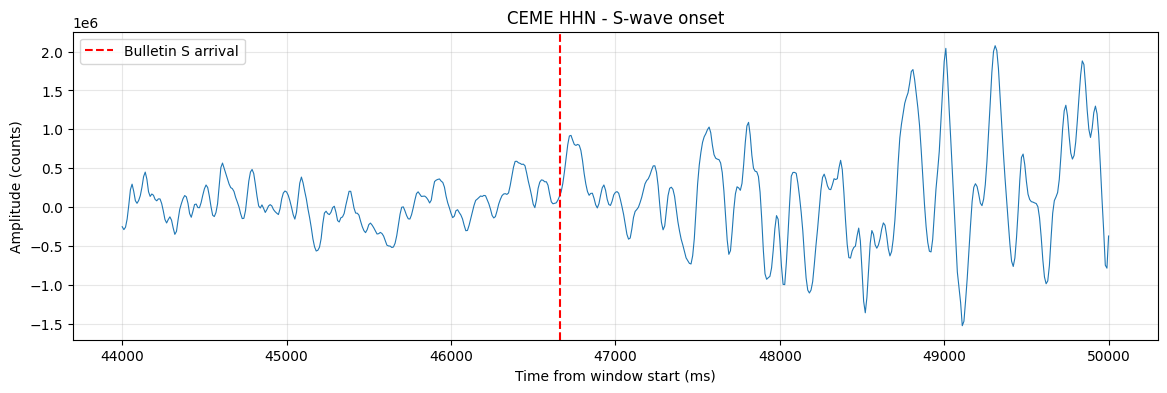

In [12]:

# Select HHN component for S-wave analysis
tr_n = st_event.select(channel="HHN")[0]

time_ms = tr_n.times() * 1000
s_reference = 46660  # Bulletin S arrival in milliseconds

mask = (time_ms >= 44000) & (time_ms <= 50000)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], tr_n.data[mask], linewidth=0.8)
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

plt.title("CEME HHN - S-wave onset")
plt.xlabel("Time from window start (ms)")
plt.ylabel("Amplitude (counts)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


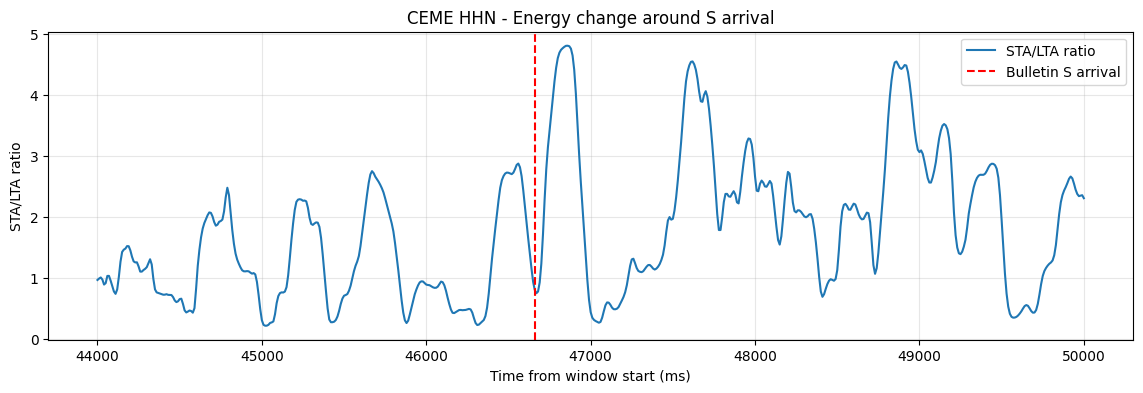

In [13]:

# Calculate signal energy on the HHN component
energy = pd.Series(tr_n.data.astype(float) ** 2)

# Sampling frequency
fs = tr_n.stats.sampling_rate

# Short and long moving averages
sta = energy.rolling(window=int(0.2 * fs), min_periods=1).mean()
lta = energy.rolling(window=int(3.0 * fs), min_periods=1).mean()

# STA/LTA ratio
ratio = sta / (lta + 1e-12)

# Display the interval around the S arrival
mask = (time_ms >= 44000) & (time_ms <= 50000)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], ratio[mask], label="STA/LTA ratio")
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

plt.xlabel("Time from window start (ms)")
plt.ylabel("STA/LTA ratio")
plt.title("CEME HHN - Energy change around S arrival")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


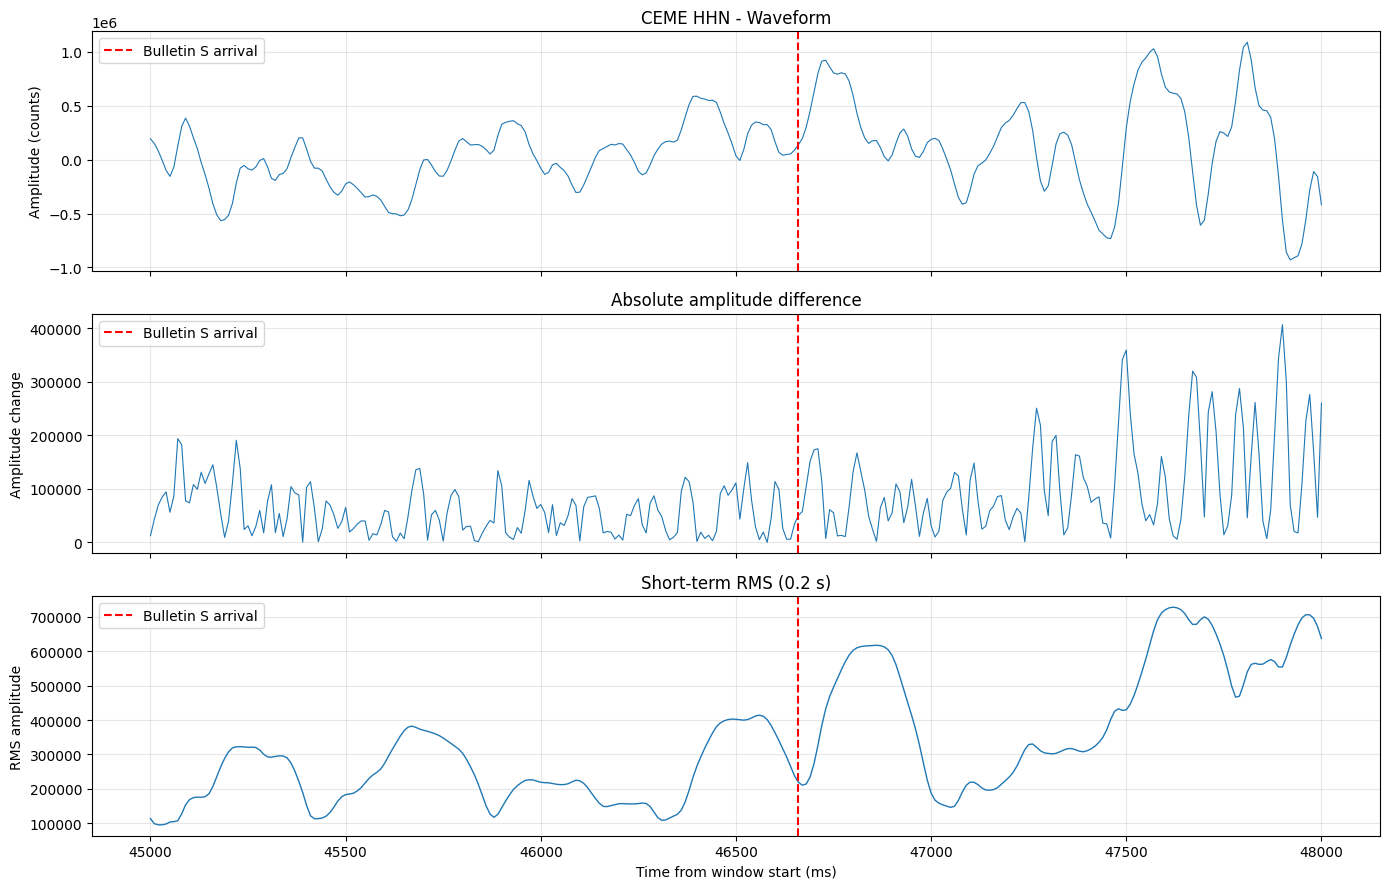

In [14]:

# HHN amplitude time series
hhn = pd.Series(tr_n.data.astype(float))

# Absolute amplitude change between samples
hhn_diff = hhn.diff().abs().fillna(0)

# Short-term RMS amplitude (0.2 seconds)
fs = tr_n.stats.sampling_rate
window = int(0.2 * fs)

hhn_rms = np.sqrt(
    (hhn ** 2).rolling(window=window, min_periods=window).mean()
)

# Focus on the S-wave arrival
mask = (time_ms >= 45000) & (time_ms <= 48000)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(time_ms[mask], hhn[mask], linewidth=0.8)
axes[0].set_ylabel("Amplitude (counts)")
axes[0].set_title("CEME HHN - Waveform")

axes[1].plot(time_ms[mask], hhn_diff[mask], linewidth=0.8)
axes[1].set_ylabel("Amplitude change")
axes[1].set_title("Absolute amplitude difference")

axes[2].plot(time_ms[mask], hhn_rms[mask], linewidth=1)
axes[2].set_ylabel("RMS amplitude")
axes[2].set_title("Short-term RMS (0.2 s)")
axes[2].set_xlabel("Time from window start (ms)")

for ax in axes:
    ax.axvline(
        s_reference,
        color="red",
        linestyle="--",
        label="Bulletin S arrival"
    )
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


S candidate: 46830 ms
S candidate UTC: 2024-03-14T03:07:03.130000Z
Bulletin S: 46660 ms
Difference: 170 ms


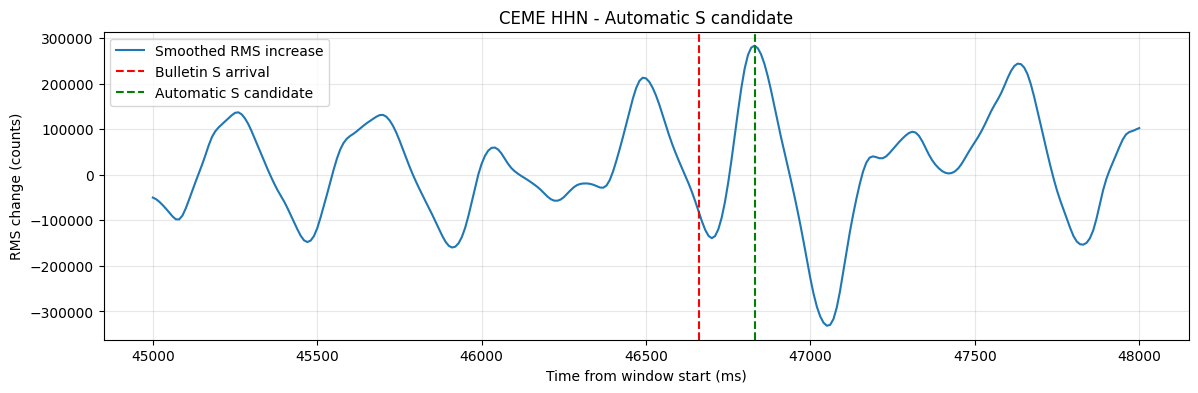

In [15]:

# Detect sustained RMS increase on the HHN component

rms_values = hhn_rms.to_numpy()
t = time_ms

# Calculate RMS change over 0.1 seconds
lag = int(0.1 * fs)
rms_change = hhn_rms.diff(periods=lag)

# Smooth the change over 0.1 seconds
smooth_change = rms_change.rolling(
    window=lag, min_periods=lag
).mean()

# Search for the strongest sustained RMS increase
# within the exploratory S-phase interval
search_mask = (t >= 45000) & (t <= 48000)

valid_indices = np.where(
    search_mask & np.isfinite(smooth_change.to_numpy())
)[0]

if len(valid_indices) > 0:
    s_index = valid_indices[
        np.argmax(smooth_change.iloc[valid_indices].to_numpy())
    ]

    s_candidate_ms = t[s_index]
    s_candidate_utc = tr_n.stats.starttime + s_candidate_ms / 1000

    print(f"S candidate: {s_candidate_ms:.0f} ms")
    print(f"S candidate UTC: {s_candidate_utc}")
    print(f"Bulletin S: {s_reference:.0f} ms")
    print(f"Difference: {s_candidate_ms - s_reference:.0f} ms")
else:
    s_candidate_ms = None
    print("No valid S candidate found.")

# Plot the RMS change
plt.figure(figsize=(14, 4))
plt.plot(t[search_mask], smooth_change[search_mask],
         label="Smoothed RMS increase")

plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

if s_candidate_ms is not None:
    plt.axvline(s_candidate_ms, color="green", linestyle="--",
                label="Automatic S candidate")

plt.xlabel("Time from window start (ms)")
plt.ylabel("RMS change (counts)")
plt.title("CEME HHN - Automatic S candidate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Estimated S onset: 2024-03-14T03:07:02.970000Z
Difference from bulletin: 10 ms


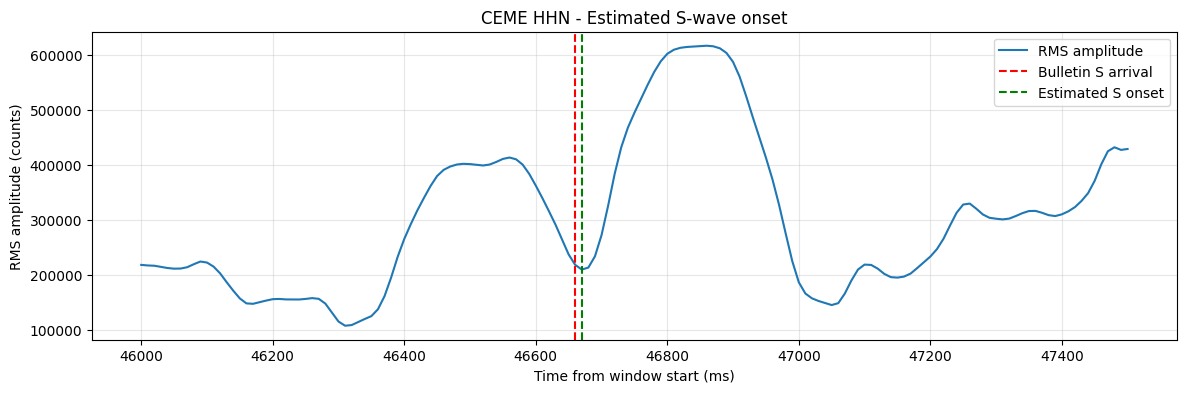

In [16]:

# Find the beginning of the RMS increase before the detected maximum

# Search up to 0.3 seconds before the RMS maximum
lookback = int(0.3 * fs)

start_idx = max(0, s_index - lookback)

# Find the local minimum of RMS before the maximum
rms_segment = hhn_rms.iloc[start_idx:s_index + 1]

s_onset_index = rms_segment.idxmin()
s_onset_ms = time_ms[s_onset_index]

# Convert to absolute UTC time
s_onset_utc = tr_n.stats.starttime + s_onset_ms / 1000

print(f"Estimated S onset: {s_onset_utc}")
print(f"Difference from bulletin: {(s_onset_ms - s_reference):.0f} ms")

# Plot the result
mask = (time_ms >= 46000) & (time_ms <= 47500)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], hhn_rms[mask], label="RMS amplitude")
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")
plt.axvline(s_onset_ms, color="green", linestyle="--",
            label="Estimated S onset")
plt.xlabel("Time from window start (ms)")
plt.ylabel("RMS amplitude (counts)")
plt.title("CEME HHN - Estimated S-wave onset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Testing P- and S-Wave Detection on a Second Earthquake

We select a smaller aftershock (ML 3.2, March 14, 2024, 03:14:46 UTC) to evaluate our detection algorithms.

First, we extract and visualize the three-component CEME waveforms to inspect signal quality and possible overlapping events.

The goal is to test P- and S-wave arrival detection using the same algorithm parameters and compare the results with the manually picked phases in the seismic bulletin.


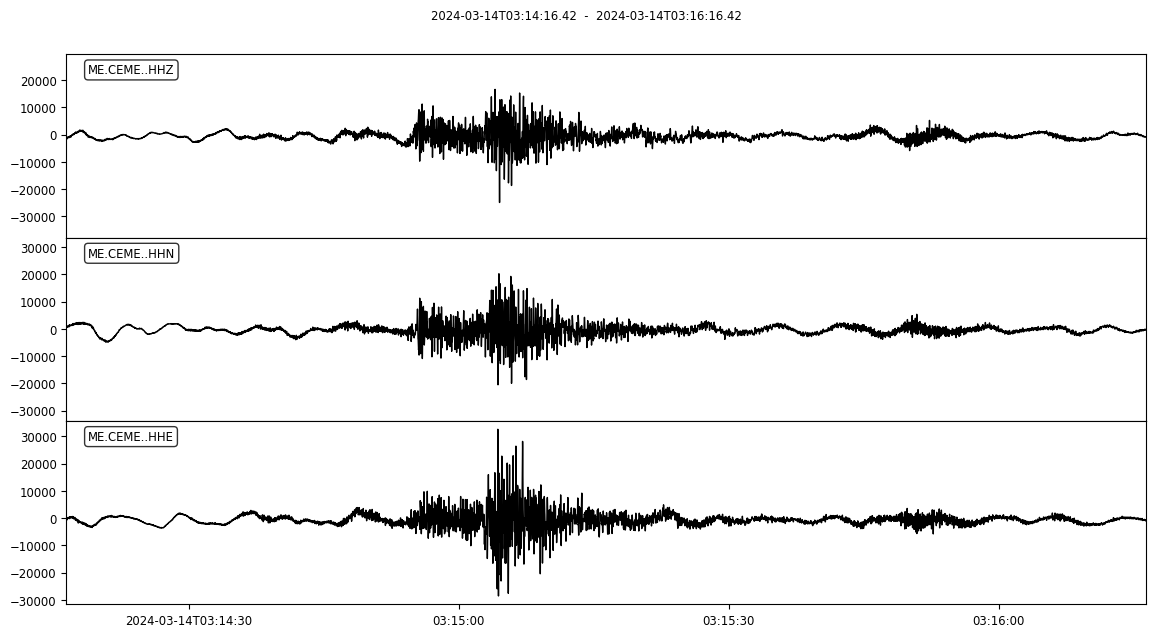

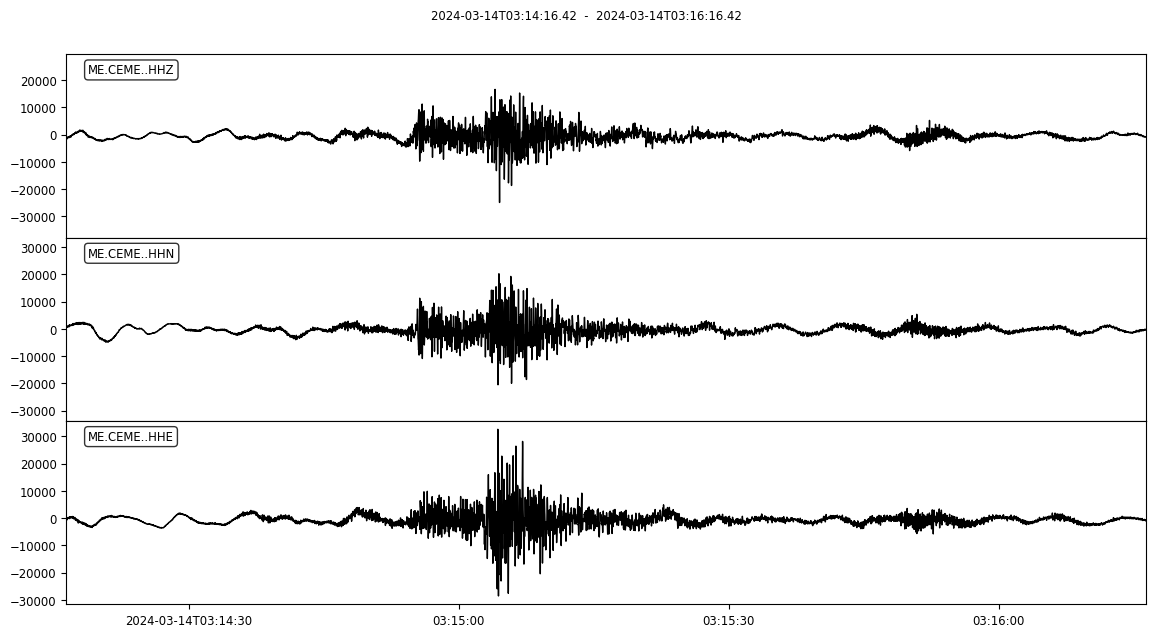

In [17]:

from obspy import UTCDateTime

# Second test event: ML 3.2
t0_test = UTCDateTime("2024-03-14T03:14:46.420")

# Extract waveform window
st_test = st.slice(
    starttime=t0_test - 30,
    endtime=t0_test + 90
).copy()

st_test.plot(size=(1200, 650))


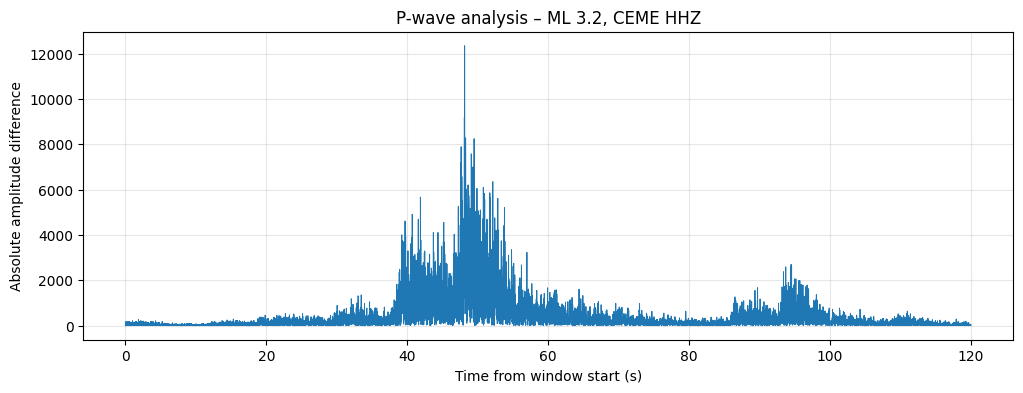

In [18]:

# P-wave analysis for the second earthquake (HHZ)

tr_test = st_test.select(channel="HHZ")[0].copy()

time_test = tr_test.times() * 1000
amplitude_test = pd.Series(tr_test.data.astype(float))
amplitude_diff_test = amplitude_test.diff().abs().fillna(0)

# Visualize amplitude changes
plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, amplitude_diff_test, linewidth=0.7)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave analysis – ML 3.2, CEME HHZ")
plt.grid(alpha=0.3)
plt.show()


In [19]:

# Same P-wave threshold method as for the mainshock

noise = amplitude_diff_test[
    (time_test >= 30000) & (time_test < 35000)
]

median_noise = noise.median()
mad_noise = (noise - median_noise).abs().median()

threshold = median_noise + 6 * 1.4826 * mad_noise

print("Threshold:", threshold)


Threshold: 1630.2136


In [20]:

# Detect the first threshold crossing after the noise window

search_mask = (time_test >= 35000) & (time_test <= 45000)

candidates = np.where(
    search_mask & (amplitude_diff_test.to_numpy() > threshold)
)[0]

if len(candidates) > 0:
    p_index_test = candidates[0]
    p_time_test = time_test[p_index_test]
    p_utc_test = tr_test.stats.starttime + p_time_test / 1000

    print("Detected P arrival:", p_utc_test)
else:
    print("No P arrival detected")


Detected P arrival: 2024-03-14T03:14:54.940000Z


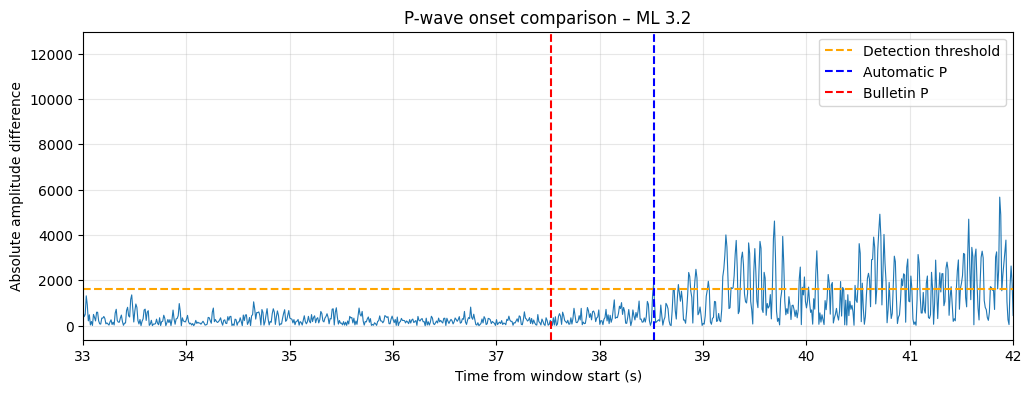

In [21]:

# Inspect the detected P-wave onset

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_diff_test, lw=0.8)

plt.axhline(threshold, color="orange",
            linestyle="--", label="Detection threshold")

plt.axvline(p_time_test / 1000, color="blue",
            linestyle="--", label="Automatic P")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(33, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave onset comparison – ML 3.2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


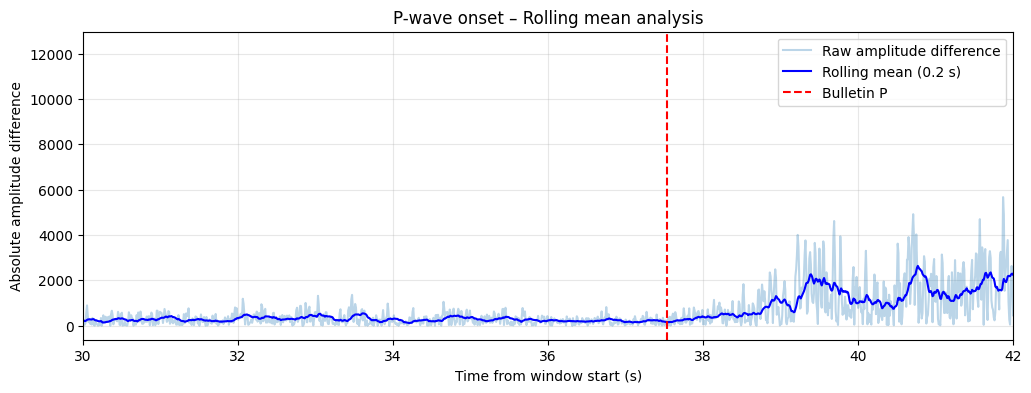

In [22]:

# Smooth amplitude differences using a 0.2-second rolling window

window = int(0.2 * tr_test.stats.sampling_rate)

p_rolling = amplitude_diff_test.rolling(
    window=window,
    min_periods=window
).mean()

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_diff_test,
         alpha=0.3, label="Raw amplitude difference")

plt.plot(time_test / 1000, p_rolling,
         color="blue", linewidth=1.5,
         label="Rolling mean (0.2 s)")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(30, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave onset – Rolling mean analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


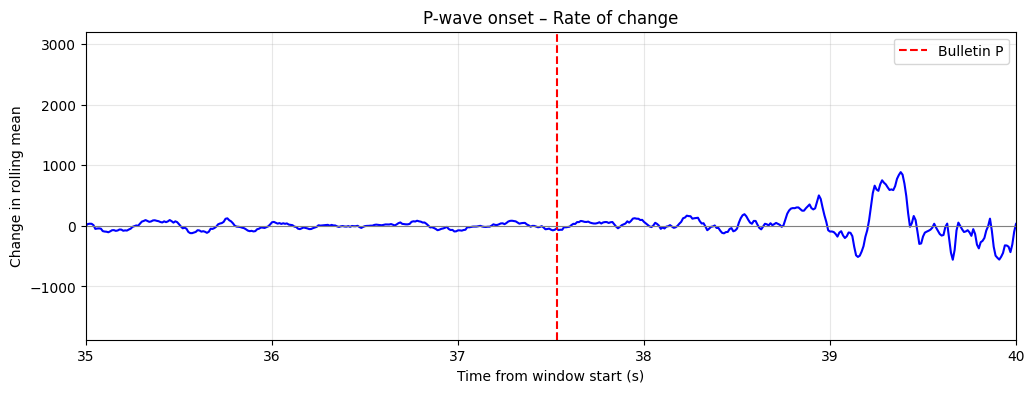

In [23]:

# Rate of change in the rolling mean

p_change = p_rolling.diff(periods=10)

plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, p_change, color="blue")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.axhline(0, color="gray", linewidth=0.8)

plt.xlim(35, 40)
plt.xlabel("Time from window start (s)")
plt.ylabel("Change in rolling mean")
plt.title("P-wave onset – Rate of change")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


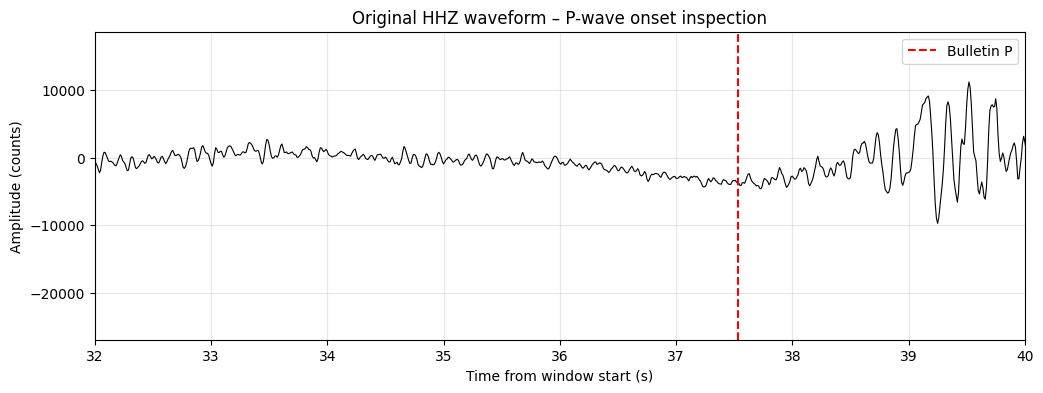

In [24]:

# Inspect the original HHZ waveform around the P arrival

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_test, color="black", lw=0.8)

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(32, 40)
plt.xlabel("Time from window start (s)")
plt.ylabel("Amplitude (counts)")
plt.title("Original HHZ waveform – P-wave onset inspection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


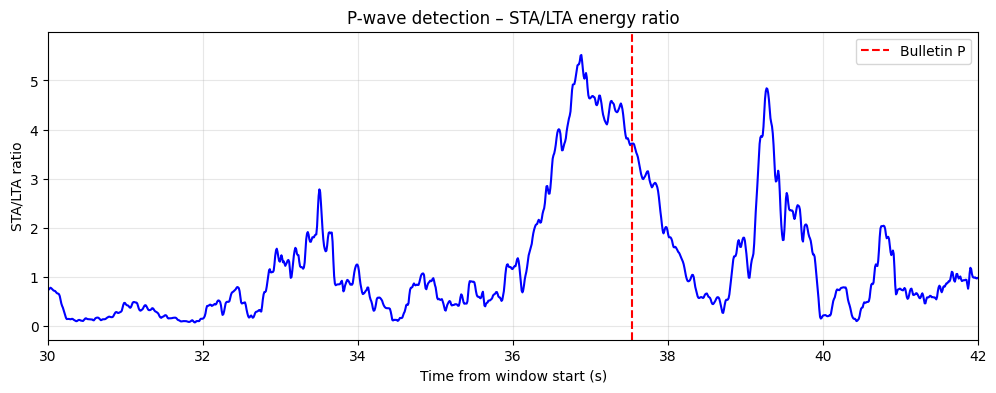

In [25]:

# P-wave detection using STA/LTA on HHZ

fs = tr_test.stats.sampling_rate
energy_p = amplitude_test ** 2

sta_p = energy_p.rolling(
    window=int(0.2 * fs),
    min_periods=int(0.2 * fs)
).mean()

lta_p = energy_p.rolling(
    window=int(3.0 * fs),
    min_periods=int(3.0 * fs)
).mean()

ratio_p = sta_p / (lta_p + 1e-12)

plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, ratio_p, color="blue")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(30, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("STA/LTA ratio")
plt.title("P-wave detection – STA/LTA energy ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


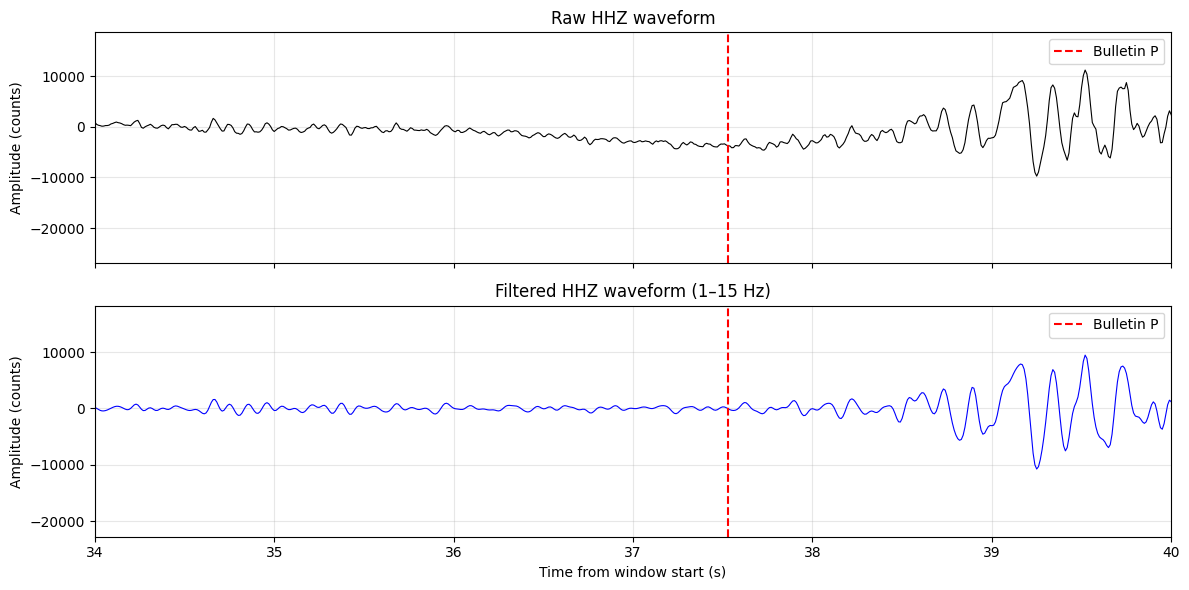

In [26]:

# Compare raw and filtered HHZ waveforms

tr_filtered_test = tr_test.copy()
tr_filtered_test.detrend("demean")
tr_filtered_test.filter(
    "bandpass", freqmin=1, freqmax=15,
    corners=4, zerophase=True
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(time_test / 1000, tr_test.data, color="black", lw=0.8)
axes[0].set_title("Raw HHZ waveform")

axes[1].plot(time_test / 1000, tr_filtered_test.data, color="blue", lw=0.8)
axes[1].set_title("Filtered HHZ waveform (1–15 Hz)")

for ax in axes:
    ax.axvline(37.53, color="red", linestyle="--", label="Bulletin P")
    ax.set_ylabel("Amplitude (counts)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlim(34, 40)
axes[1].set_xlabel("Time from window start (s)")

plt.tight_layout()
plt.show()


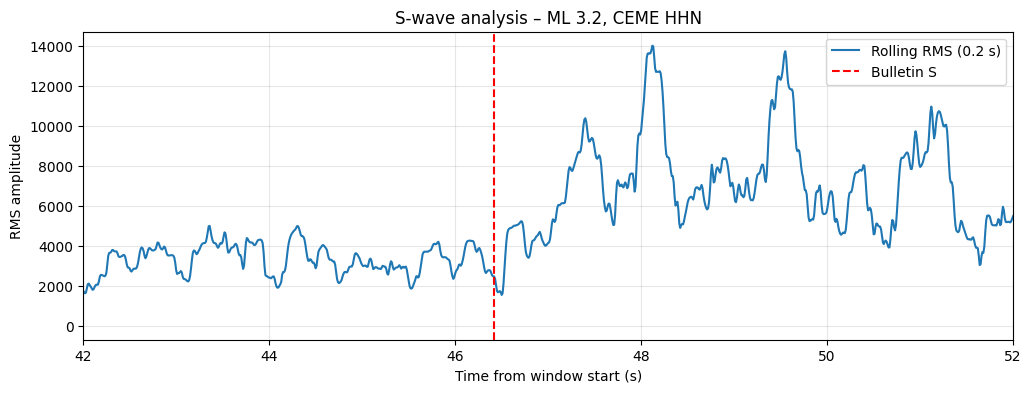

In [27]:

# S-wave analysis – ML 3.2, CEME HHN

tr_s_test = st_test.select(channel="HHN")[0].copy()

fs = tr_s_test.stats.sampling_rate
time_s = tr_s_test.times() * 1000

hhn_test = pd.Series(tr_s_test.data.astype(float))

# Rolling RMS (0.2 s)
window = int(0.2 * fs)

s_rms_test = np.sqrt(
    (hhn_test ** 2).rolling(
        window=window, min_periods=window
    ).mean()
)

# RMS change over 0.1 s
lag = int(0.1 * fs)

s_change_test = s_rms_test.diff(periods=lag)

s_smooth_test = s_change_test.rolling(
    window=lag, min_periods=lag
).mean()

# Visual inspection
plt.figure(figsize=(12, 4))

plt.plot(time_s / 1000, s_rms_test,
         label="Rolling RMS (0.2 s)")

plt.axvline(46.42, color="red",
            linestyle="--", label="Bulletin S")

plt.xlim(42, 52)
plt.xlabel("Time from window start (s)")
plt.ylabel("RMS amplitude")
plt.title("S-wave analysis – ML 3.2, CEME HHN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [28]:

# Find the strongest RMS increase

search_mask = (time_s >= 45000) & (time_s <= 48000)

valid_indices = np.where(
    search_mask & np.isfinite(s_smooth_test.to_numpy())
)[0]

s_index_test = valid_indices[
    np.argmax(s_smooth_test.iloc[valid_indices].to_numpy())
]

# Find the preceding RMS minimum (0.3 s)
lookback = int(0.3 * fs)
start_idx = max(0, s_index_test - lookback)

rms_segment = s_rms_test.iloc[start_idx:s_index_test + 1]
s_onset_index_test = rms_segment.idxmin()

s_onset_ms_test = time_s[s_onset_index_test]
s_onset_utc_test = (
    tr_s_test.stats.starttime + s_onset_ms_test / 1000
)

print("Strongest RMS increase:",
      tr_s_test.stats.starttime + time_s[s_index_test] / 1000)

print("Estimated S onset:", s_onset_utc_test)


Strongest RMS increase: 2024-03-14T03:15:03.050000Z
Estimated S onset: 2024-03-14T03:15:02.920000Z


In [29]:

# Compare detected S arrival with the bulletin

s_bulletin = UTCDateTime("2024-03-14T03:15:02.840")

s_difference = s_onset_utc_test - s_bulletin

print("Bulletin S (UTC):", s_bulletin)
print("Detected S (UTC):", s_onset_utc_test)
print("Difference (seconds):", round(s_difference, 3))
print("Difference (milliseconds):", round(s_difference * 1000))


Bulletin S (UTC): 2024-03-14T03:15:02.840000Z
Detected S (UTC): 2024-03-14T03:15:02.920000Z
Difference (seconds): 0.08
Difference (milliseconds): 80


In [30]:

# Select earthquakes with magnitude between 2.0 and 3.0

candidates = caradje_march[
    caradje_march["magnitude_ML_or_Md"].between(2.0, 3.0)
]

display(candidates.head(10))


,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg,distance_km,origin_datetime
284,2024,3,14,3,19,24.97,0.24,42.9538,0.0033,18.6537,0.0068,19.1,1.0,2.2,34,153,2.323354,2024-03-14 03:19:24.970000+00:00
403,2024,3,14,3,19,25.69,0.17,42.9829,0.0036,18.6826,0.0066,13.6,1.3,2.2,20,165,2.016703,2024-03-14 03:19:25.690000+00:00
404,2024,3,14,3,20,37.44,0.54,42.9315,0.0080,18.6552,0.0166,17.6,2.0,2.3,32,144,4.749300,2024-03-14 03:20:37.440000+00:00
405,2024,3,14,3,23,3.05,0.15,42.9697,0.0031,18.6611,0.0067,5.3,2.7,2.2,18,165,0.478207,2024-03-14 03:23:03.050000+00:00
406,2024,3,14,3,25,4.49,0.20,42.9650,0.0037,18.6383,0.0079,11.2,1.3,2.4,22,171,2.100646,2024-03-14 03:25:04.490000+00:00
407,2024,3,14,3,26,14.81,0.33,42.9326,0.0070,18.6894,0.0099,9.0,2.5,2.0,32,158,5.151131,2024-03-14 03:26:14.810000+00:00
408,2024,3,14,3,29,34.49,0.23,43.0191,0.0042,18.6823,0.0063,10.0,11.1,2.4,27,171,5.305648,2024-03-14 03:29:34.490000+00:00
409,2024,3,14,3,29,59.32,0.07,43.0317,0.0034,18.6394,0.0043,10.0,11.1,2.2,14,295,6.652040,2024-03-14 03:29:59.320000+00:00
410,2024,3,14,3,35,2.23,0.19,42.9421,0.0048,18.6748,0.0064,11.6,1.3,2.3,30,166,3.720648,2024-03-14 03:35:02.230000+00:00
411,2024,3,14,3,36,32.19,0.11,42.9312,0.0023,18.6774,0.0043,9.0,1.0,2.0,22,138,4.942765,2024-03-14 03:36:32.190000+00:00


### 3th TEST, EQ ML 2,3 od 14.03.2024. u 03:20:37.440 UTC
Selected event have low guality for furder testing

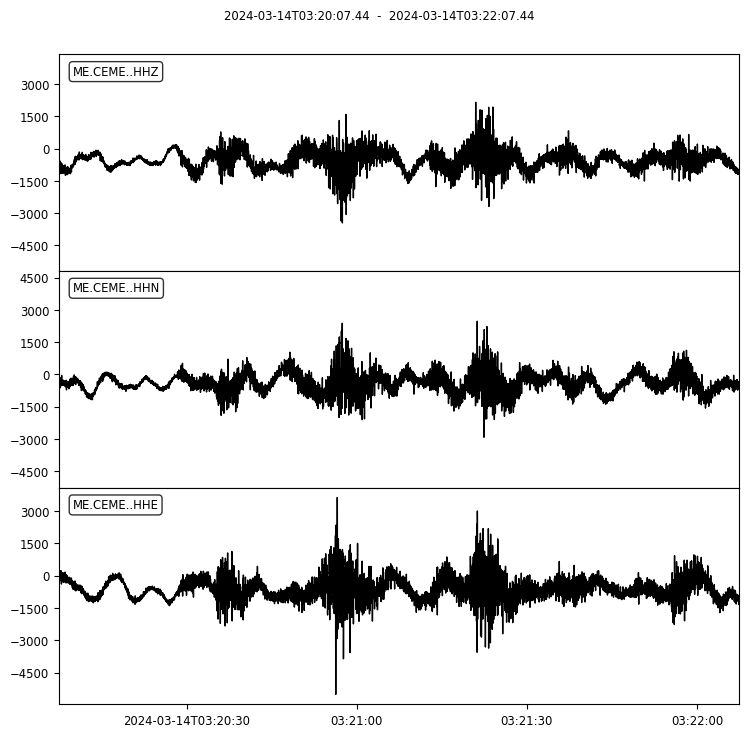

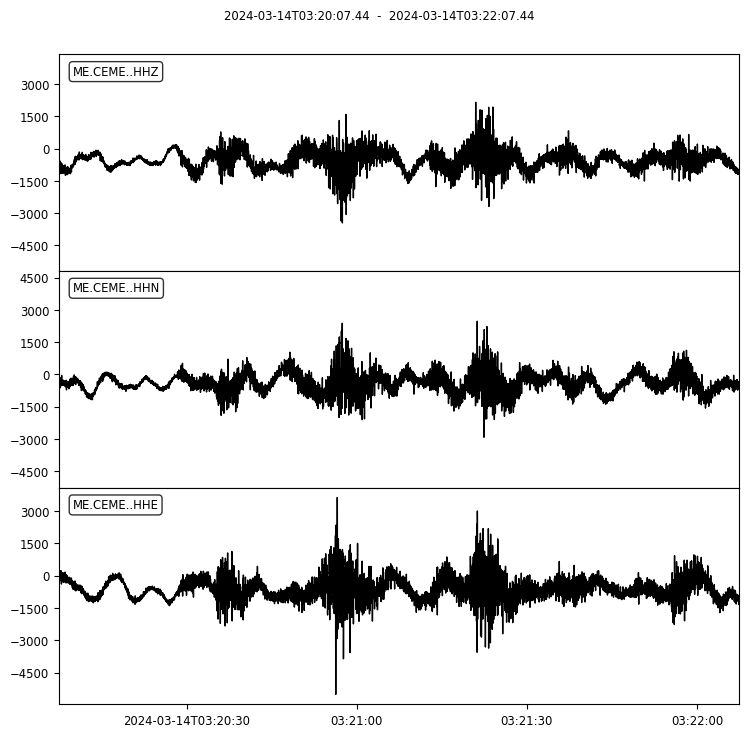

In [31]:

# Third test event: ML 2.3

t0_test3 = UTCDateTime("2024-03-14T03:20:37.440")

st_test3 = st.slice(
    starttime=t0_test3 - 30,
    endtime=t0_test3 + 90
).copy()

st_test3.plot()


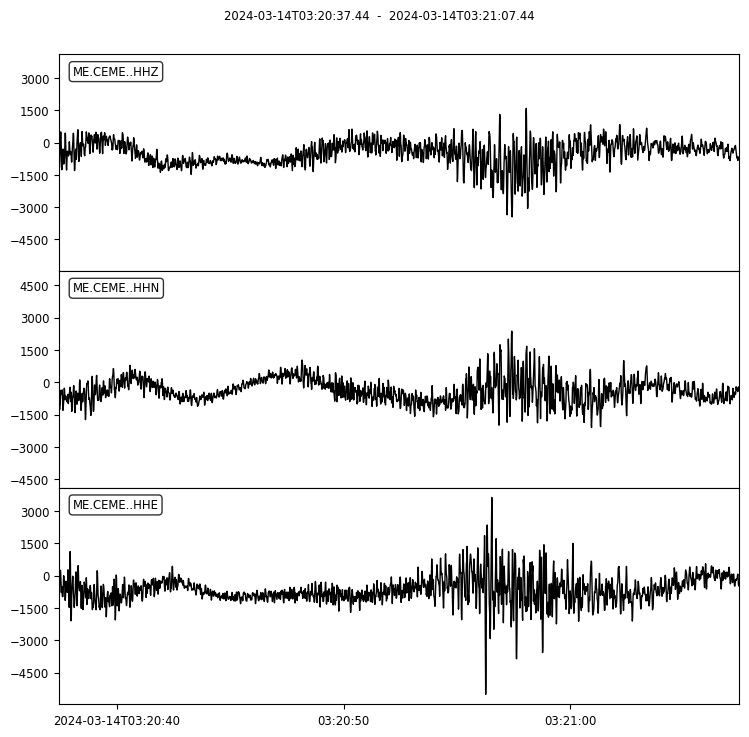

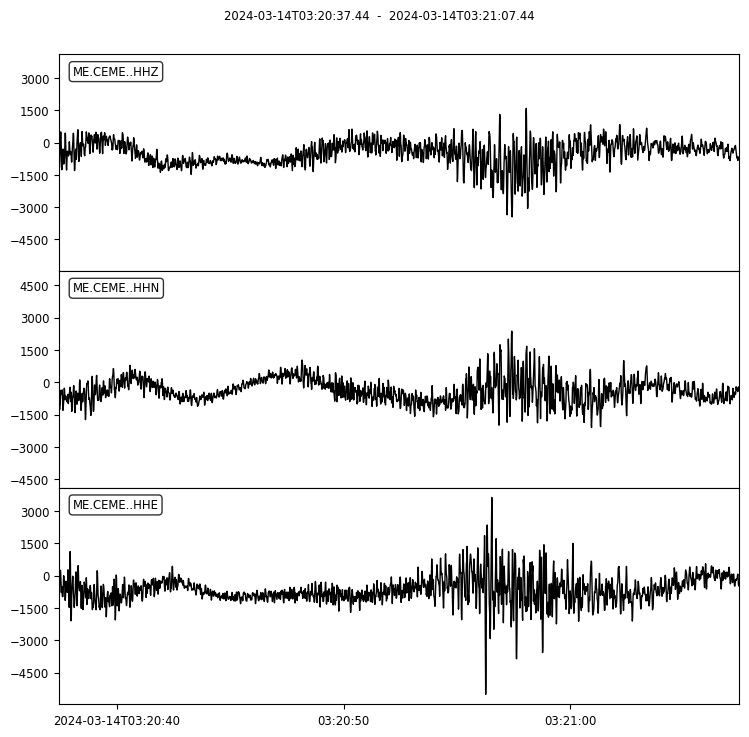

In [32]:

# Zoom in around the third event

st_test3.slice(
    starttime=t0_test3,
    endtime=t0_test3 + 30
).plot()


### 4th TEST, EQ ML 2,3 od 14.03.2024. u 03:20:37.440 UTC

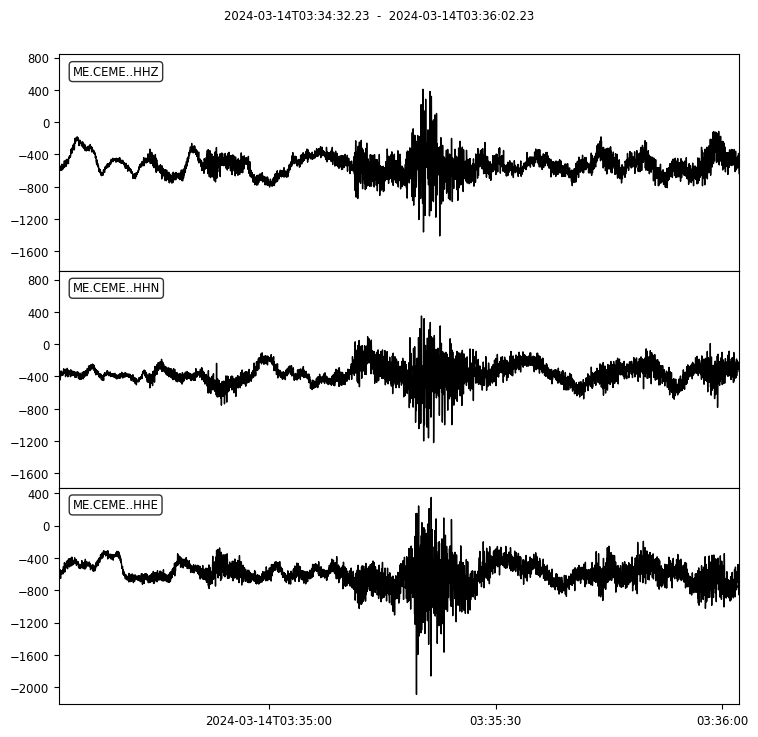

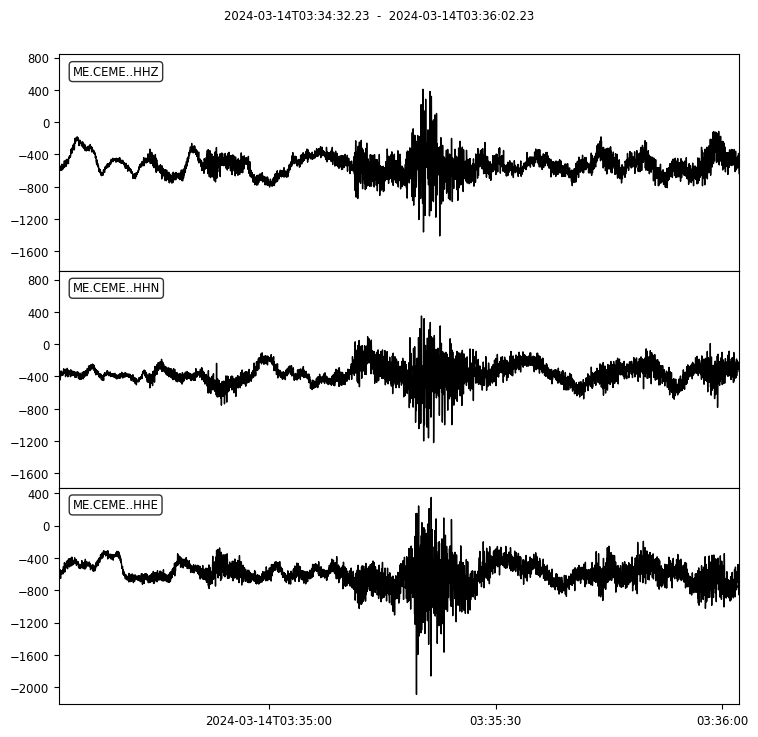

In [33]:

# nTest event: ML 2.3

t0_test4 = UTCDateTime("2024-03-14T03:35:02.230")

st_test4 = st.slice(
    starttime=t0_test4 - 30,
    endtime=t0_test4 + 60
).copy()

st_test4.plot()


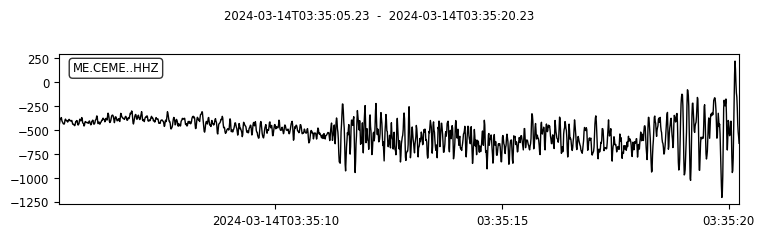

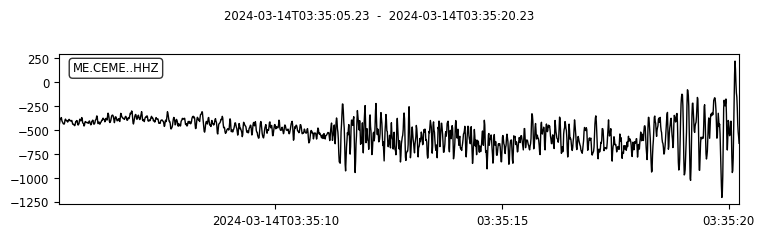

In [34]:

# Zoom in on the P-wave window

tr_p4 = st_test4.select(channel="HHZ")[0]

tr_p4.slice(
    starttime=t0_test4 + 3,
    endtime=t0_test4 + 18
).plot()


In [35]:

# Prepare P-wave detection for the third event

time_p4 = tr_p4.times() * 1000
amplitude_p4 = pd.Series(tr_p4.data.astype(float))

diff_p4 = amplitude_p4.diff().abs().fillna(0)

# Noise window: 33–38 seconds
noise_p4 = diff_p4[(time_p4 >= 33000) & (time_p4 < 38000)]

median_p4 = noise_p4.median()
mad_p4 = (noise_p4 - median_p4).abs().median()

threshold_p4 = median_p4 + 6 * 1.4826 * mad_p4

print("P threshold:", threshold_p4)


P threshold: 84.1648


In [36]:

# Detect P arrival

p_mask4 = (
    (time_p4 >= 35000) &
    (time_p4 <= 48000) &
    (diff_p4 > threshold_p4)
)

p_indices4 = np.where(p_mask4)[0]

if len(p_indices4) > 0:
    p_time_ms4 = time_p4[p_indices4[0]]
    p_arrival_utc4 = tr_p4.stats.starttime + p_time_ms4 / 1000
    print("Detected P arrival (UTC):", p_arrival_utc4)
else:
    print("No P arrival detected")


Detected P arrival (UTC): 2024-03-14T03:35:09.290000Z


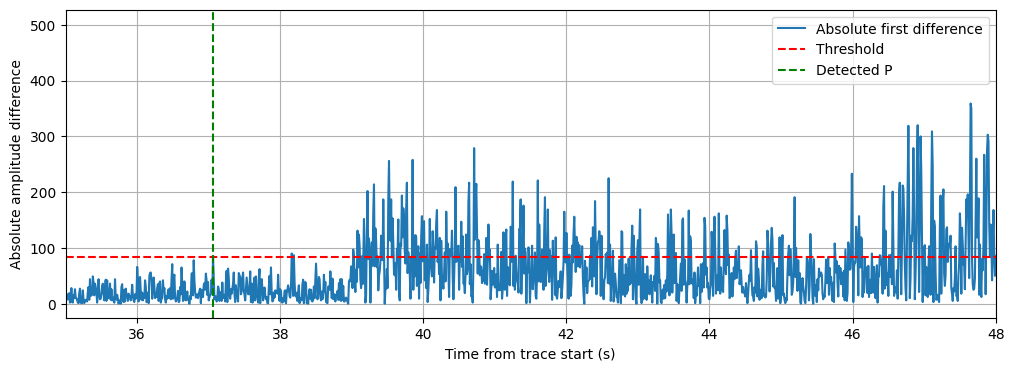

In [37]:

# Plot P detection and threshold

plt.figure(figsize=(12, 4))
plt.plot(time_p4 / 1000, diff_p4, label="Absolute first difference")
plt.axhline(threshold_p4, color="red", linestyle="--", label="Threshold")
plt.axvline(p_time_ms4 / 1000, color="green", linestyle="--", label="Detected P")
plt.xlim(35, 48)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Absolute amplitude difference")
plt.legend()
plt.grid()
plt.show()


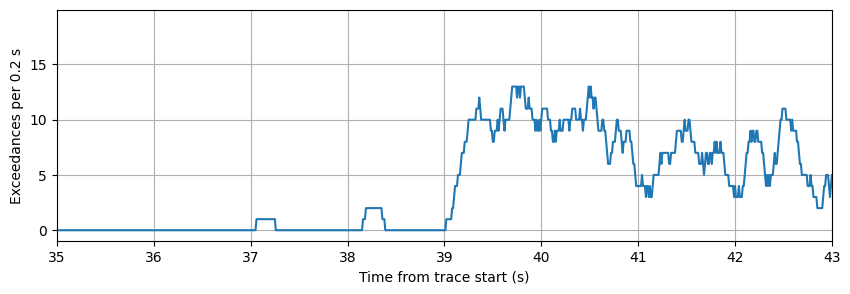

In [38]:

# Count threshold exceedances in 0.2-second windows

exceed_p4 = (diff_p4 > threshold_p4).astype(int)
exceed_count_p4 = exceed_p4.rolling(window=20).sum()

plt.figure(figsize=(10, 3))
plt.plot(time_p4 / 1000, exceed_count_p4)
plt.xlim(35, 43)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Exceedances per 0.2 s")
plt.grid()
plt.show()


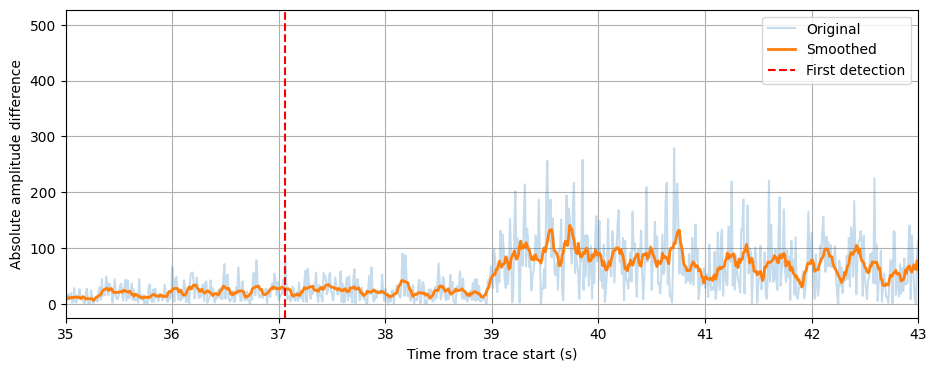

In [39]:

# Smooth absolute first differences (0.1 s)

smooth_p4 = diff_p4.rolling(window=10, center=True).mean()

plt.figure(figsize=(11, 4))
plt.plot(time_p4 / 1000, diff_p4, alpha=0.25, label="Original")
plt.plot(time_p4 / 1000, smooth_p4, linewidth=2, label="Smoothed")
plt.axvline(p_time_ms4 / 1000, color="red", linestyle="--", label="First detection")
plt.xlim(35, 43)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Absolute amplitude difference")
plt.legend()
plt.grid()
plt.show()


In [40]:
p_bulletin_utc4 = "2024-03-14T03:35:09.660000Z"  # Vrijeme P dolaska na CEME iz biltena, u UTC

if p_indices4.size == 0:
    print("Za četvrti događaj nema P kandidata.")
elif not p_bulletin_utc4:
    print(f"Detektovani P (UTC): {p_arrival_utc4}")
    print("Unesi vrijeme P dolaska iz biltena za CEME.")
else:
    p_reference_utc4 = UTCDateTime(p_bulletin_utc4)
    p_error_s4 = p_arrival_utc4 - p_reference_utc4
    print(f"Detektovani P (UTC): {p_arrival_utc4}")
    print(f"P iz biltena (UTC):  {p_reference_utc4}")
    print(f"Odstupanje: {p_error_s4:+.3f} s")

Detektovani P (UTC): 2024-03-14T03:35:09.290000Z
P iz biltena (UTC):  2024-03-14T03:35:09.660000Z
Odstupanje: -0.370 s


In [41]:
p_mask4_after_noise = (
    (time_p4 >= 38000)
    & (time_p4 <= 48000)
    & (diff_p4.to_numpy() > threshold_p4)
)
p_indices4_after_noise = np.flatnonzero(p_mask4_after_noise)

print(f"Pretraga 35–48 s: {p_arrival_utc4} | odstupanje {p_error_s4:+.3f} s")

if p_indices4_after_noise.size:
    first_index = p_indices4_after_noise[0]
    p_arrival_after_noise = tr_p4.stats.starttime + time_p4[first_index] / 1000
    p_error_after_noise = p_arrival_after_noise - p_reference_utc4
    print(
        f"Pretraga 38–48 s: {p_arrival_after_noise} | "
        f"odstupanje {p_error_after_noise:+.3f} s"
    )
else:
    print("Pretraga 38–48 s: nema prelaska praga.")

Pretraga 35–48 s: 2024-03-14T03:35:09.290000Z | odstupanje -0.370 s
Pretraga 38–48 s: 2024-03-14T03:35:10.390000Z | odstupanje +0.730 s


In [42]:
noise_p4_early = diff_p4[(time_p4 >= 30000) & (time_p4 < 35000)]
median_p4_early = noise_p4_early.median()
mad_p4_early = (noise_p4_early - median_p4_early).abs().median()
threshold_p4_early = median_p4_early + 6 * 1.4826 * mad_p4_early

p_indices4_early = np.flatnonzero(
    (time_p4 >= 35000)
    & (time_p4 <= 48000)
    & (diff_p4.to_numpy() > threshold_p4_early)
)

print(f"Prvobitni prag: {threshold_p4:.2f} | odstupanje {p_error_s4:+.3f} s")
print(f"Novi prag: {threshold_p4_early:.2f}")

if p_indices4_early.size:
    p_time_s = time_p4[p_indices4_early[0]] / 1000
    p_arrival_early = tr_p4.stats.starttime + p_time_s
    p_error_early = p_arrival_early - p_reference_utc4
    print(f"Detektovani P (UTC): {p_arrival_early}")
    print(f"Odstupanje: {p_error_early:+.3f} s")
else:
    print("Nema prelaska novog praga u prozoru 35–48 s.")

Prvobitni prag: 84.16 | odstupanje -0.370 s
Novi prag: 83.16
Detektovani P (UTC): 2024-03-14T03:35:09.290000Z
Odstupanje: -0.370 s


In [43]:
first_p4 = p_indices4_early[0]
review_end_ms = (
    p_reference_utc4 - tr_p4.stats.starttime + 0.2
) * 1000

crossings_p4 = p_indices4_early[
    time_p4[p_indices4_early] <= review_end_ms
]

for index in crossings_p4:
    arrival = tr_p4.stats.starttime + time_p4[index] / 1000
    since_first = (time_p4[index] - time_p4[first_p4]) / 1000
    print(
        f"{arrival} | {since_first:.3f} s od prvog prelaska | "
        f"razlika amplitude {diff_p4.iloc[index]:.1f}"
    )

2024-03-14T03:35:09.290000Z | 0.000 s od prvog prelaska | razlika amplitude 85.0


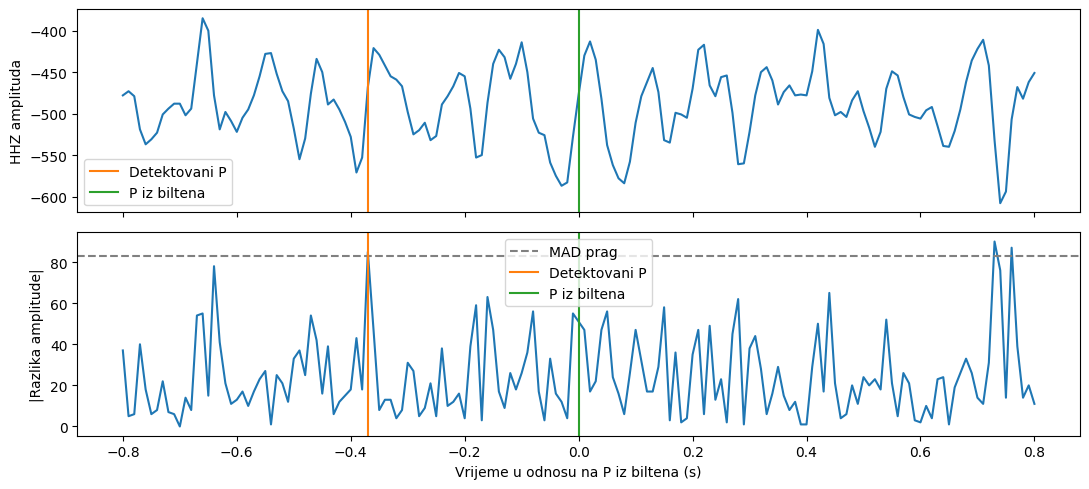

In [44]:
# Vrijeme u sekundama u odnosu na P dolazak iz biltena.
t_rel_p4 = time_p4 / 1000 - (p_reference_utc4 - tr_p4.stats.starttime)
view_p4 = (t_rel_p4 >= -0.8) & (t_rel_p4 <= 0.8)

fig, (ax_wave, ax_diff) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

ax_wave.plot(t_rel_p4[view_p4], amplitude_p4.to_numpy()[view_p4])
ax_wave.set_ylabel("HHZ amplituda")

ax_diff.plot(t_rel_p4[view_p4], diff_p4.to_numpy()[view_p4])
ax_diff.axhline(threshold_p4_early, color="gray", linestyle="--", label="MAD prag")
ax_diff.set_ylabel("|Razlika amplitude|")
ax_diff.set_xlabel("Vrijeme u odnosu na P iz biltena (s)")

for ax in (ax_wave, ax_diff):
    ax.axvline(p_error_early, color="tab:orange", label="Detektovani P")
    ax.axvline(0, color="tab:green", label="P iz biltena")
    ax.legend()

plt.tight_layout()
plt.show()

Fourth event — STA/LTA on the HHZ component

This cell tests whether the vertical waveform shows a rise in signal energy near the bulletin P arrival. It compares the average energy over the preceding 0.2 s with the average over the preceding 3.0 s. The plot shows the existing 35–48 s search window, with time measured relative to the bulletin P arrival. The green line marks the bulletin arrival at 0 s, and the orange line marks the earlier MAD-based pick.

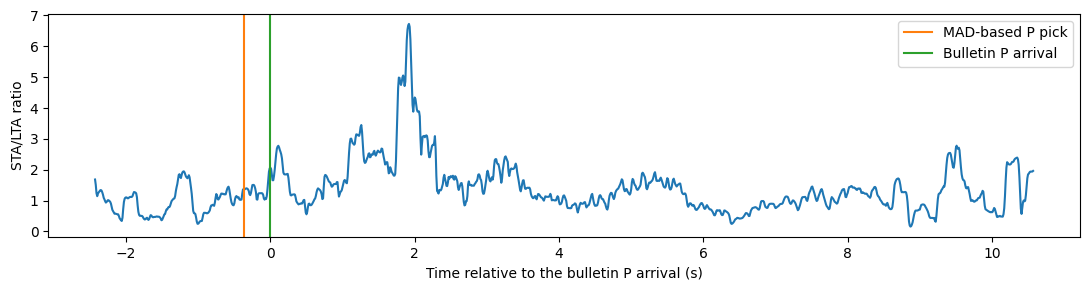

In [45]:
# Convert the short and long window lengths from seconds to samples.
fs_p4 = tr_p4.stats.sampling_rate
sta_samples_p4 = max(1, round(0.2 * fs_p4))
lta_samples_p4 = max(1, round(3.0 * fs_p4))

# Estimate the baseline from the 30–35 s noise window and remove it.
noise_mask_p4 = (time_p4 >= 30000) & (time_p4 < 35000)
baseline_p4 = amplitude_p4[noise_mask_p4].median()
energy_p4 = (amplitude_p4 - baseline_p4) ** 2

# Compute the ratio of short-term to long-term average energy.
sta_p4 = energy_p4.rolling(sta_samples_p4).mean()
lta_p4 = energy_p4.rolling(lta_samples_p4).mean()
ratio_p4 = sta_p4 / lta_p4.where(lta_p4 > 0)

# Plot the ratio within the 35–48 s search window.
search_p4 = (time_p4 >= 35000) & (time_p4 <= 48000)

plt.figure(figsize=(11, 3))
plt.plot(t_rel_p4[search_p4], ratio_p4.to_numpy()[search_p4])
plt.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
plt.axvline(0, color="tab:green", label="Bulletin P arrival")
plt.xlabel("Time relative to the bulletin P arrival (s)")
plt.ylabel("STA/LTA ratio")
plt.legend()
plt.tight_layout()
plt.show()

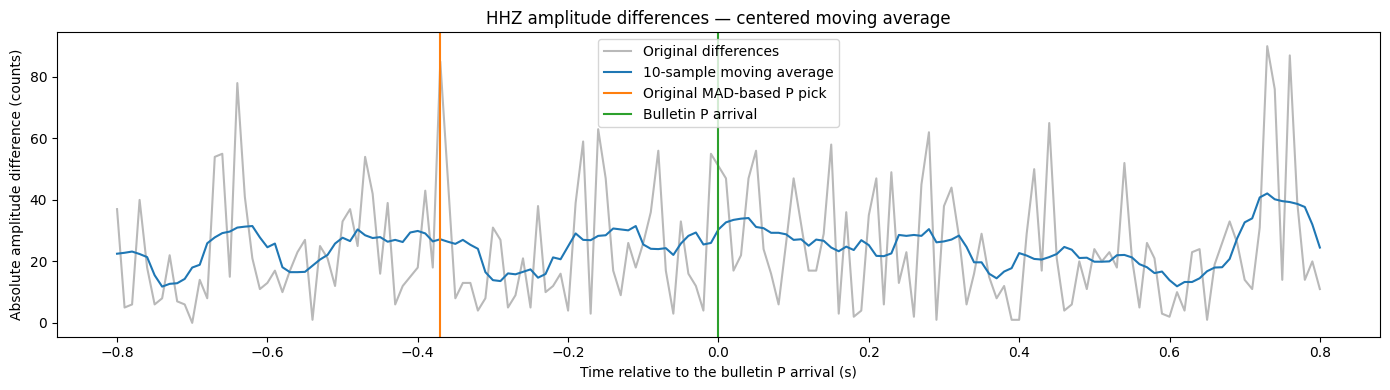

In [46]:
# Smooth the absolute differences with a centered 10-sample moving average.
smooth_p4 = diff_p4.rolling(window=10, center=True).mean()

# Select the same interval for both curves.
view_ma_p4 = (t_rel_p4 >= -0.8) & (t_rel_p4 <= 0.8)

# Plot the original and smoothed differences on the same time axis.
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(
    t_rel_p4[view_ma_p4], diff_p4.to_numpy()[view_ma_p4],
    color="gray", alpha=0.55, label="Original differences",
)
ax.plot(
    t_rel_p4[view_ma_p4], smooth_p4.to_numpy()[view_ma_p4],
    color="tab:blue", label="10-sample moving average",
)
ax.axvline(p_error_early, color="tab:orange", label="Original MAD-based P pick")
ax.axvline(0, color="tab:green", label="Bulletin P arrival")
ax.set_xlabel("Time relative to the bulletin P arrival (s)")
ax.set_ylabel("Absolute amplitude difference (counts)")
ax.set_title("HHZ amplitude differences — centered moving average")
ax.legend()
fig.tight_layout()
plt.show()

### Fourth event — Savitzky–Golay smoothing of HHZ amplitude differences

This cell applies an 11-sample Savitzky–Golay filter with a second-degree polynomial to the same absolute HHZ amplitude differences used for the 10-sample moving average. The plot compares both curves within 0.5 s of the bulletin P arrival. The orange line marks the existing MAD-based pick, and the green line marks the bulletin arrival.

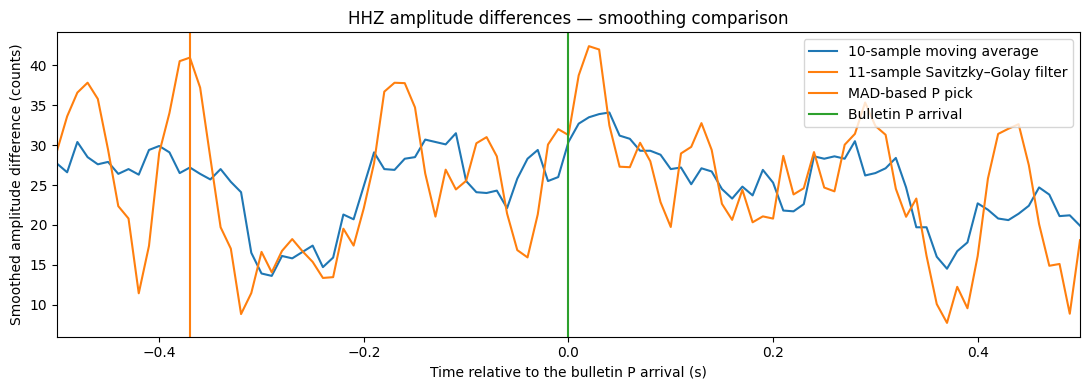

In [47]:
from scipy.signal import savgol_filter

# Smooth the full series of absolute HHZ amplitude differences.
sg_diff_p4 = savgol_filter(diff_p4.to_numpy(), window_length=11, polyorder=2)

# Compare both smoothing methods around the bulletin P arrival.
view_sg_p4 = (t_rel_p4 >= -0.5) & (t_rel_p4 <= 0.5)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    t_rel_p4[view_sg_p4], smooth_p4.to_numpy()[view_sg_p4],
    label="10-sample moving average",
)
ax.plot(
    t_rel_p4[view_sg_p4], sg_diff_p4[view_sg_p4],
    label="11-sample Savitzky–Golay filter",
)
ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
ax.axvline(0, color="tab:green", label="Bulletin P arrival")
ax.set_xlim(-0.5, 0.5)
ax.set_xlabel("Time relative to the bulletin P arrival (s)")
ax.set_ylabel("Smoothed amplitude difference (counts)")
ax.set_title("HHZ amplitude differences — smoothing comparison")
ax.legend()
fig.tight_layout()
plt.show()

### Fourth event — Rolling kurtosis of the HHZ waveform

Savitzky–Golay smoothing of the absolute HHZ amplitude differences produced several peaks of similar height, including one near the earlier MAD-based pick. The P onset remained ambiguous. We now test whether rolling kurtosis on the original HHZ waveform makes the onset easier to identify.

This cell computes excess kurtosis using a trailing window of approximately 0.2 s and plots each value at the end of its window. The upper panel shows the original HHZ waveform, and the lower panel shows rolling kurtosis. The orange line marks the MAD-based P pick, and the green line marks the bulletin P arrival. An isolated spike can also produce a peak in kurtosis.

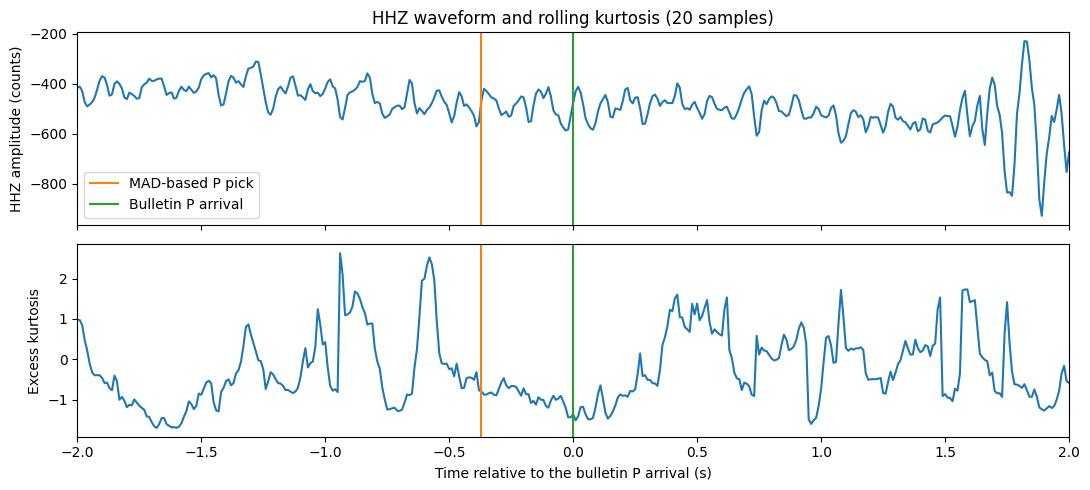

In [48]:
# Convert the kurtosis window from seconds to samples.
fs_p4 = tr_p4.stats.sampling_rate
kurt_window_p4 = max(4, round(0.2 * fs_p4))

# Compute excess kurtosis on the original waveform using a trailing window.
kurt_p4 = amplitude_p4.rolling(window=kurt_window_p4).kurt()

# Select the interval around the bulletin P arrival for display.
view_kurt_p4 = (t_rel_p4 >= -2.0) & (t_rel_p4 <= 2.0)
plot_time_p4 = t_rel_p4[view_kurt_p4]

fig, (ax_wave, ax_kurt) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True
)

ax_wave.plot(plot_time_p4, amplitude_p4.to_numpy()[view_kurt_p4])
ax_wave.set_ylabel("HHZ amplitude (counts)")
ax_wave.set_title(f"HHZ waveform and rolling kurtosis ({kurt_window_p4} samples)")

ax_kurt.plot(plot_time_p4, kurt_p4.to_numpy()[view_kurt_p4])
ax_kurt.set_ylabel("Excess kurtosis")
ax_kurt.set_xlabel("Time relative to the bulletin P arrival (s)")
ax_kurt.set_xlim(-2.0, 2.0)

# Mark the existing P pick and the bulletin arrival in both panels.
for ax in (ax_wave, ax_kurt):
    ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
    ax.axvline(0, color="tab:green", label="Bulletin P arrival")

ax_wave.legend()
fig.tight_layout()
plt.show()

### Fourth event — From rolling kurtosis to Hann smoothing

The 0.2 s rolling kurtosis showed no clear peak at the bulletin P arrival. A rise occurred about 0.4 s later, while two larger peaks were visible before the arrival. We next apply Hann-weighted smoothing to the absolute HHZ amplitude differences and compare it with the ordinary moving average over the same ±2 s display interval.

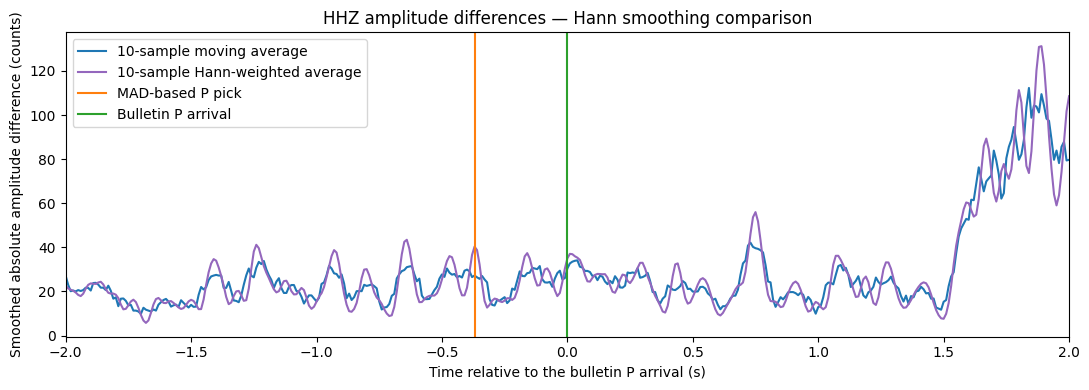

In [49]:
# Normalize the Hann weights so they sum to one.
hann_weights_p4 = np.hanning(10)
hann_weights_p4 /= hann_weights_p4.sum()

# Apply the weights to the same differences used for the moving average.
hann_diff_p4 = diff_p4.rolling(window=10, center=True).apply(
    lambda samples: np.dot(samples, hann_weights_p4),
    raw=True,
)

# Compare the two curves within two seconds of the bulletin P arrival.
view_hann_p4 = (t_rel_p4 >= -2.0) & (t_rel_p4 <= 2.0)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    t_rel_p4[view_hann_p4],
    smooth_p4.to_numpy()[view_hann_p4],
    label="10-sample moving average",
)
ax.plot(
    t_rel_p4[view_hann_p4],
    hann_diff_p4.to_numpy()[view_hann_p4],
    color="tab:purple",
    label="10-sample Hann-weighted average",
)
ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
ax.axvline(0, color="tab:green", label="Bulletin P arrival")
ax.set_xlim(-2, 2)
ax.set_xlabel("Time relative to the bulletin P arrival (s)")
ax.set_ylabel("Smoothed absolute amplitude difference (counts)")
ax.set_title("HHZ amplitude differences — Hann smoothing comparison")
ax.legend()
fig.tight_layout()
plt.show()

### Fourth event — Low-pass filtering of the HHZ waveform

Hann-weighted smoothing did not make the bulletin P onset stand out more clearly than the moving average. This test applies a 15 Hz Butterworth low-pass filter to the HHZ waveform before computing absolute sample-to-sample amplitude differences. The two panels compare the differences from the original and filtered waveforms on the same time and amplitude scales. The bulletin arrival and the existing MAD-based pick serve as reference markers.

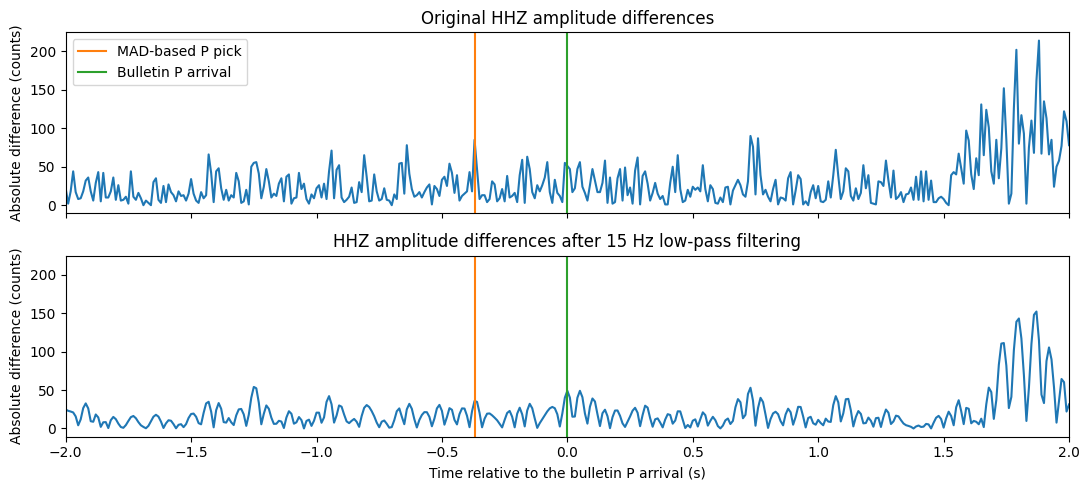

In [50]:
# Filter a copy of the full HHZ trace before selecting the display interval.
tr_lowpass_p4 = tr_p4.copy()
tr_lowpass_p4.filter("lowpass", freq=15.0, corners=4, zerophase=True)

# Compute absolute differences between consecutive filtered samples.
diff_lowpass_p4 = pd.Series(tr_lowpass_p4.data).diff().abs()
view_lowpass_p4 = (t_rel_p4 >= -2.0) & (t_rel_p4 <= 2.0)
plot_time_lowpass_p4 = t_rel_p4[view_lowpass_p4]

# Compare both series on shared time and amplitude scales.
fig, (ax_raw, ax_lowpass) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True, sharey=True
)
ax_raw.plot(plot_time_lowpass_p4, diff_p4.to_numpy()[view_lowpass_p4])
ax_raw.set_title("Original HHZ amplitude differences")

ax_lowpass.plot(
    plot_time_lowpass_p4, diff_lowpass_p4.to_numpy()[view_lowpass_p4]
)
ax_lowpass.set_title("HHZ amplitude differences after 15 Hz low-pass filtering")

# Mark both reference times in each panel.
for ax in (ax_raw, ax_lowpass):
    ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
    ax.axvline(0, color="tab:green", label="Bulletin P arrival")
    ax.set_ylabel("Absolute difference (counts)")

ax_raw.legend()
ax_lowpass.set_xlim(-2.0, 2.0)
ax_lowpass.set_xlabel("Time relative to the bulletin P arrival (s)")
fig.tight_layout()
plt.show()

### Fourth event — Low-pass and band-pass comparison on HHZ

The 15 Hz low-pass filter reduced the spike at the original MAD-based pick. The rise near the bulletin P arrival remained comparable to other local peaks. This cell applies a 1–15 Hz Butterworth band-pass filter to the original HHZ waveform and compares the resulting absolute sample-to-sample differences with those from the 15 Hz low-pass filter. Both panels use the same axes and reference markers.

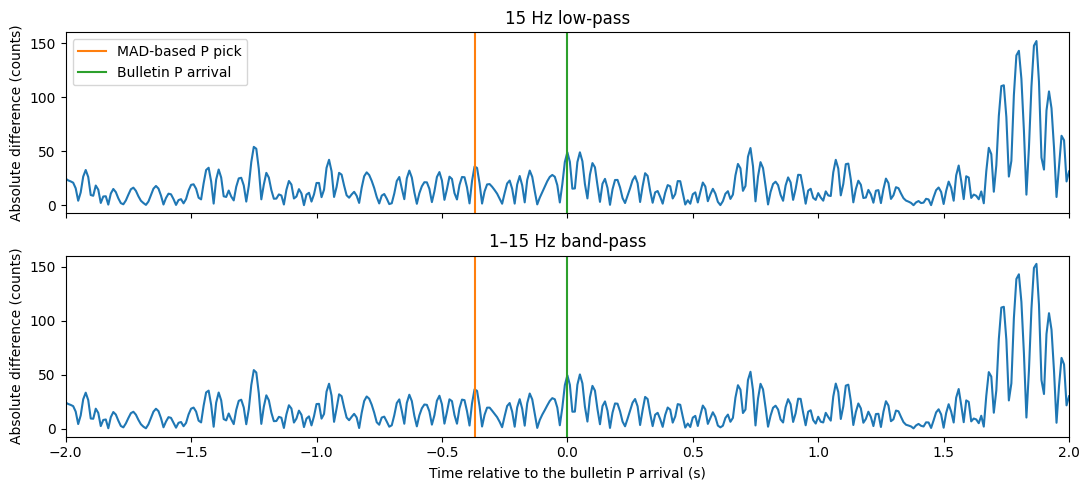

In [51]:
# Apply the band-pass filter to a copy of the original HHZ trace.
tr_bandpass_p4 = tr_p4.copy()
tr_bandpass_p4.filter(
    "bandpass", freqmin=1.0, freqmax=15.0, corners=4, zerophase=True
)

# Compute absolute differences between consecutive filtered samples.
diff_bandpass_p4 = pd.Series(tr_bandpass_p4.data).diff().abs()

# Compare both filtered series over the same four-second interval.
fig, (ax_low, ax_band) = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True, sharey=True
)
ax_low.plot(
    plot_time_lowpass_p4, diff_lowpass_p4.to_numpy()[view_lowpass_p4]
)
ax_low.set_title("15 Hz low-pass")

ax_band.plot(
    plot_time_lowpass_p4, diff_bandpass_p4.to_numpy()[view_lowpass_p4]
)
ax_band.set_title("1–15 Hz band-pass")

# Mark the existing MAD-based pick and the bulletin arrival in both panels.
for ax in (ax_low, ax_band):
    ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
    ax.axvline(0, color="tab:green", label="Bulletin P arrival")
    ax.set_ylabel("Absolute difference (counts)")

ax_low.legend()
ax_band.set_xlim(-2, 2)
ax_band.set_xlabel("Time relative to the bulletin P arrival (s)")
fig.tight_layout()
plt.show()

### Fourth event — Original and low-pass HHZ amplitudes

The 15 Hz low-pass and 1–15 Hz band-pass filters produced similar absolute amplitude differences around the bulletin P arrival. This plot overlays the original and low-pass HHZ amplitudes in counts within 0.5 s of the bulletin arrival to show how filtering changes the waveform near both P markers.

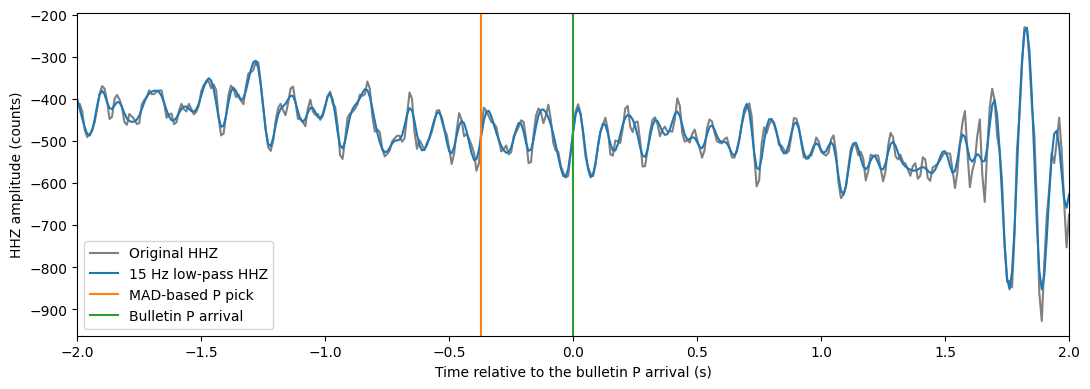

In [52]:
# Select the interval around both P arrival markers.
view_wave_p4 = (t_rel_p4 >= -2.0) & (t_rel_p4 <= 2.0)

# Overlay the original and low-pass HHZ amplitudes in counts.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    t_rel_p4[view_wave_p4], amplitude_p4.to_numpy()[view_wave_p4],
    color="gray", label="Original HHZ",
)
ax.plot(
    t_rel_p4[view_wave_p4], tr_lowpass_p4.data[view_wave_p4],
    color="tab:blue", label="15 Hz low-pass HHZ",
)
ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
ax.axvline(0, color="tab:green", label="Bulletin P arrival")
ax.set_xlim(-2.0, 2.0)
ax.set_xlabel("Time relative to the bulletin P arrival (s)")
ax.set_ylabel("HHZ amplitude (counts)")
ax.legend()
fig.tight_layout()
plt.show()

### Conclusion — Fourth event P arrival at CEME

The original MAD-based detector picked the P arrival at 03:35:09.290 UTC, 0.370 s before the bulletin arrival. Moving the noise window earlier changed the threshold but left the pick time unchanged. Starting the search later excluded the bulletin arrival and produced a pick 0.730 s late.

The moving average, Hann and Savitzky–Golay smoothing, and rolling kurtosis showed local changes around the bulletin arrival, with comparable or stronger features elsewhere in the trace. The 15 Hz low-pass filter smoothed small, rapid fluctuations while preserving the overall HHZ waveform shape near the arrival. The 1–15 Hz band-pass filter produced nearly the same amplitude differences as the low-pass filter.

These visual tests did not establish a clearer P onset for this event. The original MAD pick remains the quantitative baseline for evaluating future detection rules.

### Fourth event — Raw HHZ and 1–3 Hz band-pass comparison

Inspect the raw HHZ waveform first when identifying the P onset manually. If the onset is ambiguous, use the 1–3 Hz band-pass waveform as a secondary view. Both panels show the same time interval, with separate amplitude scales. The orange line marks the existing MAD-based pick, and the green line marks the bulletin arrival.

### Conclusion-Fourth event — Assessment of the 1–3 Hz band-pass filter

The raw HHZ waveform shows a short upward excursion near the bulletin P arrival. In the 1–3 Hz band-pass trace, this feature is less distinct within a broader oscillation. For this event, the raw waveform is the preferred view for manual P picking. The filtered trace serves as a supplementary view.

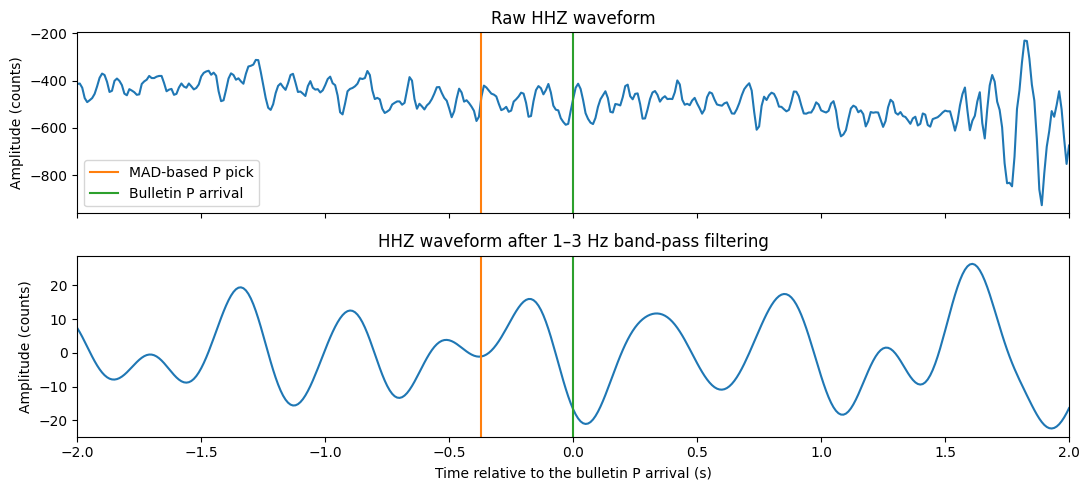

In [53]:
# Apply a third-order 1–3 Hz Butterworth band-pass to a copy of the HHZ trace.
tr_bp_1_3_p4 = tr_p4.copy()
tr_bp_1_3_p4.filter(
    "bandpass", freqmin=1.0, freqmax=3.0, corners=3, zerophase=True
)

# Select the same four-second interval for both waveforms.
view_bp_1_3_p4 = (t_rel_p4 >= -2.0) & (t_rel_p4 <= 2.0)
time_view_p4 = t_rel_p4[view_bp_1_3_p4]

fig, (ax_raw, ax_bp) = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

ax_raw.plot(time_view_p4, amplitude_p4.to_numpy()[view_bp_1_3_p4])
ax_raw.set_title("Raw HHZ waveform")

ax_bp.plot(time_view_p4, tr_bp_1_3_p4.data[view_bp_1_3_p4])
ax_bp.set_title("HHZ waveform after 1–3 Hz band-pass filtering")

# Mark the same reference times in both panels.
for ax in (ax_raw, ax_bp):
    ax.axvline(p_error_early, color="tab:orange", label="MAD-based P pick")
    ax.axvline(0, color="tab:green", label="Bulletin P arrival")
    ax.set_ylabel("Amplitude (counts)")

ax_raw.legend()
ax_bp.set_xlim(-2, 2)
ax_bp.set_xlabel("Time relative to the bulletin P arrival (s)")
fig.tight_layout()
plt.show()

### Fourth event — Manual S pick on the horizontal waveforms

This plot shows the raw HHN and HHE waveforms in counts on a shared time axis. The green line marks the bulletin P arrival at 03:35:09.660 UTC. The purple line marks the manually refined S pick at 03:35:17.320 UTC. Compare both components for a change in waveform amplitude or character near the S marker.

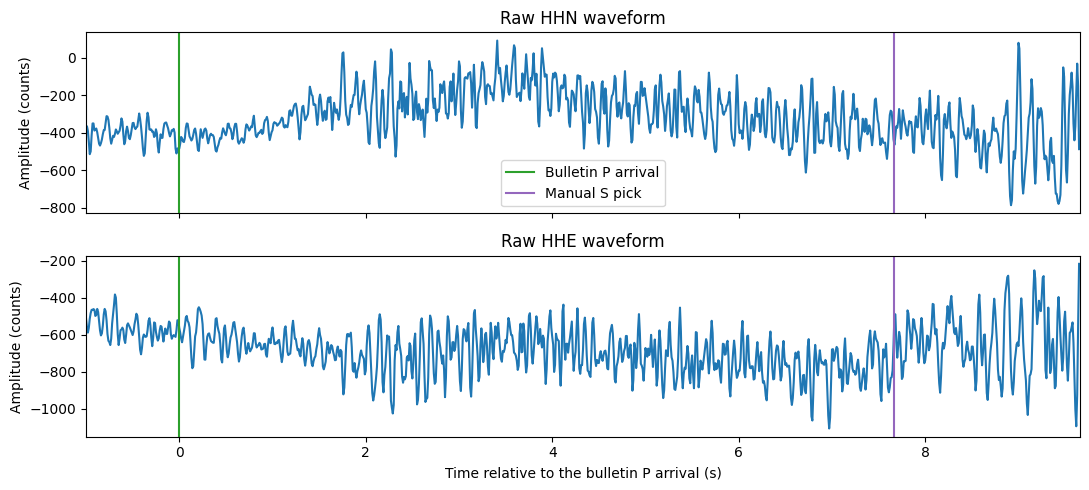

In [54]:
# Define the bulletin P arrival and the manually refined S pick.
s_manual_utc4 = UTCDateTime("2024-03-14T03:35:17.320Z")
s_after_p4 = s_manual_utc4 - p_reference_utc4

# Plot the raw horizontal components using each trace's start time.
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)

for ax, channel in zip(axes, ("HHN", "HHE")):
    tr_horizontal = st_test4.select(channel=channel)[0]
    time_from_p = tr_horizontal.times() + (
        tr_horizontal.stats.starttime - p_reference_utc4
    )
    view = (time_from_p >= -1.0) & (time_from_p <= s_after_p4 + 2.0)

    ax.plot(time_from_p[view], tr_horizontal.data[view])
    ax.axvline(0, color="tab:green", label="Bulletin P arrival")
    ax.axvline(s_after_p4, color="tab:purple", label="Manual S pick")
    ax.set_title(f"Raw {channel} waveform")
    ax.set_ylabel("Amplitude (counts)")

axes[0].legend()
axes[1].set_xlim(-1.0, s_after_p4 + 2.0)
axes[1].set_xlabel("Time relative to the bulletin P arrival (s)")
fig.tight_layout()
plt.show()

### Fourth event — Horizontal waveforms with the mainshock band-pass filter

This cell compares the raw HHN and HHE waveforms with copies processed using the same 1–15 Hz band-pass settings as in the mainshock waveform review. The green line marks the bulletin P arrival, and the purple line marks the manually refined S pick. Use the shared time axis to compare abrupt waveform changes before and around the S marker.

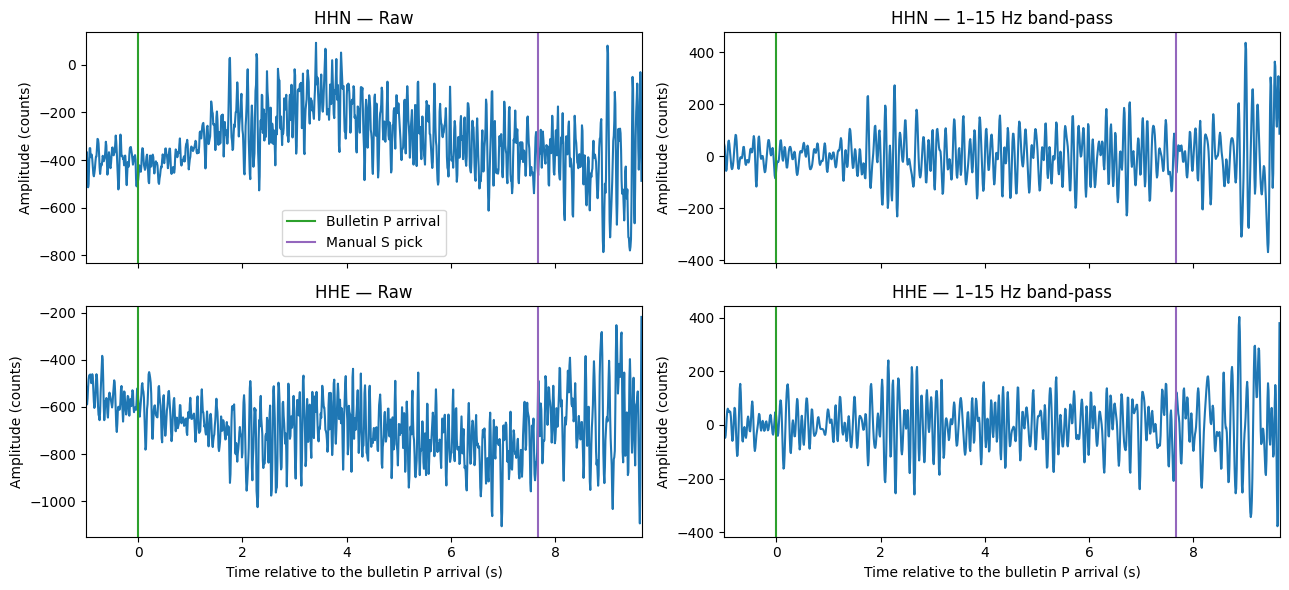

In [55]:
# Apply the same preprocessing used for the mainshock waveform review.
st_s_filtered4 = st_test4.copy()
st_s_filtered4.detrend("demean")
st_s_filtered4.detrend("linear")
st_s_filtered4.filter(
    "bandpass", freqmin=1.0, freqmax=15.0, corners=4, zerophase=True
)

# Compare the raw and filtered horizontal components on a shared time axis.
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)

for row, channel in enumerate(("HHN", "HHE")):
    for col, (stream, label) in enumerate(
        [(st_test4, "Raw"), (st_s_filtered4, "1–15 Hz band-pass")]
    ):
        ax = axes[row, col]
        trace = stream.select(channel=channel)[0]
        time_from_p = trace.times() + (trace.stats.starttime - p_reference_utc4)
        view = (time_from_p >= -1.0) & (time_from_p <= s_after_p4 + 2.0)

        ax.plot(time_from_p[view], trace.data[view])
        ax.axvline(0, color="tab:green", label="Bulletin P arrival")
        ax.axvline(s_after_p4, color="tab:purple", label="Manual S pick")
        ax.set_title(f"{channel} — {label}")
        ax.set_ylabel("Amplitude (counts)")

axes[0, 0].legend()
axes[1, 0].set_xlim(-1.0, s_after_p4 + 2.0)
for ax in axes[1]:
    ax.set_xlabel("Time relative to the bulletin P arrival (s)")
fig.tight_layout()
plt.show()

### Fourth event — Short-term energy and STA/LTA after band-pass filtering

This cell squares the 1–15 Hz band-pass amplitudes and computes trailing energy averages over 0.2 s (STA) and 3.0 s (LTA). It plots the STA and the STA/LTA ratio for each horizontal component. The green line marks the bulletin P arrival, and the purple line marks the manually refined S pick. Inspect when the energy starts to rise, including any rises before the manual S pick.

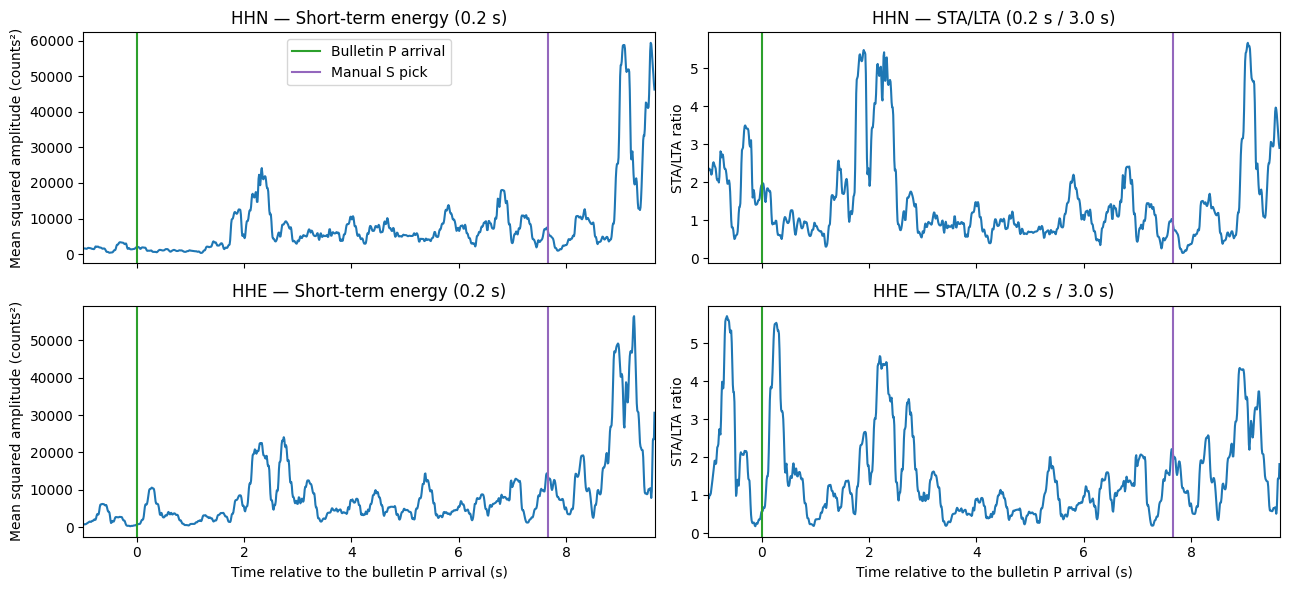

In [56]:
# Plot short-term energy and STA/LTA for both horizontal components.
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)

for row, channel in enumerate(("HHN", "HHE")):
    trace = st_s_filtered4.select(channel=channel)[0]
    fs = trace.stats.sampling_rate
    time_from_p = trace.times() + (
        trace.stats.starttime - p_reference_utc4
    )

    # Square the filtered amplitudes and compute trailing energy averages.
    energy = pd.Series(trace.data.astype(float) ** 2)
    sta = energy.rolling(window=round(0.2 * fs)).mean()
    lta = energy.rolling(window=round(3.0 * fs)).mean()
    ratio = sta / lta.where(lta > 0)

    # Show the full interval from just before P to two seconds after S.
    view = (time_from_p >= -1.0) & (time_from_p <= s_after_p4 + 2.0)
    for ax, values, title, ylabel in (
        (axes[row, 0], sta, "Short-term energy (0.2 s)", "Mean squared amplitude (counts²)"),
        (axes[row, 1], ratio, "STA/LTA (0.2 s / 3.0 s)", "STA/LTA ratio"),
    ):
        ax.plot(time_from_p[view], values.to_numpy()[view])
        ax.axvline(0, color="tab:green", label="Bulletin P arrival")
        ax.axvline(s_after_p4, color="tab:purple", label="Manual S pick")
        ax.set_title(f"{channel} — {title}")
        ax.set_ylabel(ylabel)

axes[0, 0].legend()
axes[0, 0].set_xlim(-1.0, s_after_p4 + 2.0)
for ax in axes[1]:
    ax.set_xlabel("Time relative to the bulletin P arrival (s)")

fig.tight_layout()
plt.show()

### Fourth event — S-phase energy assessment on HHN

HHN is the reference component for S-phase picking. The next test evaluates whether a sustained rise in short-term energy on the 1–15 Hz band-pass HHN waveform can identify an S-onset candidate. The manually refined S pick at 03:35:17.320 UTC serves as the timing reference for evaluating the candidate. HHE provides a supplementary visual comparison.

This test uses the 1–15 Hz band-pass HHN waveform and the existing STA and LTA windows of 0.2 s and 3.0 s. The candidate is the start of the first post-P interval where the STA/LTA ratio stays at or above 2.0 for at least 0.10 s. The manual S pick at 03:35:17.320 UTC is used to evaluate the candidate after selection.

In [57]:
# Compute trailing energy averages on the filtered HHN waveform.
tr_s_hhn4 = st_s_filtered4.select(channel="HHN")[0]
fs_s4 = tr_s_hhn4.stats.sampling_rate
energy_s4 = pd.Series(tr_s_hhn4.data.astype(float) ** 2)

sta_s4 = energy_s4.rolling(round(0.2 * fs_s4)).mean()
lta_s4 = energy_s4.rolling(round(3.0 * fs_s4)).mean()
ratio_s4 = sta_s4 / lta_s4.where(lta_s4 > 0)

# Search from 0.2 to 10 s after the bulletin P arrival.
time_s4_from_p = tr_s_hhn4.times() + (
    tr_s_hhn4.stats.starttime - p_reference_utc4
)
search_s4 = (time_s4_from_p >= 0.2) & (time_s4_from_p <= 10.0)

# Require the ratio to stay at or above the threshold for 0.10 s.
sustain_samples_s4 = int(np.ceil(0.10 * fs_s4))
above_s4 = search_s4 & (ratio_s4.to_numpy() >= 2.0)
run_length_s4 = pd.Series(above_s4).rolling(sustain_samples_s4).sum()
confirmed_s4 = np.flatnonzero(run_length_s4.to_numpy() == sustain_samples_s4)

# Compare the start of the first qualifying run with the manual S pick.
if confirmed_s4.size:
    onset_index_s4 = confirmed_s4[0] - sustain_samples_s4 + 1
    s_candidate_utc4 = (
        tr_s_hhn4.stats.starttime + onset_index_s4 / fs_s4
    )
    s_error_s4 = s_candidate_utc4 - s_manual_utc4
    print(f"HHN S candidate (UTC): {s_candidate_utc4}")
    print(f"Manual S pick (UTC):   {s_manual_utc4}")
    print(f"Candidate minus manual pick: {s_error_s4:+.3f} s")
else:
    print("No sustained HHN energy rise met the threshold in the search window.")

HHN S candidate (UTC): 2024-03-14T03:35:11.400000Z
Manual S pick (UTC):   2024-03-14T03:35:17.320000Z
Candidate minus manual pick: -5.920 s


In [58]:
# Find the start and exclusive end of each above-threshold interval.
edges_s4 = np.diff(np.r_[False, above_s4, False].astype(int))
starts_s4 = np.flatnonzero(edges_s4 == 1)
ends_s4 = np.flatnonzero(edges_s4 == -1)

# Report each interval that met the existing duration requirement.
for start, end in zip(starts_s4, ends_s4):
    if end - start < sustain_samples_s4:
        continue

    start_utc = tr_s_hhn4.stats.starttime + start / fs_s4
    duration_s = (end - start) / fs_s4
    peak_ratio = ratio_s4.iloc[start:end].max()

    print(
        f"{start_utc} | duration {duration_s:.3f} s | "
        f"peak STA/LTA {peak_ratio:.2f} | "
        f"start relative to manual S {start_utc - s_manual_utc4:+.3f} s"
    )

2024-03-14T03:35:11.400000Z | duration 0.270 s | peak STA/LTA 5.47 | start relative to manual S -5.920 s
2024-03-14T03:35:11.680000Z | duration 0.490 s | peak STA/LTA 5.41 | start relative to manual S -5.640 s
2024-03-14T03:35:16.430000Z | duration 0.110 s | peak STA/LTA 2.42 | start relative to manual S -0.890 s
2024-03-14T03:35:18.580000Z | duration 0.340 s | peak STA/LTA 5.66 | start relative to manual S +1.260 s
2024-03-14T03:35:19.090000Z | duration 0.520 s | peak STA/LTA 3.96 | start relative to manual S +1.770 s


### ML 3.2 event — S-arrival detection on HHN

This test applies the same sustained STA/LTA rule used for the fourth event to the ML 3.2 event at CEME. Apply a 1–15 Hz Butterworth band-pass filter to the HHN waveform, then compute short- and long-term averages of the squared amplitudes using 0.2 s and 3.0 s windows.

Search from 0.2 to 10.0 s after the bulletin P arrival. Select the start of the first interval in which STA/LTA stays at or above 2.0 for at least 0.10 s. Record the outcome if no interval qualifies.

Compare the STA/LTA candidate and the previously obtained RMS candidate with the same bulletin S arrival at 03:15:02.840 UTC. Report each signed timing error as the candidate time minus the bulletin time, in seconds.

In [59]:
# Convert the existing HHZ P reference from trace-relative seconds to UTC.
p_reference_ml32 = tr_test.stats.starttime + 37.53
s_reference_ml32 = UTCDateTime("2024-03-14T03:15:02.840Z")

# Apply the fourth-event preprocessing to a copy of the ML 3.2 HHN trace.
tr_hhn_ml32 = st_test.select(channel="HHN")[0].copy()
tr_hhn_ml32.detrend("demean")
tr_hhn_ml32.detrend("linear")
tr_hhn_ml32.filter(
    "bandpass", freqmin=1.0, freqmax=15.0, corners=4, zerophase=True
)

# Compute STA/LTA from trailing averages of squared amplitudes.
fs_ml32 = tr_hhn_ml32.stats.sampling_rate
energy_ml32 = pd.Series(tr_hhn_ml32.data.astype(float) ** 2)
sta_ml32 = energy_ml32.rolling(round(0.2 * fs_ml32)).mean()
lta_ml32 = energy_ml32.rolling(round(3.0 * fs_ml32)).mean()
ratio_ml32 = sta_ml32 / lta_ml32.where(lta_ml32 > 0)

# Require STA/LTA of at least 2.0 for 0.10 s within the post-P search window.
time_from_p_ml32 = tr_hhn_ml32.times() + (
    tr_hhn_ml32.stats.starttime - p_reference_ml32
)
search_ml32 = (time_from_p_ml32 >= 0.2) & (time_from_p_ml32 <= 10.0)
above_ml32 = search_ml32 & (ratio_ml32.to_numpy() >= 2.0)
required_ml32 = int(np.ceil(0.10 * fs_ml32))
run_ml32 = pd.Series(above_ml32).rolling(required_ml32).sum()
confirmed_ml32 = np.flatnonzero(run_ml32.to_numpy() == required_ml32)

# Compare both S candidates with the same bulletin arrival.
print(f"Bulletin S arrival (UTC): {s_reference_ml32}")
print(f"RMS S candidate (UTC): {s_onset_utc_test}")
print(f"RMS timing error: {s_onset_utc_test - s_reference_ml32:+.3f} s")

if confirmed_ml32.size:
    first_ml32 = confirmed_ml32[0] - required_ml32 + 1
    s_stalta_ml32 = tr_hhn_ml32.stats.starttime + first_ml32 / fs_ml32
    print(f"STA/LTA S candidate (UTC): {s_stalta_ml32}")
    print(f"STA/LTA timing error: {s_stalta_ml32 - s_reference_ml32:+.3f} s")
else:
    print("No sustained STA/LTA crossing in the search window.")

Bulletin S arrival (UTC): 2024-03-14T03:15:02.840000Z
RMS S candidate (UTC): 2024-03-14T03:15:02.920000Z
RMS timing error: +0.080 s
STA/LTA S candidate (UTC): 2024-03-14T03:14:54.370000Z
STA/LTA timing error: -8.470 s


### CEME validation set — P- and S-arrival detection

Use the same 10 new earthquakes to evaluate P detection on HHZ and S detection on HHN. Select events in chronological order from the CEME phase table, excluding the four events already inspected during development. Each event must have a reference P and S arrival in UTC. Verify that the HHZ and HHN recordings cover the required analysis windows before finalizing the set.

Evaluate the P detector against the reference P pick. Compare the RMS and STA/LTA S methods in a common search window, first using the reference P pick and then using the automatic P pick. Report signed timing errors, median absolute error, and missing picks for each method.

In [60]:
import pandas as pd

phase_csv = (
    "https://raw.githubusercontent.com/milena-seismo/DSB_capstone/"
    "refs/heads/main/10%20eq_p_s_test.1.csv"
)

# Read the date and the three time columns.
time_columns = {
    "EQ time": "origin_utc",
    "p/phase": "p_ceme_utc",
    "s/phase": "s_ceme_utc",
}
source_picks = pd.read_csv(
    phase_csv, usecols=["date", *time_columns], dtype="string"
)

# Combine the month/day/year date with each time of day.
phase_picks = pd.DataFrame({"event_id": range(1, len(source_picks) + 1)})
event_dates = source_picks["date"].str.strip()
for source_column, target_column in time_columns.items():
    timestamps = event_dates + " " + source_picks[source_column].str.strip()
    phase_picks[target_column] = pd.to_datetime(
        timestamps, format="%m/%d/%Y %H:%M:%S.%f", utc=True, errors="raise"
    )

# Check the phase order before selecting events for waveform checks.
valid_order = (
    (phase_picks["origin_utc"] < phase_picks["p_ceme_utc"])
    & (phase_picks["p_ceme_utc"] < phase_picks["s_ceme_utc"])
)
if not valid_order.all():
    display(phase_picks.loc[~valid_order])
    raise ValueError("Expected origin time < P arrival < S arrival.")

# Sort the validation events and retain their original CSV row IDs.
validation_candidates = phase_picks.sort_values("origin_utc").reset_index(drop=True)

print(f"Events ready for waveform coverage checks: {len(validation_candidates)}")
display(validation_candidates)

Events ready for waveform coverage checks: 10


,event_id,origin_utc,p_ceme_utc,s_ceme_utc
0,1,2024-03-14 03:30:51.580000+00:00,2024-03-14 03:30:59.200000+00:00,2024-03-14 03:31:06.090000+00:00
1,2,2024-03-14 10:48:10.770000+00:00,2024-03-14 10:48:19.040000+00:00,2024-03-14 10:48:26.450000+00:00
2,3,2024-03-14 11:48:04.510000+00:00,2024-03-14 11:48:13.200000+00:00,2024-03-14 11:48:21.420000+00:00
3,4,2024-03-14 12:27:38.030000+00:00,2024-03-14 12:27:46.350000+00:00,2024-03-14 12:27:53.120000+00:00
4,5,2024-03-14 13:31:23.860000+00:00,2024-03-14 13:31:32.520000+00:00,2024-03-14 13:31:40.380000+00:00
5,6,2024-03-14 14:22:47.630000+00:00,2024-03-14 14:22:55.900000+00:00,2024-03-14 14:23:03.620000+00:00
6,7,2024-03-14 15:23:32.460000+00:00,2024-03-14 15:23:40.830000+00:00,2024-03-14 15:23:48.560000+00:00
7,8,2024-03-14 16:32:34.940000+00:00,2024-03-14 16:32:43.980000+00:00,2024-03-14 16:32:51.390000+00:00
8,9,2024-03-14 16:40:19.830000+00:00,2024-03-14 16:40:28.870000+00:00,2024-03-14 16:40:36.720000+00:00
9,10,2024-03-14 16:45:53.910000+00:00,2024-03-14 16:46:02.830000+00:00,2024-03-14 16:46:09.730000+00:00


### CEME validation set — Waveform coverage

Checking whether the CEME daily MiniSEED stream provides continuous HHZ and HHN coverage from 30 s before to 60 s after each catalogue origin. This window includes the pre-event noise interval and the P and S arrivals. Flag events with a missing component, incomplete coverage, or gaps before running the detectors.

In [61]:
import numpy as np
from obspy import UTCDateTime

# Check coverage without filling gaps or changing the daily stream.
def coverage_status(stream, channel, start, end):
    window = stream.select(station="CEME", channel=channel).slice(
        starttime=start, endtime=end
    ).copy()

    if not window:
        return "Missing component"

    # Leave gaps masked when combining segments of the same trace.
    try:
        window.merge(method=0, fill_value=None)
    except ValueError:
        return "Incompatible segments"

    if len(window) != 1:
        return "Multiple trace IDs"

    trace = window[0]
    half_sample = 0.5 / trace.stats.sampling_rate
    if (
        trace.stats.starttime > start + half_sample
        or trace.stats.endtime < end - half_sample
    ):
        return "Incomplete coverage"

    if np.ma.is_masked(trace.data):
        return "Gap or conflicting overlap"

    return "OK"


# Check both reference components for each event.
coverage_rows = []
for event in validation_candidates.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    start, end = origin - 30, origin + 60
    coverage_rows.append({
        "event_id": event.event_id,
        "origin_utc": event.origin_utc,
        "HHZ": coverage_status(st, "HHZ", start, end),
        "HHN": coverage_status(st, "HHN", start, end),
    })

waveform_coverage = pd.DataFrame(coverage_rows)
ready = waveform_coverage[["HHZ", "HHN"]].eq("OK").all(axis=1)

display(waveform_coverage)
print(f"Events with continuous HHZ and HHN coverage: {ready.sum()}/{len(ready)}")

,event_id,origin_utc,HHZ,HHN
0,1,2024-03-14 03:30:51.580000+00:00,OK,OK
1,2,2024-03-14 10:48:10.770000+00:00,OK,OK
2,3,2024-03-14 11:48:04.510000+00:00,OK,OK
3,4,2024-03-14 12:27:38.030000+00:00,OK,OK
4,5,2024-03-14 13:31:23.860000+00:00,OK,OK
5,6,2024-03-14 14:22:47.630000+00:00,OK,OK
6,7,2024-03-14 15:23:32.460000+00:00,OK,OK
7,8,2024-03-14 16:32:34.940000+00:00,OK,OK
8,9,2024-03-14 16:40:19.830000+00:00,OK,OK
9,10,2024-03-14 16:45:53.910000+00:00,OK,OK


Events with continuous HHZ and HHN coverage: 10/10


### CEME validation set — MAD-based P detection on HHZ

Applying the same P detection rule to all ten events. Compute absolute differences between consecutive raw HHZ samples. Estimate the threshold from the first 5 s after the catalogue origin using the median plus six scaled median absolute deviations. Select the first sample above the threshold from 5 to 18 s after the origin. Use the reference P arrival to calculate the signed timing error. Report the median absolute error among detected picks and the number of events without a pick.

In [62]:
from IPython.display import display

p_rows = []

for event in validation_candidates.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    reference_p = UTCDateTime(event.p_ceme_utc.to_pydatetime())

    # Extract the continuous raw HHZ window checked in the previous cell.
    hhz_window = st.select(station="CEME", channel="HHZ").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    hhz_window.merge(method=0, fill_value=None)
    trace = hhz_window[0]

    # Align each amplitude difference with the later of its two samples.
    time_from_origin = trace.times()[1:] + (trace.stats.starttime - origin)
    differences = np.abs(np.diff(trace.data.astype(float)))

    # Estimate the MAD threshold in the fixed reference window.
    noise = differences[(time_from_origin >= 0) & (time_from_origin < 5)]
    median_noise = np.median(noise)
    mad_noise = np.median(np.abs(noise - median_noise))
    threshold = median_noise + 6 * 1.4826 * mad_noise

    # Select the first threshold crossing in the fixed P search window.
    crossings = np.flatnonzero(
        (time_from_origin >= 5)
        & (time_from_origin <= 18)
        & (differences > threshold)
    )

    automatic_p = pd.NaT
    error_s = np.nan
    if crossings.size:
        sample_index = crossings[0] + 1
        pick = trace.stats.starttime + sample_index / trace.stats.sampling_rate
        automatic_p = pd.Timestamp(pick.datetime, tz="UTC")
        error_s = pick - reference_p

    p_rows.append({
        "event_id": event.event_id,
        "p_reference_utc": event.p_ceme_utc,
        "p_automatic_utc": automatic_p,
        "p_error_s": error_s,
        "mad_threshold_counts": threshold,
    })

p_validation_results = pd.DataFrame(p_rows)
errors = p_validation_results["p_error_s"].dropna()

display(p_validation_results.round({
    "p_error_s": 3,
    "mad_threshold_counts": 2,
}))
print(f"Events with a P pick: {len(errors)}/{len(p_validation_results)}")
print(f"Events without a P pick: {len(p_validation_results) - len(errors)}")
if not errors.empty:
    print(f"Median absolute P timing error: {errors.abs().median():.3f} s")

,event_id,p_reference_utc,p_automatic_utc,p_error_s,mad_threshold_counts
0,1,2024-03-14 03:30:59.200000+00:00,2024-03-14 03:30:59.660000+00:00,0.46,667.98
1,2,2024-03-14 10:48:19.040000+00:00,2024-03-14 10:48:19.170000+00:00,0.13,20.79
2,3,2024-03-14 11:48:13.200000+00:00,2024-03-14 11:48:10.590000+00:00,-2.61,10.90
3,4,2024-03-14 12:27:46.350000+00:00,2024-03-14 12:27:46.680000+00:00,0.33,21.79
4,5,2024-03-14 13:31:32.520000+00:00,2024-03-14 13:31:31.420000+00:00,-1.10,26.74
5,6,2024-03-14 14:22:55.900000+00:00,2024-03-14 14:22:56.410000+00:00,0.51,21.79
6,7,2024-03-14 15:23:40.830000+00:00,2024-03-14 15:23:40.860000+00:00,0.03,20.79
7,8,2024-03-14 16:32:43.980000+00:00,2024-03-14 16:32:43.570000+00:00,-0.41,10.90
8,9,2024-03-14 16:40:28.870000+00:00,2024-03-14 16:40:25.990000+00:00,-2.88,10.90
9,10,2024-03-14 16:46:02.830000+00:00,2024-03-14 16:46:03.080000+00:00,0.25,10.90


Events with a P pick: 10/10
Events without a P pick: 0
Median absolute P timing error: 0.435 s


### CEME validation set — S-arrival comparison on HHN

Comparing two S-picking methods on the same ten earthquakes. The RMS method uses raw HHN, a 0.2 s rolling RMS, a 0.1 s change smoothed over 0.1 s, and a lookback of up to 0.3 s from the strongest rise to a preceding RMS minimum. The STA/LTA method uses 1–15 Hz band-pass HHN and selects the first interval with a ratio of at least 2.0 for 0.10 s. Both methods search from 0.2 to 10.0 s after the P pick. Run each method with the reference P and the automatic P, then evaluate the S candidates against the reference S times.

In [63]:
s_rows = []
automatic_p_by_event = p_validation_results.set_index("event_id")["p_automatic_utc"]

for event in validation_candidates.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    reference_s = UTCDateTime(event.s_ceme_utc.to_pydatetime())

    # Extract the continuous HHN window verified in the coverage check.
    hhn_window = st.select(station="CEME", channel="HHN").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    hhn_window.merge(method=0, fill_value=None)
    trace = hhn_window[0]
    fs = trace.stats.sampling_rate
    time = trace.times()

    # Compute the RMS rise on raw HHN using the earlier ML 3.2 settings.
    raw_energy = pd.Series(trace.data.astype(float) ** 2)
    rms = np.sqrt(raw_energy.rolling(int(0.2 * fs)).mean())
    lag = int(0.1 * fs)
    rms_rise = rms.diff(lag).rolling(lag).mean().to_numpy()
    lookback = int(0.3 * fs)

    # Compute STA/LTA on a detrended, band-pass filtered copy.
    filtered = trace.copy()
    filtered.detrend("demean")
    filtered.detrend("linear")
    filtered.filter(
        "bandpass", freqmin=1.0, freqmax=15.0, corners=4, zerophase=True
    )
    energy = pd.Series(filtered.data.astype(float) ** 2)
    sta = energy.rolling(round(0.2 * fs)).mean()
    lta = energy.rolling(round(3.0 * fs)).mean()
    ratio = (sta / lta.where(lta > 0)).to_numpy()
    sustain = int(np.ceil(0.10 * fs))

    # Repeat the comparison with each P anchor.
    for anchor, p_time in (
        ("Reference P", event.p_ceme_utc),
        ("Automatic P", automatic_p_by_event.get(event.event_id, pd.NaT)),
    ):
        rms_index = stalta_index = None

        if pd.notna(p_time):
            p_utc = UTCDateTime(p_time.to_pydatetime())
            time_from_p = time + (trace.stats.starttime - p_utc)
            search = (time_from_p >= 0.2) & (time_from_p <= 10.0)

            # Find the strongest positive RMS rise and refine within the search window.
            rms_candidates = np.flatnonzero(search & (rms_rise > 0))
            if rms_candidates.size:
                peak = rms_candidates[np.argmax(rms_rise[rms_candidates])]
                start = max(np.flatnonzero(search)[0], peak - lookback)
                rms_index = rms.iloc[start:peak + 1].idxmin()

            # Find the start of the first sustained STA/LTA crossing.
            above = search & (ratio >= 2.0)
            run = pd.Series(above).rolling(sustain).sum().to_numpy()
            confirmed = np.flatnonzero(run == sustain)
            if confirmed.size:
                stalta_index = confirmed[0] - sustain + 1

        for method, index in (("RMS", rms_index), ("STA/LTA", stalta_index)):
            pick_utc = pd.NaT
            error_s = np.nan
            if index is not None:
                pick = trace.stats.starttime + index / fs
                pick_utc = pd.Timestamp(pick.datetime, tz="UTC")
                error_s = pick - reference_s

            s_rows.append({
                "event_id": event.event_id,
                "p_anchor": anchor,
                "method": method,
                "s_reference_utc": event.s_ceme_utc,
                "s_automatic_utc": pick_utc,
                "s_error_s": error_s,
            })

s_validation_results = pd.DataFrame(s_rows)
s_summary = (
    s_validation_results.assign(abs_error_s=lambda table: table["s_error_s"].abs())
    .groupby(["p_anchor", "method"], sort=False)
    .agg(
        events=("event_id", "size"),
        picks=("s_error_s", "count"),
        median_abs_error_s=("abs_error_s", "median"),
    )
)
s_summary["missing_picks"] = s_summary["events"] - s_summary["picks"]

display(s_validation_results.round({"s_error_s": 3}))
display(s_summary.round(3))

,event_id,p_anchor,method,s_reference_utc,s_automatic_utc,s_error_s
0,1,Reference P,RMS,2024-03-14 03:31:06.090000+00:00,2024-03-14 03:31:08.470000+00:00,2.38
1,1,Reference P,STA/LTA,2024-03-14 03:31:06.090000+00:00,2024-03-14 03:30:59.490000+00:00,-6.60
2,1,Automatic P,RMS,2024-03-14 03:31:06.090000+00:00,2024-03-14 03:31:09.450000+00:00,3.36
3,1,Automatic P,STA/LTA,2024-03-14 03:31:06.090000+00:00,2024-03-14 03:30:59.860000+00:00,-6.23
4,2,Reference P,RMS,2024-03-14 10:48:26.450000+00:00,2024-03-14 10:48:28.320000+00:00,1.87
5,2,Reference P,STA/LTA,2024-03-14 10:48:26.450000+00:00,2024-03-14 10:48:19.250000+00:00,-7.20
6,2,Automatic P,RMS,2024-03-14 10:48:26.450000+00:00,2024-03-14 10:48:28.320000+00:00,1.87
7,2,Automatic P,STA/LTA,2024-03-14 10:48:26.450000+00:00,2024-03-14 10:48:19.370000+00:00,-7.08
8,3,Reference P,RMS,2024-03-14 11:48:21.420000+00:00,2024-03-14 11:48:23.050000+00:00,1.63
9,3,Reference P,STA/LTA,2024-03-14 11:48:21.420000+00:00,2024-03-14 11:48:13.400000+00:00,-8.02


events  picks  median_abs_error_s  missing_picks
p_anchor    method                                                   
Reference P RMS          10     10               1.805              0
            STA/LTA      10     10               7.245              0
Automatic P RMS          10     10               1.980              0
            STA/LTA      10     10               7.290              0

 ### Conclusion CEME validation — P- and S-arrival results

The raw HHZ MAD detector returned a P candidate for all ten events, with a median absolute timing error of 0.435 s. On HHN, RMS yielded median absolute S timing errors of 1.805 s with reference P picks and 1.980 s with automatic P picks. The sustained STA/LTA rule yielded errors of 7.245 s and 7.290 s, respectively. Both S methods returned a candidate for every event. RMS performed better on this set, while substantial S timing errors persisted even when the search window was anchored to the reference P arrival.

### Reference catalogue — Čarađe events on 14 March 2024

Select all events from the cleaned Čarađe catalogue with origin times on 14 March 2024 UTC, using the study area defined in the exploratory analysis. Retain the event identifiers, origin times, and epicentral coordinates. This subset serves as the reference for evaluating detections from the continuous CEME waveform.

In [64]:
# Define the UTC day used for continuous detection.
catalogue_day_start = pd.Timestamp("2024-03-14", tz="UTC")
catalogue_day_end = catalogue_day_start + pd.Timedelta(days=1)

# Select local catalogue events by origin time and preserve their index.
origin = caradje_march["origin_datetime"]
catalogue_14mar = caradje_march.loc[
    (origin >= catalogue_day_start) & (origin < catalogue_day_end),
    ["origin_datetime", "latitude_deg", "longitude_deg"],
].sort_values("origin_datetime")

print(f"Local catalogue events on 14 March: {len(catalogue_14mar)}")
display(catalogue_14mar.head())

Local catalogue events on 14 March: 131


,origin_datetime,latitude_deg,longitude_deg
414,2024-03-14 03:06:46.300000+00:00,42.9761,18.6537
283,2024-03-14 03:14:46.430000+00:00,42.9856,18.6770
284,2024-03-14 03:19:24.970000+00:00,42.9538,18.6537
403,2024-03-14 03:19:25.690000+00:00,42.9829,18.6826
404,2024-03-14 03:20:37.440000+00:00,42.9315,18.6552


In [74]:
catalogue_14mar.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131 entries, 414 to 402
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   origin_datetime  131 non-null    datetime64[ns, UTC]
 1   latitude_deg     131 non-null    float64            
 2   longitude_deg    131 non-null    float64            
dtypes: datetime64[ns, UTC](1), float64(2)
memory usage: 4.1 KB


In [75]:
# Extract the CEME HHZ data for the target UTC day.
day_start = UTCDateTime("2024-03-14T00:00:00Z")
day_end = day_start + 24 * 60 * 60
hhz_day = st.select(station="CEME", channel="HHZ").slice(
    starttime=day_start, endtime=day_end
).copy()

if not hhz_day:
    raise ValueError("No CEME HHZ data found for 14 March 2024.")

# Combine compatible records and split at gaps or conflicting overlaps.
hhz_day.merge(method=0, fill_value=None)
hhz_segments = hhz_day.split()

candidate_rows = []

for trace in hhz_segments:
    fs = trace.stats.sampling_rate
    noise_samples = round(5.0 * fs)
    block_samples = round(fs)
    group_gap_samples = round(0.5 * fs)

    # Difference index i corresponds to waveform sample i + 1.
    differences = np.abs(np.diff(trace.data.astype(float)))
    previous_crossing = None

    for start in range(noise_samples, len(differences), block_samples):
        end = start + block_samples
        noise = differences[start - noise_samples:start]
        median_noise = np.median(noise)
        mad_noise = np.median(np.abs(noise - median_noise))
        threshold = median_noise + 6 * 1.4826 * mad_noise

        # Carry the crossing group across block boundaries.
        crossings = start + np.flatnonzero(differences[start:end] > threshold)
        for index in crossings:
            if previous_crossing is None or index - previous_crossing > group_gap_samples:
                pick = trace.stats.starttime + (index + 1) / fs
                if day_start <= pick < day_end:
                    candidate_rows.append({
                        "p_candidate_utc": pd.Timestamp(pick.datetime, tz="UTC"),
                        "threshold_counts": threshold,
                        "difference_counts": differences[index],
                    })

            previous_crossing = index

continuous_p_candidates = pd.DataFrame(
    candidate_rows,
    columns=["p_candidate_utc", "threshold_counts", "difference_counts"],
).sort_values("p_candidate_utc", ignore_index=True)

print(f"Continuous HHZ segments scanned: {len(hhz_segments)}")
print(f"P candidates after grouping: {len(continuous_p_candidates)}")
display(continuous_p_candidates.head(10))

Continuous HHZ segments scanned: 1
P candidates after grouping: 7471


,p_candidate_utc,threshold_counts,difference_counts
0,2024-03-14 00:02:15.950000+00:00,10.8956,11.0
1,2024-03-14 00:02:59.810000+00:00,5.9478,8.0
2,2024-03-14 00:03:02.570000+00:00,10.8956,11.0
3,2024-03-14 00:03:03.750000+00:00,10.8956,11.0
4,2024-03-14 00:03:07.260000+00:00,10.8956,14.0
5,2024-03-14 00:05:23.890000+00:00,10.8956,12.0
6,2024-03-14 00:05:26.380000+00:00,10.8956,11.0
7,2024-03-14 00:06:03.640000+00:00,5.9478,6.0
8,2024-03-14 00:09:28.390000+00:00,10.8956,11.0
9,2024-03-14 00:10:15.240000+00:00,10.8956,11.0


### Continuous P detection — Check against ten reference arrivals

For each known CEME P arrival, count the candidates from the continuous HHZ scan within ±0.5 s. When the window contains a candidate, report the closest one and its signed timing error. The count shows whether the detector produced any nearby candidate and whether multiple candidates compete within the same window.

In [76]:
# Check the continuous candidates against the ten reference P arrivals.
tolerance_p = pd.Timedelta(seconds=0.5)
candidate_times = continuous_p_candidates["p_candidate_utc"]
check_rows = []

for event in validation_candidates.itertuples(index=False):
    offsets = candidate_times - event.p_ceme_utc
    nearby = offsets.loc[offsets.abs() <= tolerance_p]

    closest_time = pd.NaT
    error_s = np.nan
    if not nearby.empty:
        closest_index = nearby.abs().idxmin()
        closest_time = candidate_times.loc[closest_index]
        error_s = nearby.loc[closest_index].total_seconds()

    check_rows.append({
        "event_id": event.event_id,
        "reference_p_utc": event.p_ceme_utc,
        "closest_candidate_utc": closest_time,
        "signed_error_s": error_s,
        "candidates_within_0_5_s": len(nearby),
    })

continuous_p_check = pd.DataFrame(check_rows)
hits = continuous_p_check["candidates_within_0_5_s"].gt(0).sum()

display(continuous_p_check.round({"signed_error_s": 3}))
print(f"Reference P arrivals with a candidate within ±0.5 s: {hits}/{len(continuous_p_check)}")

,event_id,reference_p_utc,closest_candidate_utc,signed_error_s,candidates_within_0_5_s
0,1,2024-03-14 03:30:59.200000+00:00,2024-03-14 03:30:59.650000+00:00,0.45,1
1,2,2024-03-14 10:48:19.040000+00:00,2024-03-14 10:48:19.170000+00:00,0.13,1
2,3,2024-03-14 11:48:13.200000+00:00,2024-03-14 11:48:13.090000+00:00,-0.11,1
3,4,2024-03-14 12:27:46.350000+00:00,2024-03-14 12:27:46.680000+00:00,0.33,1
4,5,2024-03-14 13:31:32.520000+00:00,2024-03-14 13:31:32.640000+00:00,0.12,1
5,6,2024-03-14 14:22:55.900000+00:00,NaT,NaN,0
6,7,2024-03-14 15:23:40.830000+00:00,2024-03-14 15:23:40.790000+00:00,-0.04,1
7,8,2024-03-14 16:32:43.980000+00:00,2024-03-14 16:32:44.160000+00:00,0.18,2
8,9,2024-03-14 16:40:28.870000+00:00,2024-03-14 16:40:28.650000+00:00,-0.22,1
9,10,2024-03-14 16:46:02.830000+00:00,2024-03-14 16:46:03.080000+00:00,0.25,1


Reference P arrivals with a candidate within ±0.5 s: 9/10


### Continuous detection — Inspecting the HHN RMS rise near S arrivals

For each reference event with a nearby continuous P candidate, compute the 0.2 s rolling RMS on raw HHN. Measure the RMS change over 0.1 s and smooth that change over 0.1 s, as in the previous tests. Compare the strongest rise from 0.2 to 10 s after the automatic P candidate with the strongest rise within ±0.5 s of the reference S arrival. The reference S window is used only for this diagnostic comparison.

In [77]:
# Keep the events with an automatic P candidate from the continuous scan.
matched_p = continuous_p_check.dropna(subset=["closest_candidate_utc"])
s_checks = matched_p.merge(
    validation_candidates[["event_id", "origin_utc", "s_ceme_utc"]],
    on="event_id",
    validate="one_to_one",
)

rms_rows = []

for event in s_checks.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    automatic_p = UTCDateTime(event.closest_candidate_utc.to_pydatetime())
    reference_s = UTCDateTime(event.s_ceme_utc.to_pydatetime())

    # Use the raw HHN window verified in the coverage check.
    window = st.select(station="CEME", channel="HHN").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    window.merge(method=0, fill_value=None)
    trace = window[0]
    fs = trace.stats.sampling_rate

    # Compute the smoothed RMS change using the existing settings.
    energy = pd.Series(trace.data.astype(float) ** 2)
    rms = np.sqrt(energy.rolling(int(0.2 * fs)).mean())
    lag = int(0.1 * fs)
    rise = rms.diff(lag).rolling(lag).mean().to_numpy()

    # Identify the automatic search interval and the diagnostic S interval.
    time_from_p = trace.times() + (trace.stats.starttime - automatic_p)
    time_from_s = trace.times() + (trace.stats.starttime - reference_s)
    positive_rise = np.isfinite(rise) & (rise > 0)
    search = (time_from_p >= 0.2) & (time_from_p <= 10.0) & positive_rise
    near_s = (np.abs(time_from_s) <= 0.5) & positive_rise

    peak_offset_s = np.nan
    if search.any():
        search_indices = np.flatnonzero(search)
        peak = search_indices[np.argmax(rise[search_indices])]
        peak_offset_s = time_from_s[peak]

    rms_rows.append({
        "event_id": event.event_id,
        "reference_s_in_search": 0.2 <= reference_s - automatic_p <= 10.0,
        "search_peak_relative_to_s_s": peak_offset_s,
        "max_rms_rise_in_search_counts": rise[search].max() if search.any() else np.nan,
        "max_rms_rise_near_s_counts": rise[near_s].max() if near_s.any() else np.nan,
    })

s_rms_diagnostics = pd.DataFrame(rms_rows)
display(s_rms_diagnostics.round(3))

,event_id,reference_s_in_search,search_peak_relative_to_s_s,max_rms_rise_in_search_counts,max_rms_rise_near_s_counts
0,1,True,3.54,6051.967,1455.950
1,2,True,2.09,1184.051,532.076
2,3,True,-4.15,2452.772,1590.500
3,4,True,0.85,117.610,33.410
4,5,True,1.83,3609.682,1138.756
5,7,True,2.00,245.002,137.045
6,8,True,1.92,398.534,49.982
7,9,True,1.26,338.797,98.916
8,10,True,2.34,57.561,43.152


### Continuous detection — HHN RMS diagnostic results

All nine reference S arrivals fell within the search window anchored to the automatic P candidates. The strongest smoothed RMS rise fell outside ±0.5 s of the reference S arrival in all nine cases. It occurred after the reference S arrival in eight cases and before it in one. These offsets describe the timing of the RMS-rise peaks. The next check examines the waveform and RMS rise together to assess whether a smaller, sustained change marks the S onset.

### Continuous detection — RMS-based S picks on HHN

Apply the existing RMS rule to events with a matched P candidate from the continuous scan. Find the strongest smoothed RMS rise from 0.2 to 10.0 s after the automatic P pick. Use the preceding RMS minimum within a 0.3 s lookback as the S candidate, keeping the lookback inside the search window. Report the automatic S pick, the reference S arrival, and the signed timing error.

In [78]:
s_pick_rows = []

for event in s_checks.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    automatic_p = UTCDateTime(event.closest_candidate_utc.to_pydatetime())
    reference_s = UTCDateTime(event.s_ceme_utc.to_pydatetime())

    # Extract the raw HHN window verified in the coverage check.
    window = st.select(station="CEME", channel="HHN").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    window.merge(method=0, fill_value=None)
    trace = window[0]
    fs = trace.stats.sampling_rate

    # Compute the 0.2 s RMS and the smoothed 0.1 s RMS change.
    energy = pd.Series(trace.data.astype(float) ** 2)
    rms = np.sqrt(energy.rolling(int(0.2 * fs)).mean())
    lag = int(0.1 * fs)
    rise = rms.diff(lag).rolling(lag).mean().to_numpy()

    # Search for the strongest positive rise after the automatic P pick.
    time_from_p = trace.times() + (trace.stats.starttime - automatic_p)
    search = (time_from_p >= 0.2) & (time_from_p <= 10.0)
    rising = np.flatnonzero(search & np.isfinite(rise) & (rise > 0))

    s_automatic = pd.NaT
    error_s = np.nan

    if rising.size:
        peak = rising[np.argmax(rise[rising])]

        # Pick the preceding RMS minimum within the 0.3 s lookback.
        start = max(np.flatnonzero(search)[0], peak - int(0.3 * fs))
        onset = rms.iloc[start:peak + 1].idxmin()
        pick = trace.stats.starttime + onset / fs
        s_automatic = pd.Timestamp(pick.datetime, tz="UTC")
        error_s = pick - reference_s

    s_pick_rows.append({
        "event_id": event.event_id,
        "s_automatic_utc": s_automatic,
        "s_reference_utc": event.s_ceme_utc,
        "s_error_s": error_s,
    })

continuous_s_check = pd.DataFrame(s_pick_rows)
display(continuous_s_check.round({"s_error_s": 3}))

,event_id,s_automatic_utc,s_reference_utc,s_error_s
0,1,2024-03-14 03:31:09.450000+00:00,2024-03-14 03:31:06.090000+00:00,3.36
1,2,2024-03-14 10:48:28.320000+00:00,2024-03-14 10:48:26.450000+00:00,1.87
2,3,2024-03-14 11:48:17.090000+00:00,2024-03-14 11:48:21.420000+00:00,-4.33
3,4,2024-03-14 12:27:53.670000+00:00,2024-03-14 12:27:53.120000+00:00,0.55
4,5,2024-03-14 13:31:41.910000+00:00,2024-03-14 13:31:40.380000+00:00,1.53
5,7,2024-03-14 15:23:50.380000+00:00,2024-03-14 15:23:48.560000+00:00,1.82
6,8,2024-03-14 16:32:53.180000+00:00,2024-03-14 16:32:51.390000+00:00,1.79
7,9,2024-03-14 16:40:37.780000+00:00,2024-03-14 16:40:36.720000+00:00,1.06
8,10,2024-03-14 16:46:11.820000+00:00,2024-03-14 16:46:09.730000+00:00,2.09


### ML 3.2 event — Effect of the search window on the RMS S pick

This test checks whether the earlier RMS timing error of +0.080 s depends on the S search window. Both runs use the same raw HHN waveform, the same 0.2 s rolling RMS, and the same smoothed 0.1 s RMS change. In each run, select the strongest rise within the search window and use the preceding RMS minimum within a 0.3 s lookback to estimate the S onset.

- **Original narrow window** — Search from 45.0 to 48.0 s after the start of the HHN trace.
- **Broader post-P window** — Search from 0.2 to 10.0 s after the reference P arrival.

Compare both S picks with the same bulletin S arrival at **03:15:02.840 UTC**. Report the signed timing error as the estimated arrival minus the bulletin arrival. The search window is the only parameter varied between the two runs.

In [79]:
# Use the P marker from the original HHZ plot and the bulletin S arrival.
p_reference_ml32 = tr_test.stats.starttime + 37.53
s_reference_ml32 = UTCDateTime("2024-03-14T03:15:02.840Z")

# Build both time axes from the same raw HHN trace.
time_from_hhn_start = tr_s_test.times()
time_from_p = time_from_hhn_start + (
    tr_s_test.stats.starttime - p_reference_ml32
)
rms_rise = s_smooth_test.to_numpy()
lookback_samples = int(0.3 * tr_s_test.stats.sampling_rate)

search_windows = {
    "Original window (45–48 s from HHN start)": (
        (time_from_hhn_start >= 45.0) & (time_from_hhn_start <= 48.0)
    ),
    "Broad window (0.2–10 s after reference P)": (
        (time_from_p >= 0.2) & (time_from_p <= 10.0)
    ),
}

# Apply the original RMS picking rule to each window.
print(f"Bulletin S arrival (UTC): {s_reference_ml32}")

for label, search in search_windows.items():
    valid_indices = np.flatnonzero(search & np.isfinite(rms_rise))
    print(f"\n{label}")

    if valid_indices.size == 0:
        print("No valid RMS rise in this window.")
        continue

    peak_index = valid_indices[np.argmax(rms_rise[valid_indices])]
    start_index = max(0, peak_index - lookback_samples)
    onset_index = s_rms_test.iloc[start_index:peak_index + 1].idxmin()

    peak_utc = tr_s_test.stats.starttime + time_from_hhn_start[peak_index]
    pick_utc = tr_s_test.stats.starttime + time_from_hhn_start[onset_index]

    print(f"Strongest RMS rise (UTC): {peak_utc}")
    print(f"Estimated S onset (UTC):  {pick_utc}")
    print(f"Signed timing error: {pick_utc - s_reference_ml32:+.3f} s")

Bulletin S arrival (UTC): 2024-03-14T03:15:02.840000Z

Original window (45–48 s from HHN start)
Strongest RMS rise (UTC): 2024-03-14T03:15:03.050000Z
Estimated S onset (UTC):  2024-03-14T03:15:02.920000Z
Signed timing error: +0.080 s

Broad window (0.2–10 s after reference P)
Strongest RMS rise (UTC): 2024-03-14T03:15:03.050000Z
Estimated S onset (UTC):  2024-03-14T03:15:02.920000Z
Signed timing error: +0.080 s


### ML 3.2 event — Search-window comparison result

Both search windows selected the same RMS-rise peak at 03:15:03.050 UTC and the same S onset at 03:15:02.920 UTC. The signed timing error was +0.080 s relative to the bulletin in both runs. The timing agreement for this event did not depend on using the original narrow window.

### HHN waveform comparison — Small and large S-pick residuals

Compare the raw HHN waveform and smoothed RMS rise for the ML 3.2 event and validation events 5, 3, and 1. Align each event to its reference S arrival at 0 s. Mark the strongest RMS rise and the resulting automatic S pick to show which part of the waveform the rule selected.

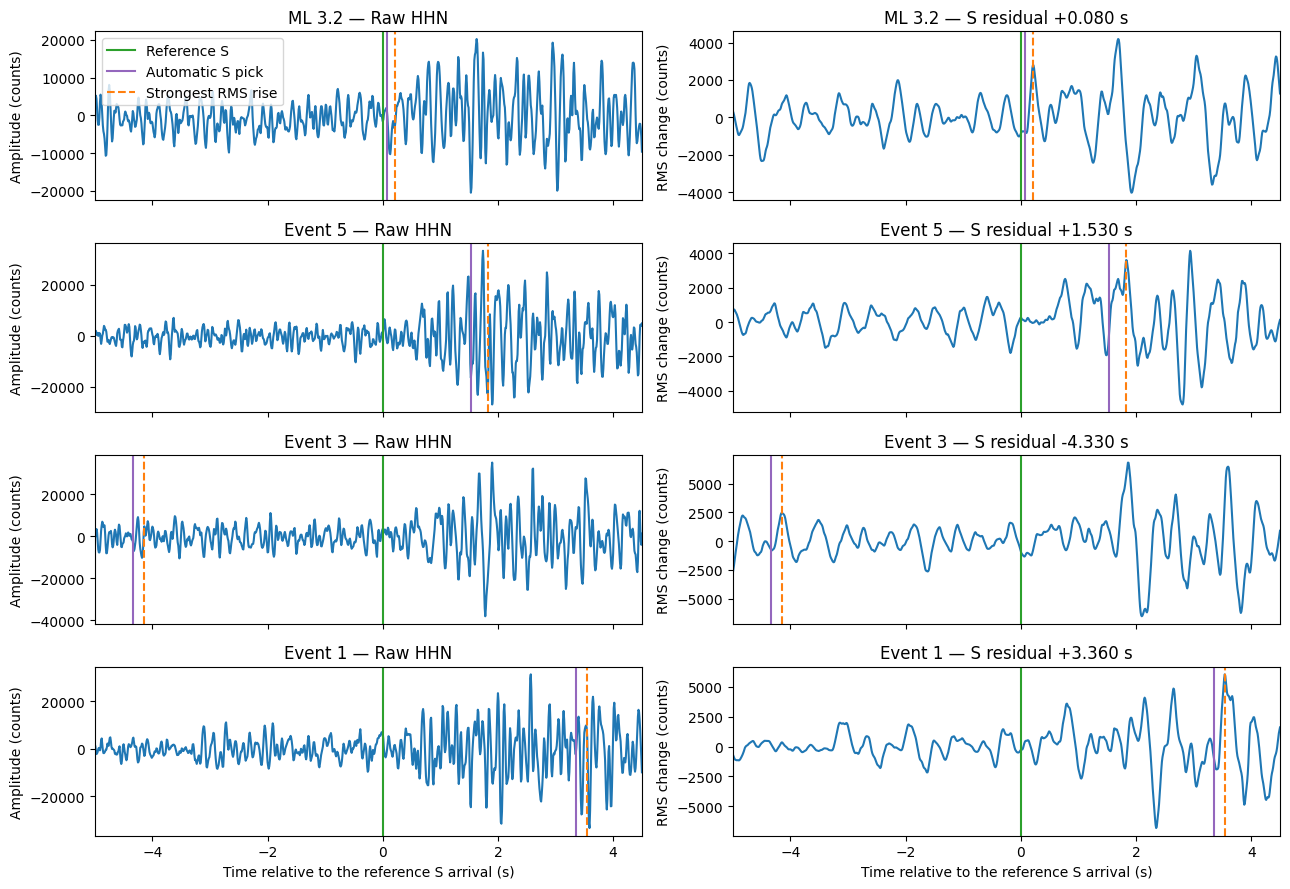

In [80]:
# Pair the existing S picks with their recorded RMS-rise peaks.
cases = [
    (
        "ML 3.2",
        tr_s_test,
        s_reference_ml32,
        UTCDateTime("2024-03-14T03:15:02.920Z"),
        UTCDateTime("2024-03-14T03:15:03.050Z"),
    )
]

for event_id in (5, 3, 1):
    event = validation_candidates.set_index("event_id").loc[event_id]
    result = continuous_s_check.set_index("event_id").loc[event_id]
    diagnostic = s_rms_diagnostics.set_index("event_id").loc[event_id]

    origin = UTCDateTime(event["origin_utc"].to_pydatetime())
    reference_s = UTCDateTime(event["s_ceme_utc"].to_pydatetime())
    automatic_s = UTCDateTime(result["s_automatic_utc"].to_pydatetime())
    peak_utc = reference_s + float(diagnostic["search_peak_relative_to_s_s"])

    # Extract the same raw HHN window used in the validation test.
    window = st.select(station="CEME", channel="HHN").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    window.merge(method=0, fill_value=None)
    cases.append((f"Event {event_id}", window[0], reference_s, automatic_s, peak_utc))

fig, axes = plt.subplots(len(cases), 2, figsize=(13, 9), sharex=True)

for (ax_wave, ax_rise), (label, trace, reference_s, automatic_s, peak_utc) in zip(
    axes, cases
):
    # Recompute the existing RMS curve for display.
    fs = trace.stats.sampling_rate
    samples = trace.data.astype(float)
    rms = np.sqrt(pd.Series(samples ** 2).rolling(int(0.2 * fs)).mean())
    lag = int(0.1 * fs)
    rise = rms.diff(lag).rolling(lag).mean().to_numpy()

    # Display the same interval relative to the reference S arrival.
    time_from_s = trace.times() + (trace.stats.starttime - reference_s)
    view = (time_from_s >= -5.0) & (time_from_s <= 4.5)
    error = automatic_s - reference_s

    ax_wave.plot(time_from_s[view], samples[view])
    ax_wave.set_title(f"{label} — Raw HHN")
    ax_wave.set_ylabel("Amplitude (counts)")

    ax_rise.plot(time_from_s[view], rise[view])
    ax_rise.set_title(f"{label} — S residual {error:+.3f} s")
    ax_rise.set_ylabel("RMS change (counts)")

    # Mark the reference arrival, automatic onset, and strongest rise.
    for ax in (ax_wave, ax_rise):
        ax.axvline(0, color="tab:green", label="Reference S")
        ax.axvline(error, color="tab:purple", label="Automatic S pick")
        ax.axvline(
            peak_utc - reference_s,
            color="tab:orange", linestyle="--", label="Strongest RMS rise",
        )

axes[0, 0].legend(loc="best")
axes[-1, 0].set_xlim(-5.0, 4.5)
for ax in axes[-1]:
    ax.set_xlabel("Time relative to the reference S arrival (s)")

fig.tight_layout()
plt.show()

### P and S arrivals — Three-minute raw waveform comparison

Compare the raw CEME HHZ and HHN waveforms for the ML 3.2 event and validation events 5, 3, and 1. Each panel shows 60 s before and 120 s after the reference P arrival. The HHZ panels show the P picks, and the HHN panels show the S picks. Green lines mark reference arrivals, and dashed purple lines mark automatic picks where available. This display window provides waveform context around the existing picks.

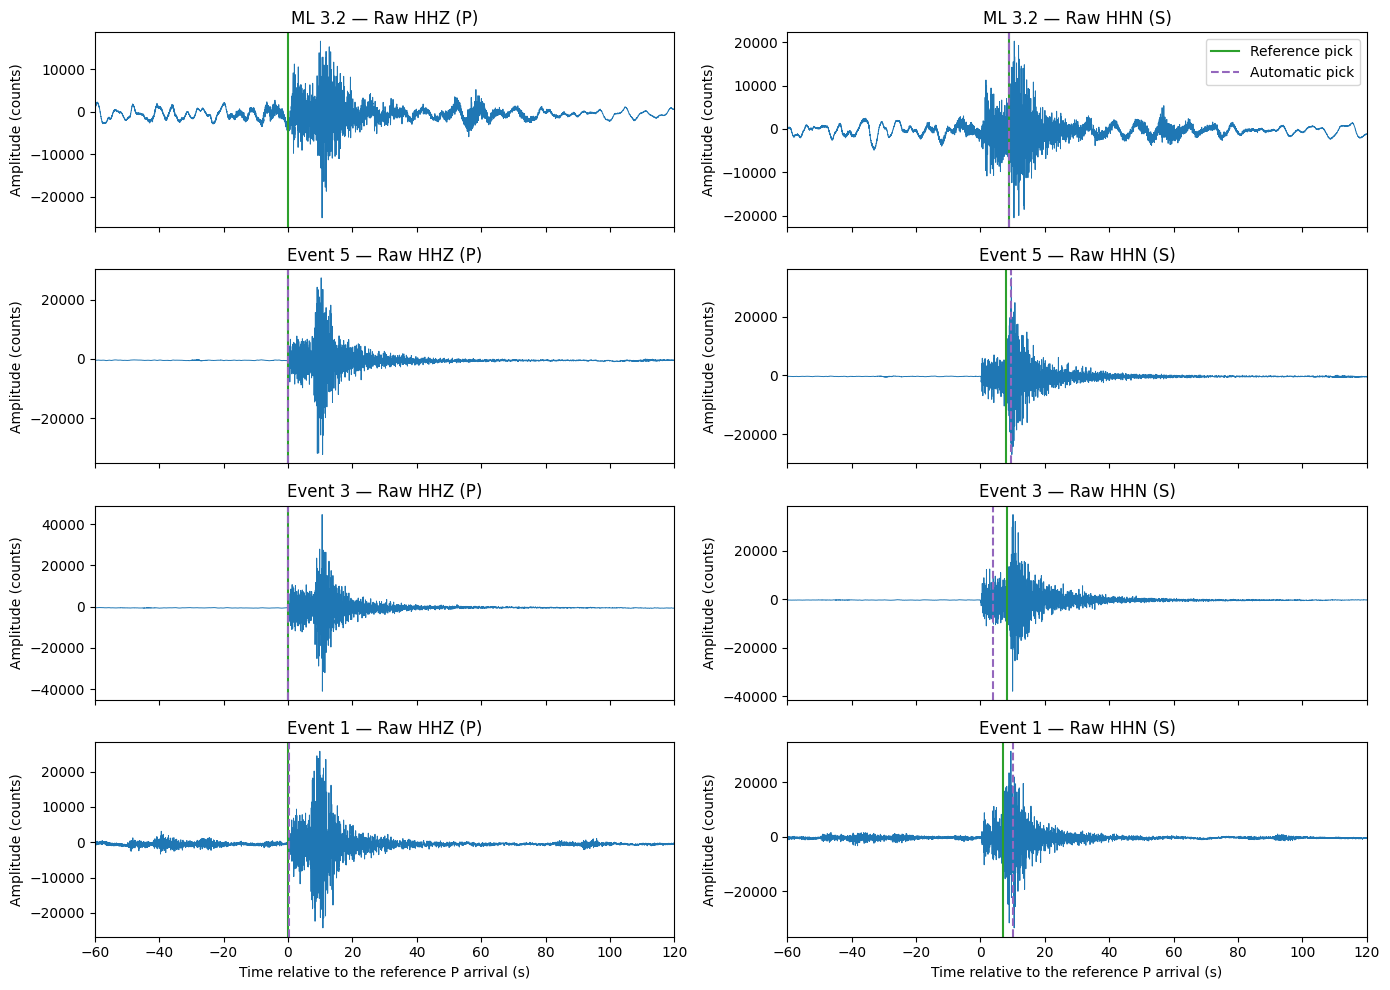

In [81]:
# Collect reference and automatic picks for the four events.
phase_cases = [
    (
        "ML 3.2",
        p_reference_ml32,
        s_reference_ml32,
        None,  # No automatic P pick is shown for this comparison event.
        UTCDateTime("2024-03-14T03:15:02.920Z"),
    ),
]

reference_events = validation_candidates.set_index("event_id")
p_picks = continuous_p_check.set_index("event_id")
s_picks = continuous_s_check.set_index("event_id")

for event_id in (5, 3, 1):
    event = reference_events.loc[event_id]
    phase_cases.append((
        f"Event {event_id}",
        UTCDateTime(event["p_ceme_utc"].to_pydatetime()),
        UTCDateTime(event["s_ceme_utc"].to_pydatetime()),
        UTCDateTime(p_picks.at[event_id, "closest_candidate_utc"].to_pydatetime()),
        UTCDateTime(s_picks.at[event_id, "s_automatic_utc"].to_pydatetime()),
    ))

# Set the display window relative to the reference P arrival.
left, right = -60.0, 120.0
fig, axes = plt.subplots(len(phase_cases), 2, figsize=(14, 10), sharex=True)

for (ax_p, ax_s), (label, ref_p, ref_s, auto_p, auto_s) in zip(axes, phase_cases):
    for ax, channel, phase, reference, automatic in (
        (ax_p, "HHZ", "P", ref_p, auto_p),
        (ax_s, "HHN", "S", ref_s, auto_s),
    ):
        # Slice the daily record and align samples to the reference P arrival.
        window = st.select(station="CEME", channel=channel).slice(
            starttime=ref_p + left,
            endtime=ref_p + right,
        ).copy()
        window.merge(method=0, fill_value=None)

        for trace in window:
            time_from_p = trace.times() + (trace.stats.starttime - ref_p)
            ax.plot(time_from_p, trace.data, color="tab:blue", linewidth=0.7)

        # Mark the reference arrival and the existing automatic pick.
        ax.axvline(reference - ref_p, color="tab:green", label="Reference pick")
        if automatic is not None:
            ax.axvline(
                automatic - ref_p,
                color="tab:purple",
                linestyle="--",
                label="Automatic pick",
            )

        ax.set_title(f"{label} — Raw {channel} ({phase})")
        ax.set_ylabel("Amplitude (counts)")

axes[0, 1].legend(loc="upper right")
axes[-1, 0].set_xlim(left, right)
for ax in axes[-1]:
    ax.set_xlabel("Time relative to the reference P arrival (s)")

fig.tight_layout()
plt.show()

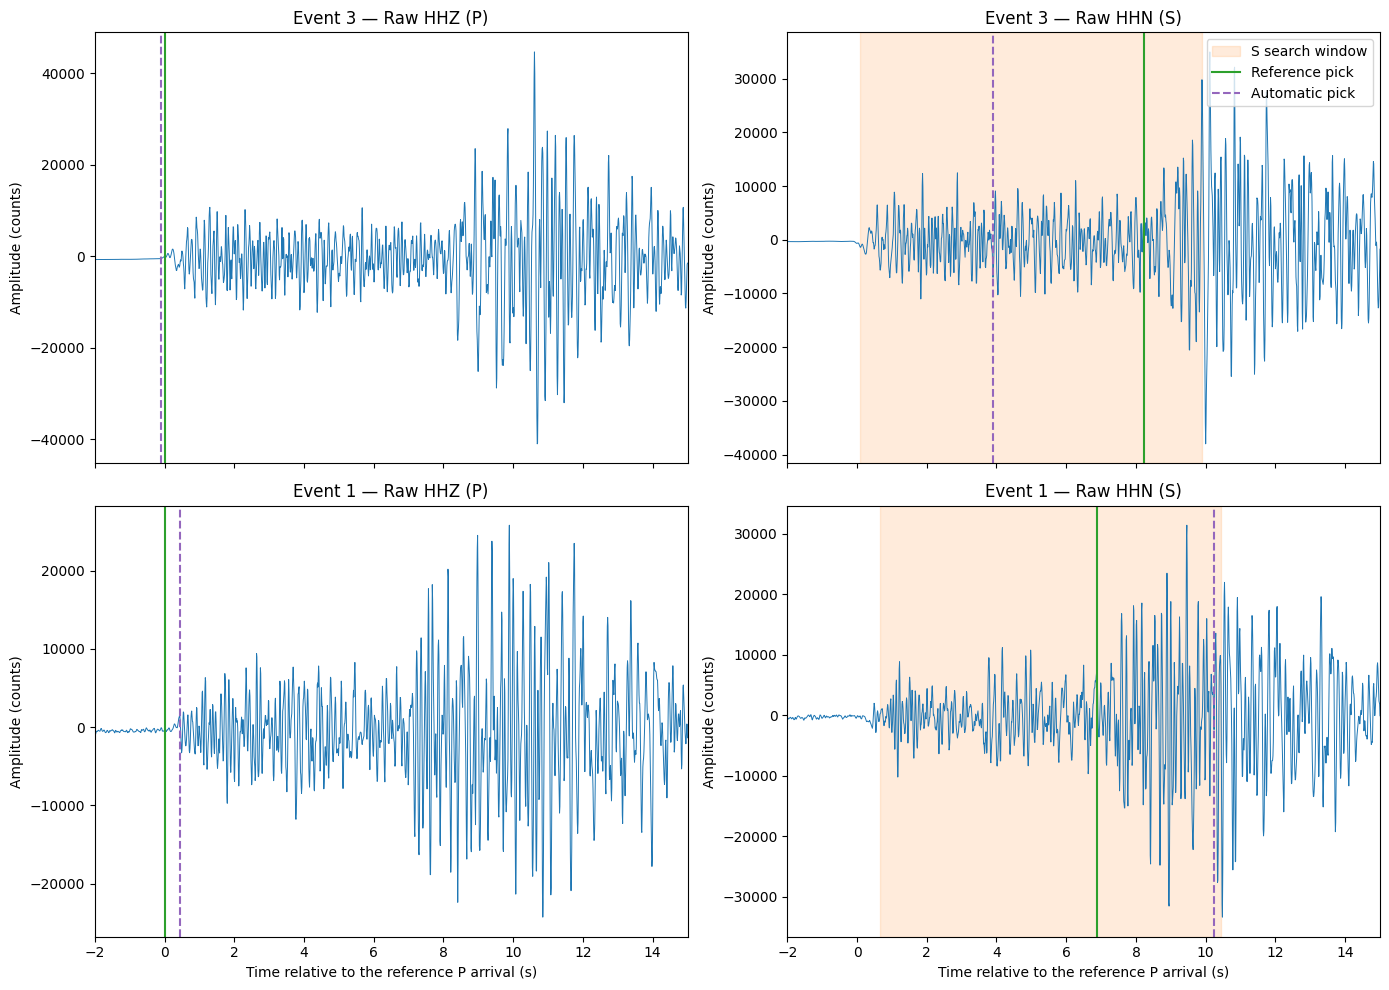

In [82]:
# Collect reference and automatic picks for the four events.
phase_cases = [
    (
        "ML 3.2",
        p_reference_ml32,
        s_reference_ml32,
        None,  # No automatic P pick is shown for this comparison event.
        UTCDateTime("2024-03-14T03:15:02.920Z"),
    ),
]

reference_events = validation_candidates.set_index("event_id")
p_picks = continuous_p_check.set_index("event_id")
s_picks = continuous_s_check.set_index("event_id")

for event_id in (5, 3, 1):
    event = reference_events.loc[event_id]
    phase_cases.append((
        f"Event {event_id}",
        UTCDateTime(event["p_ceme_utc"].to_pydatetime()),
        UTCDateTime(event["s_ceme_utc"].to_pydatetime()),
        UTCDateTime(p_picks.at[event_id, "closest_candidate_utc"].to_pydatetime()),
        UTCDateTime(s_picks.at[event_id, "s_automatic_utc"].to_pydatetime()),
    ))

# Set the display window relative to the reference P arrival.
# Keep the two events with the largest early and late S errors.
phase_cases = [
    case for case in phase_cases if case[0] in ("Event 3", "Event 1")
]
left, right = -2.0, 15.0
fig, axes = plt.subplots(len(phase_cases), 2, figsize=(14, 10), sharex=True)

for (ax_p, ax_s), (label, ref_p, ref_s, auto_p, auto_s) in zip(axes, phase_cases):
    for ax, channel, phase, reference, automatic in (
        (ax_p, "HHZ", "P", ref_p, auto_p),
        (ax_s, "HHN", "S", ref_s, auto_s),
    ):
        # Slice the daily record and align samples to the reference P arrival.
        window = st.select(station="CEME", channel=channel).slice(
            starttime=ref_p + left,
            endtime=ref_p + right,
        ).copy()
        window.merge(method=0, fill_value=None)

        for trace in window:
            time_from_p = trace.times() + (trace.stats.starttime - ref_p)
            ax.plot(time_from_p, trace.data, color="tab:blue", linewidth=0.7)
                    # Shade the actual S search window on HHN.
        if phase == "S":
            p_offset = auto_p - ref_p
            ax.axvspan(
                p_offset + 0.2,
                p_offset + 10.0,
                color="tab:orange",
                alpha=0.15,
                label="S search window",
            )

        # Mark the reference arrival and the existing automatic pick.
        ax.axvline(reference - ref_p, color="tab:green", label="Reference pick")
        if automatic is not None:
            ax.axvline(
                automatic - ref_p,
                color="tab:purple",
                linestyle="--",
                label="Automatic pick",
            )

        ax.set_title(f"{label} — Raw {channel} ({phase})")
        ax.set_ylabel("Amplitude (counts)")

axes[0, 1].legend(loc="upper right")
axes[-1, 0].set_xlim(left, right)
for ax in axes[-1]:
    ax.set_xlabel("Time relative to the reference P arrival (s)")

fig.tight_layout()
plt.show()

### HHN S picking — Search-window assessment

The reference S arrivals for Events 3 and 1 both fell within the original search window of 0.2–10.0 s after the automatic P pick. For Event 3, the RMS method selected an earlier rise and placed the S pick 4.330 s before the reference arrival. For Event 1, it selected a later rise near the end of the search window and placed the pick 3.360 s after the reference arrival.

Across the ten CEME events, the reference S–P interval ranged from 6.770 to 8.220 s, with a median of 7.565 s. This observed range motivates a trial search window of 6.0–9.0 s after the automatic P pick. The narrower window excludes the rises previously selected for Events 3 and 1 while retaining their reference S arrivals.

### Next test — Narrower S search window

Apply the same RMS picking rule to the nine events with a matched automatic P pick. Change only the search window to 6.0–9.0 s after that pick. Check whether each reference S arrival remains inside the window, then compare the signed errors, median absolute error, and missing picks with the original results. Treat this comparison as parameter tuning and evaluate the selected window on a separate set of events.

In [84]:
narrow_rows = []

for event in s_checks.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    automatic_p = UTCDateTime(event.closest_candidate_utc.to_pydatetime())
    reference_s = UTCDateTime(event.s_ceme_utc.to_pydatetime())

    # Use the same raw HHN trace window as in the original test.
    window = st.select(station="CEME", channel="HHN").slice(
        starttime=origin - 30, endtime=origin + 60
    ).copy()
    window.merge(method=0, fill_value=None)
    trace = window[0]
    fs = trace.stats.sampling_rate

    # Compute the same rolling RMS and smoothed RMS rise.
    energy = pd.Series(trace.data.astype(float) ** 2)
    rms = np.sqrt(energy.rolling(int(0.2 * fs)).mean())
    lag = int(0.1 * fs)
    rise = rms.diff(lag).rolling(lag).mean().to_numpy()

    # Search from 6 to 9 s after the automatic P pick.
    time_from_p = trace.times() + (trace.stats.starttime - automatic_p)
    search = (time_from_p >= 6.0) & (time_from_p <= 9.0)
    rising = np.flatnonzero(search & np.isfinite(rise) & (rise > 0))

    s_automatic = pd.NaT
    error_s = np.nan

    if rising.size:
        peak = rising[np.argmax(rise[rising])]

        # Find the preceding RMS minimum within the same 0.3 s lookback.
        start = max(np.flatnonzero(search)[0], peak - int(0.3 * fs))
        onset = rms.iloc[start:peak + 1].idxmin()
        pick = trace.stats.starttime + onset / fs
        s_automatic = pd.Timestamp(pick.datetime, tz="UTC")
        error_s = pick - reference_s

    # Use the reference S arrival to check coverage and calculate error.
    narrow_rows.append({
        "event_id": event.event_id,
        "s_reference_utc": event.s_ceme_utc,
        "reference_s_in_narrow_window": 6.0 <= reference_s - automatic_p <= 9.0,
        "s_narrow_utc": s_automatic,
        "narrow_error_s": error_s,
    })

# Compare both search windows for the same events.
continuous_s_narrow = pd.DataFrame(narrow_rows)
s_window_comparison = continuous_s_narrow.merge(
    continuous_s_check[["event_id", "s_automatic_utc", "s_error_s"]].rename(
        columns={"s_automatic_utc": "s_original_utc", "s_error_s": "original_error_s"}
    ),
    on="event_id",
    validate="one_to_one",
)

display(s_window_comparison.round(3))

# Summarize timing errors and missing picks for both windows.
summary_rows = []
for label, column in (
    ("Original: 0.2–10 s", "original_error_s"),
    ("Narrow: 6–9 s", "narrow_error_s"),
):
    errors = s_window_comparison[column].abs()
    summary_rows.append({
        "search_window": label,
        "median_absolute_error_s": errors.median(),
        "within_0_5_s": errors.le(0.5).sum(),
        "missing_picks": errors.isna().sum(),
    })

display(pd.DataFrame(summary_rows).round(3))

,event_id,s_reference_utc,reference_s_in_narrow_window,s_narrow_utc,narrow_error_s,s_original_utc,original_error_s
0,1,2024-03-14 03:31:06.090000+00:00,True,2024-03-14 03:31:07.960000+00:00,1.87,2024-03-14 03:31:09.450000+00:00,3.36
1,2,2024-03-14 10:48:26.450000+00:00,True,2024-03-14 10:48:27.740000+00:00,1.29,2024-03-14 10:48:28.320000+00:00,1.87
2,3,2024-03-14 11:48:21.420000+00:00,True,2024-03-14 11:48:21.100000+00:00,-0.32,2024-03-14 11:48:17.090000+00:00,-4.33
3,4,2024-03-14 12:27:53.120000+00:00,True,2024-03-14 12:27:53.670000+00:00,0.55,2024-03-14 12:27:53.670000+00:00,0.55
4,5,2024-03-14 13:31:40.380000+00:00,True,2024-03-14 13:31:40.880000+00:00,0.50,2024-03-14 13:31:41.910000+00:00,1.53
5,7,2024-03-14 15:23:48.560000+00:00,True,2024-03-14 15:23:49.350000+00:00,0.79,2024-03-14 15:23:50.380000+00:00,1.82
6,8,2024-03-14 16:32:51.390000+00:00,True,2024-03-14 16:32:52.550000+00:00,1.16,2024-03-14 16:32:53.180000+00:00,1.79
7,9,2024-03-14 16:40:36.720000+00:00,True,2024-03-14 16:40:37.530000+00:00,0.81,2024-03-14 16:40:37.780000+00:00,1.06
8,10,2024-03-14 16:46:09.730000+00:00,True,2024-03-14 16:46:11.820000+00:00,2.09,2024-03-14 16:46:11.820000+00:00,2.09


,search_window,median_absolute_error_s,within_0_5_s,missing_picks
0,Original: 0.2–10 s,1.82,0,0
1,Narrow: 6–9 s,0.81,2,0


### HHN S picking — Narrower search-window results

With the RMS picking rule unchanged, narrowing the search window to 6–9 s after the automatic P pick reduced the median absolute S timing error from 1.820 s to 0.810 s. All nine reference S arrivals remained inside the narrower window. Absolute errors decreased for seven events and stayed unchanged for two. Two picks were within ±0.5 s, and eight of the nine picks were late. The window was selected using these events, so its performance should be evaluated on a separate set before adopting it for continuous detection.

### CEME — Importing the separate validation set

Load the ten events extracted from the GSE bulletin. Combine the date and time columns into UTC timestamps and verify that the origin precedes the P and S arrivals for each event. Retain this table for catalogue membership and waveform coverage checks before comparing the two S search windows.

In [85]:
import pandas as pd

new_phase_csv = "https://raw.githubusercontent.com/milena-seismo/DSB_capstone/refs/heads/main/10%20eq_p_s_test.3.csv"

# Load the date and phase times from the new validation CSV.
time_columns = {
    "EQ time": "origin_utc",
    "p/phase": "p_ceme_utc",
    "s/phase": "s_ceme_utc",
}
source = pd.read_csv(
    new_phase_csv, usecols=["date", *time_columns], dtype="string"
)

# Combine each time of day with the bulletin date.
new_validation_candidates = pd.DataFrame({
    "event_id": range(1, len(source) + 1)
})
for source_column, target_column in time_columns.items():
    timestamps = source["date"].str.strip() + " " + source[source_column].str.strip()
    new_validation_candidates[target_column] = pd.to_datetime(
        timestamps, format="%m/%d/%Y %H:%M:%S.%f", utc=True, errors="raise"
    )

# Verify the phase order before using the table.
events = new_validation_candidates
valid_order = (
    (events["origin_utc"] < events["p_ceme_utc"])
    & (events["p_ceme_utc"] < events["s_ceme_utc"])
)
if not valid_order.all():
    display(events.loc[~valid_order])
    raise ValueError("Expected origin time < P arrival < S arrival.")

new_validation_candidates = events.sort_values("origin_utc").reset_index(drop=True)
print(f"New validation events loaded: {len(new_validation_candidates)}")
display(new_validation_candidates)

New validation events loaded: 10


,event_id,origin_utc,p_ceme_utc,s_ceme_utc
0,1,2024-03-14 03:23:03.050000+00:00,2024-03-14 03:23:11.040000+00:00,2024-03-14 03:23:19.190000+00:00
1,2,2024-03-14 03:25:04.490000+00:00,2024-03-14 03:25:12.530000+00:00,2024-03-14 03:25:20.540000+00:00
2,3,2024-03-14 03:26:14.810000+00:00,2024-03-14 03:26:22.850000+00:00,2024-03-14 03:26:29.710000+00:00
3,4,2024-03-14 03:29:34.490000+00:00,2024-03-14 03:29:43.610000+00:00,2024-03-14 03:29:51.620000+00:00
4,5,2024-03-14 03:36:32.190000+00:00,2024-03-14 03:36:39.950000+00:00,2024-03-14 03:36:47.180000+00:00
5,6,2024-03-14 03:37:51.790000+00:00,2024-03-14 03:38:00.690000+00:00,2024-03-14 03:38:08.050000+00:00
6,7,2024-03-14 03:38:45.600000+00:00,2024-03-14 03:38:54.630000+00:00,2024-03-14 03:39:02.510000+00:00
7,8,2024-03-14 03:40:38.290000+00:00,2024-03-14 03:40:46.730000+00:00,2024-03-14 03:40:54.130000+00:00
8,9,2024-03-14 03:57:23.730000+00:00,2024-03-14 03:57:31.840000+00:00,2024-03-14 03:57:40.090000+00:00
9,10,2024-03-14 04:01:31.750000+00:00,2024-03-14 04:01:39.790000+00:00,2024-03-14 04:01:47.530000+00:00


### CEME — Catalogue membership and waveform coverage

Check the ten bulletin events against the daily Čarađe catalogue by UTC origin time. For any event without an exact match, report the nearest catalogue origin and its time difference for review. Verify continuous HHZ and HHN coverage from 30 s before to 60 s after each bulletin origin before evaluating the S search windows.

In [86]:
# Use the daily catalogue to check each bulletin origin.
catalogue_origins = catalogue_14mar["origin_datetime"]
check_rows = []

for event in new_validation_candidates.itertuples(index=False):
    origin = UTCDateTime(event.origin_utc.to_pydatetime())
    offsets = catalogue_origins - event.origin_utc
    nearest_position = offsets.abs().to_numpy().argmin()
    nearest_offset = offsets.iloc[nearest_position]

    # Reuse the same waveform coverage check used for the first ten events.
    start, end = origin - 30, origin + 60
    check_rows.append({
        "event_id": event.event_id,
        "origin_utc": event.origin_utc,
        "exact_catalogue_match": nearest_offset == pd.Timedelta(0),
        "nearest_catalogue_id": catalogue_origins.index[nearest_position],
        "nearest_catalogue_origin_utc": catalogue_origins.iloc[nearest_position],
        "catalogue_minus_bulletin_s": nearest_offset.total_seconds(),
        "HHZ": coverage_status(st, "HHZ", start, end),
        "HHN": coverage_status(st, "HHN", start, end),
    })

new_validation_checks = pd.DataFrame(check_rows)
coverage_ok = new_validation_checks[["HHZ", "HHN"]].eq("OK").all(axis=1)
catalogue_ok = new_validation_checks["exact_catalogue_match"]

display(new_validation_checks.round({"catalogue_minus_bulletin_s": 3}))
print(f"Exact catalogue matches: {catalogue_ok.sum()}/{len(catalogue_ok)}")
print(f"Events with continuous HHZ and HHN: {coverage_ok.sum()}/{len(coverage_ok)}")

,event_id,origin_utc,exact_catalogue_match,nearest_catalogue_id,nearest_catalogue_origin_utc,catalogue_minus_bulletin_s,HHZ,HHN
0,1,2024-03-14 03:23:03.050000+00:00,True,405,2024-03-14 03:23:03.050000+00:00,0.0,OK,OK
1,2,2024-03-14 03:25:04.490000+00:00,True,406,2024-03-14 03:25:04.490000+00:00,0.0,OK,OK
2,3,2024-03-14 03:26:14.810000+00:00,True,407,2024-03-14 03:26:14.810000+00:00,0.0,OK,OK
3,4,2024-03-14 03:29:34.490000+00:00,True,408,2024-03-14 03:29:34.490000+00:00,0.0,OK,OK
4,5,2024-03-14 03:36:32.190000+00:00,True,411,2024-03-14 03:36:32.190000+00:00,0.0,OK,OK
5,6,2024-03-14 03:37:51.790000+00:00,True,287,2024-03-14 03:37:51.790000+00:00,0.0,OK,OK
6,7,2024-03-14 03:38:45.600000+00:00,True,288,2024-03-14 03:38:45.600000+00:00,0.0,OK,OK
7,8,2024-03-14 03:40:38.290000+00:00,True,289,2024-03-14 03:40:38.290000+00:00,0.0,OK,OK
8,9,2024-03-14 03:57:23.730000+00:00,True,290,2024-03-14 03:57:23.730000+00:00,0.0,OK,OK
9,10,2024-03-14 04:01:31.750000+00:00,True,291,2024-03-14 04:01:31.750000+00:00,0.0,OK,OK


Exact catalogue matches: 10/10
Events with continuous HHZ and HHN: 10/10


### CEME — Independent comparison of S search windows

Match the reference P arrivals to the existing continuous P candidates within ±0.5 s. For each matched event, apply the same raw HHN RMS rule in two windows after the automatic P pick: 0.2–10.0 s and 6.0–9.0 s. Use the reference S arrival to check window coverage and measure timing error. Report missing P matches, missing S picks, and the number of S picks within ±0.5 s for each window.

In [87]:
# Define the two search windows and keep the existing P tolerance.
s_windows = {"0.2–10 s": (0.2, 10.0), "6–9 s": (6.0, 9.0)}
p_tolerance = pd.Timedelta(seconds=0.5)
daily_p_times = continuous_p_candidates["p_candidate_utc"]
new_s_rows = []

for event in new_validation_candidates.itertuples(index=False):
    # Match the closest existing P candidate within the fixed tolerance.
    offsets = daily_p_times - event.p_ceme_utc
    nearby = offsets.loc[offsets.abs() <= p_tolerance]
    p_matched = not nearby.empty
    automatic_p = (
        daily_p_times.loc[nearby.abs().idxmin()] if p_matched else pd.NaT
    )

    if p_matched:
        origin = UTCDateTime(event.origin_utc.to_pydatetime())
        p_utc = UTCDateTime(automatic_p.to_pydatetime())

        # Extract the same raw HHN window used in the previous tests.
        window = st.select(station="CEME", channel="HHN").slice(
            starttime=origin - 30, endtime=origin + 60
        ).copy()
        window.merge(method=0, fill_value=None)
        trace = window[0]
        fs = trace.stats.sampling_rate

        # Compute rolling RMS and the smoothed RMS change.
        energy = pd.Series(trace.data.astype(float) ** 2)
        rms = np.sqrt(energy.rolling(int(0.2 * fs)).mean())
        lag = int(0.1 * fs)
        rise = rms.diff(lag).rolling(lag).mean().to_numpy()
        time_from_p = trace.times() + (trace.stats.starttime - p_utc)
        reference_delay = (event.s_ceme_utc - automatic_p).total_seconds()

    for label, (lower, upper) in s_windows.items():
        s_pick = pd.NaT
        reference_in_window = pd.NA

        if p_matched:
            reference_in_window = lower <= reference_delay <= upper
            search = (time_from_p >= lower) & (time_from_p <= upper)
            rising = np.flatnonzero(search & np.isfinite(rise) & (rise > 0))

            # Pick the RMS minimum within 0.3 s before the strongest rise.
            if rising.size:
                peak = rising[np.argmax(rise[rising])]
                start = max(np.flatnonzero(search)[0], peak - int(0.3 * fs))
                onset = rms.iloc[start:peak + 1].idxmin()
                pick = trace.stats.starttime + onset / fs
                s_pick = pd.Timestamp(pick.datetime, tz="UTC")

        new_s_rows.append({
            "event_id": event.event_id,
            "search_window": label,
            "p_matched": p_matched,
            "reference_s_in_window": reference_in_window,
            "s_reference_utc": event.s_ceme_utc,
            "s_automatic_utc": s_pick,
            "s_error_s": (
                (s_pick - event.s_ceme_utc).total_seconds()
                if pd.notna(s_pick) else np.nan
            ),
        })

new_s_results = pd.DataFrame(new_s_rows)

# Summarize both windows across all events, including missing picks.
summary_rows = []
for label, group in new_s_results.groupby("search_window", sort=False):
    errors = group["s_error_s"].abs()
    summary_rows.append({
        "search_window": label,
        "events": len(group),
        "matched_p": group["p_matched"].sum(),
        "reference_s_in_window": group["reference_s_in_window"].sum(),
        "s_picks": errors.count(),
        "within_0_5_s": errors.le(0.5).sum(),
        "median_absolute_error_s": errors.median(),
        "missing_s_picks": errors.isna().sum(),
    })

new_s_summary = pd.DataFrame(summary_rows)
display(new_s_results.round({"s_error_s": 3}))
display(new_s_summary.round(3))

,event_id,search_window,p_matched,reference_s_in_window,s_reference_utc,s_automatic_utc,s_error_s
0,1,0.2–10 s,False,<NA>,2024-03-14 03:23:19.190000+00:00,NaT,NaN
1,1,6–9 s,False,<NA>,2024-03-14 03:23:19.190000+00:00,NaT,NaN
2,2,0.2–10 s,False,<NA>,2024-03-14 03:25:20.540000+00:00,NaT,NaN
3,2,6–9 s,False,<NA>,2024-03-14 03:25:20.540000+00:00,NaT,NaN
4,3,0.2–10 s,False,<NA>,2024-03-14 03:26:29.710000+00:00,NaT,NaN
5,3,6–9 s,False,<NA>,2024-03-14 03:26:29.710000+00:00,NaT,NaN
6,4,0.2–10 s,True,True,2024-03-14 03:29:51.620000+00:00,2024-03-14 03:29:53.600000+00:00,1.98
7,4,6–9 s,True,True,2024-03-14 03:29:51.620000+00:00,2024-03-14 03:29:52.360000+00:00,0.74
8,5,0.2–10 s,True,True,2024-03-14 03:36:47.180000+00:00,2024-03-14 03:36:47.850000+00:00,0.67
9,5,6–9 s,True,True,2024-03-14 03:36:47.180000+00:00,2024-03-14 03:36:47.850000+00:00,0.67


,search_window,events,matched_p,reference_s_in_window,s_picks,within_0_5_s,median_absolute_error_s,missing_s_picks
0,0.2–10 s,10,6,6,6,1,1.645,4
1,6–9 s,10,6,6,6,2,0.705,4


### CEME — Validation of the narrower S search window

On the separate ten-event set, six reference P arrivals matched an existing continuous P candidate within ±0.5 s. Both RMS search windows contained the reference S arrival and returned an S pick for all six matched events. Narrowing the window from 0.2–10.0 s to 6.0–9.0 s reduced the median absolute S timing error from 1.645 s to 0.705 s and increased the number of S picks within ±0.5 s from one to two. The four events without a matched P candidate did not enter the S search.

### CEME — Review of unmatched P arrivals

For each reference P arrival without a match within ±0.5 s, report the closest candidate from the existing continuous HHZ scan and its signed timing offset. Use this diagnostic to identify near misses and select waveforms for review.

In [88]:
# Identify reference events without a P match in the validation results.
unmatched_ids = new_s_results.loc[~new_s_results["p_matched"], "event_id"].unique()
unmatched_events = new_validation_candidates.loc[
    new_validation_candidates["event_id"].isin(unmatched_ids)
]

# Find the nearest existing candidate and report its signed timing offset.
p_review_rows = []
for event in unmatched_events.itertuples(index=False):
    offsets = continuous_p_candidates["p_candidate_utc"] - event.p_ceme_utc
    nearest = offsets.abs().idxmin()
    p_review_rows.append({
        "event_id": event.event_id,
        "reference_p_utc": event.p_ceme_utc,
        "nearest_p_candidate_utc": continuous_p_candidates.at[nearest, "p_candidate_utc"],
        "offset_s": offsets.loc[nearest].total_seconds(),
    })

display(pd.DataFrame(p_review_rows).round(3))

,event_id,reference_p_utc,nearest_p_candidate_utc,offset_s
0,1,2024-03-14 03:23:11.040000+00:00,2024-03-14 03:23:12.080000+00:00,1.04
1,2,2024-03-14 03:25:12.530000+00:00,2024-03-14 03:25:14.200000+00:00,1.67
2,3,2024-03-14 03:26:22.850000+00:00,2024-03-14 03:26:23.580000+00:00,0.73
3,9,2024-03-14 03:57:31.840000+00:00,2024-03-14 03:57:33.150000+00:00,1.31


### CEME — Diagnosing late P candidates on HHZ

Inspect the raw HHZ waveform and absolute sample-to-sample differences for validation events 3 and 2. Reconstruct the original MAD threshold using the same one-second blocks and preceding five-second noise windows from the continuous scan. Mark all threshold crossings before grouping and the candidates retained after grouping. Time zero marks the reference P arrival.

Event 3 within ±0.5 s: 0 crossings, 0 retained candidates
Event 2 within ±0.5 s: 0 crossings, 0 retained candidates


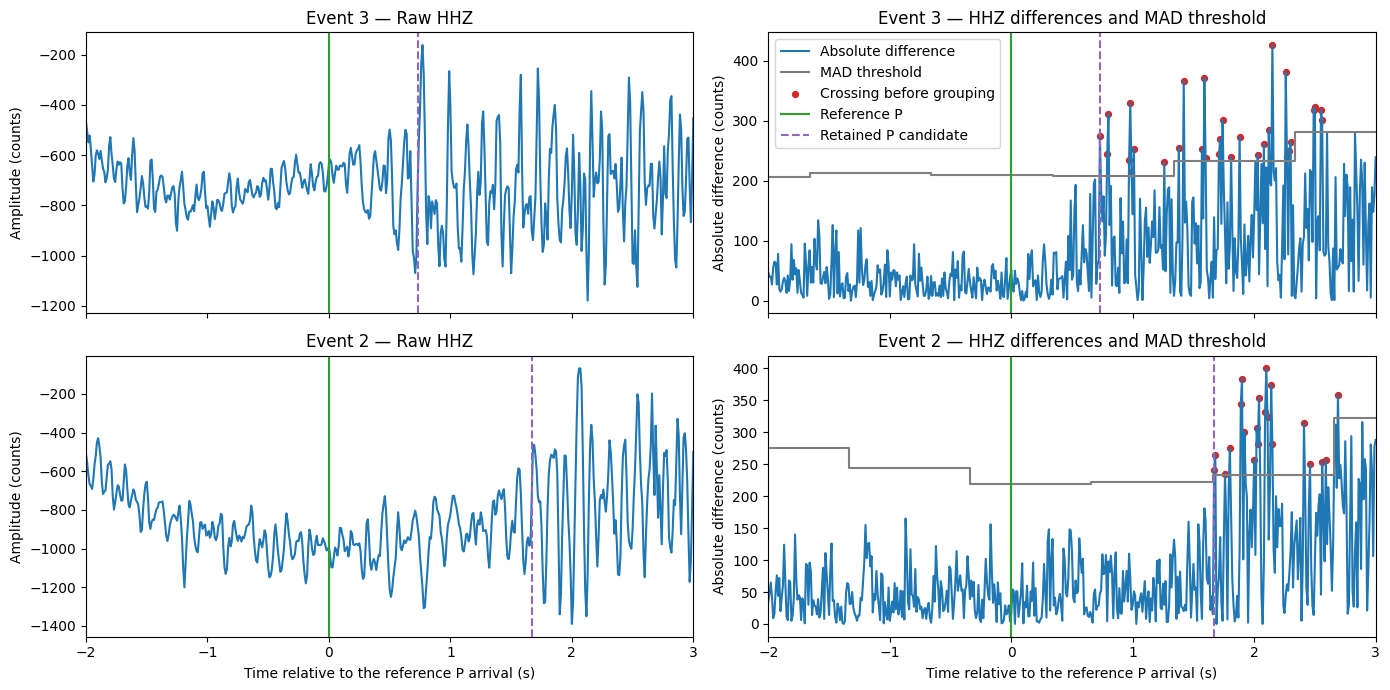

In [89]:
event_ids = (3, 2)
view_before, view_after = 2.0, 3.0
events_by_id = new_validation_candidates.set_index("event_id")

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

for row, event_id in enumerate(event_ids):
    reference_p = events_by_id.at[event_id, "p_ceme_utc"]
    p_utc = UTCDateTime(reference_p.to_pydatetime())
    start_utc, end_utc = p_utc - view_before, p_utc + view_after

    # Use the same continuous segment and block alignment as the daily scan.
    trace = next(
        segment for segment in hhz_segments
        if segment.stats.starttime <= start_utc
        and segment.stats.endtime >= end_utc
    )
    fs = trace.stats.sampling_rate
    noise_samples = round(5.0 * fs)
    block_samples = round(fs)
    reference_sample = (p_utc - trace.stats.starttime) * fs
    first_sample = max(1, int(np.ceil(reference_sample - view_before * fs)))
    last_sample = min(trace.stats.npts - 1,
                      int(np.floor(reference_sample + view_after * fs)))

    # Align each difference to the later sample and reconstruct its threshold.
    samples = trace.data.astype(float)
    differences = np.abs(np.diff(samples))
    sample_indices = np.arange(first_sample, last_sample + 1)
    diff_indices = sample_indices - 1
    times = (sample_indices - reference_sample) / fs
    thresholds = np.full(len(diff_indices), np.nan)

    block_starts = noise_samples + (
        (diff_indices - noise_samples) // block_samples
    ) * block_samples

    for block_start in np.unique(block_starts):
        if block_start < noise_samples:
            continue
        noise = differences[block_start - noise_samples:block_start]
        median_noise = np.median(noise)
        mad_noise = np.median(np.abs(noise - median_noise))
        thresholds[block_starts == block_start] = median_noise + 6 * 1.4826 * mad_noise

    # Show threshold crossings before grouping and retained daily candidates.
    values = differences[diff_indices]
    crossings = values > thresholds
    offsets = (continuous_p_candidates["p_candidate_utc"] - reference_p).dt.total_seconds()
    retained = offsets[offsets.between(-view_before, view_after)]

    ax_wave, ax_diff = axes[row]
    ax_wave.plot(times, samples[sample_indices], color="tab:blue")
    ax_wave.set_title(f"Event {event_id} — Raw HHZ")
    ax_wave.set_ylabel("Amplitude (counts)")

    ax_diff.plot(times, values, color="tab:blue", label="Absolute difference")
    ax_diff.step(times, thresholds, where="post", color="tab:gray", label="MAD threshold")
    ax_diff.scatter(
        times[crossings], values[crossings], color="tab:red", s=18,
        label="Crossing before grouping",
    )
    ax_diff.set_title(f"Event {event_id} — HHZ differences and MAD threshold")
    ax_diff.set_ylabel("Absolute difference (counts)")

    for ax in (ax_wave, ax_diff):
        ax.axvline(0, color="tab:green", label="Reference P")
        for index, offset in enumerate(retained):
            ax.axvline(
                offset, color="tab:purple", linestyle="--",
                label="Retained P candidate" if index == 0 else None,
            )

    near_p = np.abs(times) <= 0.5
    retained_near_p = retained.abs().le(0.5).sum()
    print(
        f"Event {event_id} within ±0.5 s: "
        f"{np.count_nonzero(crossings & near_p)} crossings, "
        f"{retained_near_p} retained candidates"
    )

axes[0, 1].legend(loc="upper left")
axes[-1, 0].set_xlim(-view_before, view_after)
for ax in axes[-1]:
    ax.set_xlabel("Time relative to the reference P arrival (s)")

fig.tight_layout()
plt.show()

### Continuous P detection — Comparing MAD factors 5 and 6

Compare MAD factors 5 and 6 for Events 3 and 2 using the same one-second blocks and five-second noise windows. Plot both thresholds and highlight crossings introduced by the lower threshold. Count crossings within ±0.5 s of each reference P arrival. This comparison uses crossings before grouping.

Event 3, within ±0.5 s — factor 6: 0, factor 5: 0
Event 3 within ±0.5 s: 0 crossings, 0 retained candidates
Event 2, within ±0.5 s — factor 6: 0, factor 5: 0
Event 2 within ±0.5 s: 0 crossings, 0 retained candidates


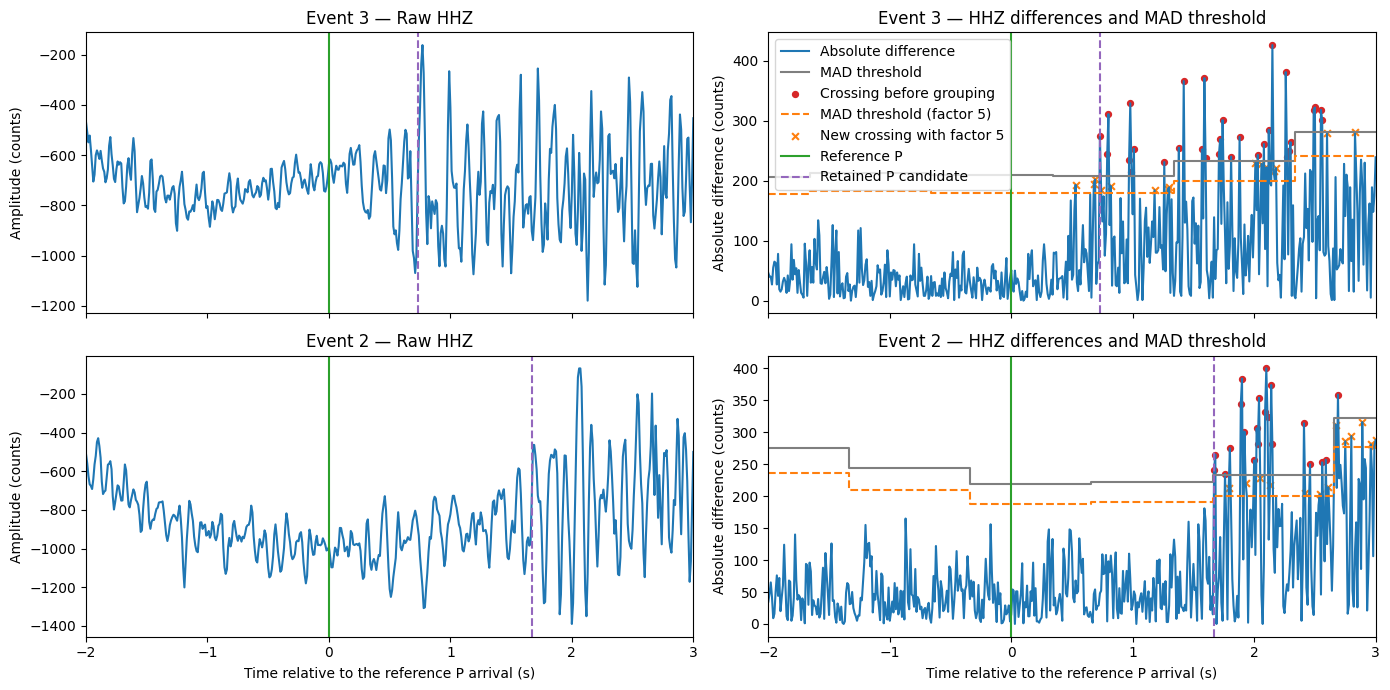

In [90]:
event_ids = (3, 2)
view_before, view_after = 2.0, 3.0
events_by_id = new_validation_candidates.set_index("event_id")

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)

for row, event_id in enumerate(event_ids):
    reference_p = events_by_id.at[event_id, "p_ceme_utc"]
    p_utc = UTCDateTime(reference_p.to_pydatetime())
    start_utc, end_utc = p_utc - view_before, p_utc + view_after

    # Use the same continuous segment and block alignment as the daily scan.
    trace = next(
        segment for segment in hhz_segments
        if segment.stats.starttime <= start_utc
        and segment.stats.endtime >= end_utc
    )
    fs = trace.stats.sampling_rate
    noise_samples = round(5.0 * fs)
    block_samples = round(fs)
    reference_sample = (p_utc - trace.stats.starttime) * fs
    first_sample = max(1, int(np.ceil(reference_sample - view_before * fs)))
    last_sample = min(trace.stats.npts - 1,
                      int(np.floor(reference_sample + view_after * fs)))

    # Align each difference to the later sample and reconstruct its threshold.
    samples = trace.data.astype(float)
    differences = np.abs(np.diff(samples))
    sample_indices = np.arange(first_sample, last_sample + 1)
    diff_indices = sample_indices - 1
    times = (sample_indices - reference_sample) / fs
    thresholds = np.full(len(diff_indices), np.nan)
    # Allocate a second threshold curve for MAD factor 5.
    thresholds_5 = np.full(len(diff_indices), np.nan)

    block_starts = noise_samples + (
        (diff_indices - noise_samples) // block_samples
    ) * block_samples

    for block_start in np.unique(block_starts):
        if block_start < noise_samples:
            continue
        noise = differences[block_start - noise_samples:block_start]
        median_noise = np.median(noise)
        mad_noise = np.median(np.abs(noise - median_noise))
        thresholds[block_starts == block_start] = median_noise + 6 * 1.4826 * mad_noise
      # Use the same noise statistics with MAD factor 5.
        thresholds_5[block_starts == block_start] = (
            median_noise + 5 * 1.4826 * mad_noise
        )

    # Show threshold crossings before grouping and retained daily candidates.
    values = differences[diff_indices]
    crossings = values > thresholds
    offsets = (continuous_p_candidates["p_candidate_utc"] - reference_p).dt.total_seconds()
    retained = offsets[offsets.between(-view_before, view_after)]

    ax_wave, ax_diff = axes[row]
    ax_wave.plot(times, samples[sample_indices], color="tab:blue")
    ax_wave.set_title(f"Event {event_id} — Raw HHZ")
    ax_wave.set_ylabel("Amplitude (counts)")

    ax_diff.plot(times, values, color="tab:blue", label="Absolute difference")
    ax_diff.step(times, thresholds, where="post", color="tab:gray", label="MAD threshold")
    ax_diff.scatter(
        times[crossings], values[crossings], color="tab:red", s=18,
        label="Crossing before grouping",
    )
        # Plot the lower threshold and highlight newly introduced crossings.
    crossings_5 = values > thresholds_5
    added_crossings = crossings_5 & ~crossings

    ax_diff.step(
        times, thresholds_5, where="post",
        color="tab:orange", linestyle="--", label="MAD threshold (factor 5)",
    )
    ax_diff.scatter(
        times[added_crossings], values[added_crossings],
        color="tab:orange", marker="x", s=24, label="New crossing with factor 5",
    )

    # Compare crossing counts near the reference P arrival before grouping.
    near_reference = np.abs(times) <= 0.5
    print(
        f"Event {event_id}, within ±0.5 s — "
        f"factor 6: {np.count_nonzero(crossings & near_reference)}, "
        f"factor 5: {np.count_nonzero(crossings_5 & near_reference)}"
    )
    ax_diff.set_title(f"Event {event_id} — HHZ differences and MAD threshold")
    ax_diff.set_ylabel("Absolute difference (counts)")

    for ax in (ax_wave, ax_diff):
        ax.axvline(0, color="tab:green", label="Reference P")
        for index, offset in enumerate(retained):
            ax.axvline(
                offset, color="tab:purple", linestyle="--",
                label="Retained P candidate" if index == 0 else None,
            )

    near_p = np.abs(times) <= 0.5
    retained_near_p = retained.abs().le(0.5).sum()
    print(
        f"Event {event_id} within ±0.5 s: "
        f"{np.count_nonzero(crossings & near_p)} crossings, "
        f"{retained_near_p} retained candidates"
    )

axes[0, 1].legend(loc="upper left")
axes[-1, 0].set_xlim(-view_before, view_after)
for ax in axes[-1]:
    ax.set_xlabel("Time relative to the reference P arrival (s)")

fig.tight_layout()
plt.show()

### CEME — EQTransformer comparison on ten validation events

Run the pretrained EQTransformer on all ten events in the separate validation set. Use the three-component CEME waveform from 30 s before to 60 s after each bulletin origin. Report every P and S pick with its signed timing error relative to the corresponding bulletin arrival. Record any phase with no returned pick as missing. This test evaluates phase timing in known event windows.

In [91]:
eqt_rows = []

# Run EQTransformer on all events in the new validation set.
for event_id in new_validation_candidates["event_id"]:
    event = new_validation_candidates.set_index("event_id").loc[event_id]
    origin = UTCDateTime(event["origin_utc"].to_pydatetime())
    start, end = origin - 30, origin + 60

    # Check all three components before running EQTransformer.
    statuses = {
        channel: coverage_status(st, channel, start, end)
        for channel in ("HHZ", "HHN", "HHE")
    }
    if any(status != "OK" for status in statuses.values()):
        raise ValueError(f"Event {event_id}: waveform coverage check failed: {statuses}")

    # Extract the three-component waveform around the known event.
    event_stream = st.select(station="CEME", channel="HH[ZNE]").slice(
        starttime=start, endtime=end
    ).copy()
    event_stream.merge(method=0, fill_value=None)
    output = model.classify(event_stream)

    # Report all model picks, keeping missing phases visible.
    for phase, column in (("P", "p_ceme_utc"), ("S", "s_ceme_utc")):
        reference = event[column]
        phase_picks = [pick for pick in output.picks if pick.phase == phase]

        for pick in phase_picks or [None]:
            pick_utc = (
                pd.Timestamp(pick.peak_time.datetime, tz="UTC")
                if pick is not None else pd.NaT
            )
            eqt_rows.append({
                "event_id": event_id,
                "phase": phase,
                "reference_utc": reference,
                "eqtransformer_pick_utc": pick_utc,
                "error_s": (
                    (pick_utc - reference).total_seconds()
                    if pd.notna(pick_utc) else np.nan
                ),
            })

eqt_late_pick_comparison = pd.DataFrame(eqt_rows)
display(eqt_late_pick_comparison.round({"error_s": 3}))

,event_id,phase,reference_utc,eqtransformer_pick_utc,error_s
0,1,P,2024-03-14 03:23:11.040000+00:00,2024-03-14 03:22:42.120000+00:00,-28.92
1,1,P,2024-03-14 03:23:11.040000+00:00,2024-03-14 03:22:43.050000+00:00,-27.99
2,1,P,2024-03-14 03:23:11.040000+00:00,2024-03-14 03:23:11.620000+00:00,0.58
3,1,S,2024-03-14 03:23:19.190000+00:00,2024-03-14 03:22:49.570000+00:00,-29.62
4,1,S,2024-03-14 03:23:19.190000+00:00,2024-03-14 03:23:18.400000+00:00,-0.79
5,2,P,2024-03-14 03:25:12.530000+00:00,2024-03-14 03:24:39.760000+00:00,-32.77
6,2,S,2024-03-14 03:25:20.540000+00:00,2024-03-14 03:25:01.430000+00:00,-19.11
7,3,P,2024-03-14 03:26:22.850000+00:00,2024-03-14 03:26:22.970000+00:00,0.12
8,3,S,2024-03-14 03:26:29.710000+00:00,2024-03-14 03:26:30.300000+00:00,0.59
9,4,P,2024-03-14 03:29:43.610000+00:00,2024-03-14 03:29:43.490000+00:00,-0.12


### Continuous EQTransformer scan — CEME, 14 March 2024

Run the pretrained EQTransformer on the available three-component CEME waveform for the full UTC day. Process one-hour blocks with 60 s of context on each side where data are available. Keep each P or S pick only in the hour containing its peak time. Save the pick times and model scores for subsequent comparison with the continuous MAD/RMS workflow and the reference arrivals.

In [92]:
# Select the three CEME components and preserve any waveform gaps.
eqt_day_start = UTCDateTime("2024-03-14T00:00:00Z")
eqt_day_end = eqt_day_start + 24 * 3600
eqt_stream = st.select(station="CEME", channel="HH[ZNE]").copy()
eqt_stream.merge(method=0, fill_value=None)
eqt_stream = eqt_stream.split()

required_channels = {"HHZ", "HHN", "HHE"}
missing_channels = required_channels - {tr.stats.channel for tr in eqt_stream}
if missing_channels:
    raise ValueError(f"Missing CEME components: {sorted(missing_channels)}")

# Classify each hour with context and retain picks owned by that hour.
eqt_daily_rows = []

for hour in range(24):
    hour_start = eqt_day_start + hour * 3600
    hour_end = hour_start + 3600
    block = eqt_stream.slice(
        starttime=max(eqt_day_start, hour_start - 60),
        endtime=min(eqt_day_end, hour_end + 60),
    ).copy()

    if required_channels - {tr.stats.channel for tr in block}:
        print(f"Hour {hour:02d} UTC: skipped, missing component")
        continue

    output = model.classify(block)
    kept = 0

    for pick in output.picks:
        if pick.phase in ("P", "S") and hour_start <= pick.peak_time < hour_end:
            eqt_daily_rows.append({
                "phase": pick.phase,
                "pick_utc": pd.Timestamp(pick.peak_time.datetime, tz="UTC"),
                "score": pick.peak_value,
            })
            kept += 1

    print(f"Hour {hour:02d} UTC: {kept} retained picks")

# Save the daily pick table for later evaluation.
eqt_daily_picks = pd.DataFrame(
    eqt_daily_rows, columns=["phase", "pick_utc", "score"]
).sort_values("pick_utc", ignore_index=True)

eqt_daily_picks.to_csv("eqtransformer_ceme_2024-03-14_picks.csv", index=False)
print(eqt_daily_picks["phase"].value_counts().reindex(["P", "S"], fill_value=0))
display(eqt_daily_picks.head(10))

Hour 00 UTC: 4 retained picks
Hour 01 UTC: 5 retained picks
Hour 02 UTC: 2 retained picks
Hour 03 UTC: 82 retained picks
Hour 04 UTC: 85 retained picks
Hour 05 UTC: 62 retained picks
Hour 06 UTC: 80 retained picks
Hour 07 UTC: 82 retained picks
Hour 08 UTC: 70 retained picks
Hour 09 UTC: 71 retained picks
Hour 10 UTC: 50 retained picks
Hour 11 UTC: 47 retained picks
Hour 12 UTC: 42 retained picks
Hour 13 UTC: 32 retained picks
Hour 14 UTC: 34 retained picks
Hour 15 UTC: 38 retained picks
Hour 16 UTC: 39 retained picks
Hour 17 UTC: 27 retained picks
Hour 18 UTC: 43 retained picks
Hour 19 UTC: 38 retained picks
Hour 20 UTC: 23 retained picks
Hour 21 UTC: 45 retained picks
Hour 22 UTC: 54 retained picks
Hour 23 UTC: 30 retained picks
phase
P    570
S    515
Name: count, dtype: int64


,phase,pick_utc,score
0,P,2024-03-14 00:40:44.200000+00:00,0.722685
1,S,2024-03-14 00:40:49.790000+00:00,0.612571
2,P,2024-03-14 00:46:18.960000+00:00,0.178484
3,S,2024-03-14 00:46:42.080000+00:00,0.397001
4,P,2024-03-14 01:00:01.680000+00:00,0.647195
5,S,2024-03-14 01:00:09.290000+00:00,0.596148
6,P,2024-03-14 01:28:35.040000+00:00,0.374001
7,P,2024-03-14 01:28:35.960000+00:00,0.243262
8,S,2024-03-14 01:28:58.170000+00:00,0.234395
9,P,2024-03-14 02:38:36.970000+00:00,0.546502


In [93]:
# Count reference arrivals with a full-day EQTransformer pick within ±0.5 s.
for phase, column in (("P", "p_ceme_utc"), ("S", "s_ceme_utc")):
    picks = eqt_daily_picks.loc[eqt_daily_picks["phase"] == phase, "pick_utc"]
    references = new_validation_candidates[column]
    matches = sum(
        (picks - reference).abs().le(pd.Timedelta(seconds=0.5)).any()
        for reference in references
    )
    print(f"{phase} arrivals matched within ±0.5 s: {matches}/{len(references)}")

P arrivals matched within ±0.5 s: 7/10
S arrivals matched within ±0.5 s: 4/10


### CEME — Joint P and S timing agreement

For each of the ten reference events, check whether both the P and S picks fall within ±0.5 s of their respective bulletin arrivals. Compare the full-day EQTransformer picks with the MAD/RMS workflow using the 6–9 s S search window. This check measures joint agreement with reference arrivals at C

In [94]:
# Use the same timing tolerance for both phases and workflows.
tolerance = pd.Timedelta(seconds=0.5)
phase_times = {
    phase: eqt_daily_picks.loc[eqt_daily_picks["phase"].eq(phase), "pick_utc"]
    for phase in ("P", "S")
}

# Check which events had both picks in the EQTransformer daily output.
both_phase_rows = []
for event in new_validation_candidates.itertuples(index=False):
    p_hit = (phase_times["P"] - event.p_ceme_utc).abs().le(tolerance).any()
    s_hit = (phase_times["S"] - event.s_ceme_utc).abs().le(tolerance).any()

    both_phase_rows.append({
        "event_id": event.event_id,
        "eqt_p_hit": p_hit,
        "eqt_s_hit": s_hit,
        "eqt_both": p_hit and s_hit,
    })

# Add joint P and S timing agreement for the MAD/RMS workflow.
mad_rms = new_s_results.loc[
    new_s_results["search_window"].eq("6–9 s"),
    ["event_id", "p_matched", "s_error_s"],
].copy()
mad_rms["mad_rms_both"] = (
    mad_rms["p_matched"] & mad_rms["s_error_s"].abs().le(0.5)
)

joint_results = pd.DataFrame(both_phase_rows).merge(
    mad_rms[["event_id", "mad_rms_both"]],
    on="event_id",
    how="left",
    validate="one_to_one",
)
joint_results["mad_rms_both"] = joint_results["mad_rms_both"].eq(True)

display(joint_results)
print(f"EQTransformer — both phases: {joint_results['eqt_both'].sum()}/{len(joint_results)}")
print(f"MAD/RMS — both phases: {joint_results['mad_rms_both'].sum()}/{len(joint_results)}")

,event_id,eqt_p_hit,eqt_s_hit,eqt_both,mad_rms_both
0,1,True,False,False,False
1,2,False,False,False,False
2,3,False,False,False,False
3,4,True,True,True,False
4,5,True,True,True,False
5,6,True,False,False,True
6,7,True,True,True,False
7,8,True,False,False,False
8,9,False,True,False,False
9,10,True,False,False,True


EQTransformer — both phases: 3/10
MAD/RMS — both phases: 2/10


### CEME — Joint P and S timing results

On the ten-event reference set, the full-day EQTransformer scan matched both phases within ±0.5 s for three events (4, 5, and 7). The MAD/RMS workflow matched both phases for two events (6 and 10). The workflows achieved joint timing agreement on different events. These counts measure phase-pick agreement against the bulletin on a single station.

### Continuous MAD/RMS workflow — Daily P–S candidates at CEME

Apply the fixed RMS picking rule to the raw HHN waveform after each daily MAD P trigger. Search 6–9 s after P and estimate the S onset from the RMS minimum up to 0.3 s before the strongest positive smoothed RMS rise. Record the peak rise and its size relative to the preceding 5 s of HHN RMS changes. Retain incomplete cases in the output. These pairs are candidates for subsequent screening and catalogue association.

In [95]:
# Preserve gaps and process each continuous HHN segment separately.
hhn_day = st.select(station="CEME", channel="HHN").slice(
    starttime=day_start, endtime=day_end
).copy()
hhn_day.merge(method=0, fill_value=None)
hhn_segments = hhn_day.split()

daily_ps = continuous_p_candidates.copy().reset_index(drop=True)
daily_ps["s_candidate_utc"] = pd.Series(
    pd.NaT, index=daily_ps.index, dtype="datetime64[ns, UTC]"
)
daily_ps["s_minus_p_s"] = np.nan
daily_ps["peak_rms_rise_counts"] = np.nan
daily_ps["rise_above_pre_p_mad"] = np.nan
daily_ps["s_status"] = "Incomplete HHN search coverage"

for trace in hhn_segments:
    fs = trace.stats.sampling_rate
    time = trace.times()
    trace_start = pd.Timestamp(trace.stats.starttime.datetime, tz="UTC")

    # Compute the existing RMS features once for this continuous segment.
    energy = pd.Series(trace.data.astype(float) ** 2)
    rms = np.sqrt(energy.rolling(int(0.2 * fs)).mean()).to_numpy()
    lag = int(0.1 * fs)
    rise = pd.Series(rms).diff(lag).rolling(lag).mean().to_numpy()
    lookback = int(0.3 * fs)

    # Find the P triggers with a complete 6–9 s search on this segment.
    p_offsets = (daily_ps["p_candidate_utc"] - trace_start).dt.total_seconds()
    covered = (p_offsets + 6.0 >= time[0]) & (p_offsets + 9.0 <= time[-1])

    for row_id, p_offset in p_offsets.loc[covered].items():
        start = time.searchsorted(p_offset + 6.0, side="left")
        stop = time.searchsorted(p_offset + 9.0, side="right")
        search_rise = rise[start:stop]
        positive = np.flatnonzero(np.isfinite(search_rise) & (search_rise > 0))

        if not positive.size:
            daily_ps.at[row_id, "s_status"] = "No positive RMS rise"
            continue

        # Refine the onset within the search window.
        peak = start + positive[np.argmax(search_rise[positive])]
        onset_start = max(start, peak - lookback)
        onset = onset_start + np.nanargmin(rms[onset_start:peak + 1])
        pick = trace.stats.starttime + time[onset]

        daily_ps.at[row_id, "s_candidate_utc"] = pd.Timestamp(pick.datetime, tz="UTC")
        daily_ps.at[row_id, "s_minus_p_s"] = time[onset] - p_offset
        daily_ps.at[row_id, "peak_rms_rise_counts"] = rise[peak]
        daily_ps.at[row_id, "s_status"] = "S candidate"

        # Describe the rise relative to the 5 s before P when available.
        if p_offset - 5.0 >= time[0]:
            noise_start = time.searchsorted(p_offset - 5.0, side="left")
            noise_stop = time.searchsorted(p_offset, side="left")
            noise = rise[noise_start:noise_stop]
            if noise.size and np.isfinite(noise).all():
                median = np.median(noise)
                mad = np.median(np.abs(noise - median))
                if mad > 0:
                    daily_ps.at[row_id, "rise_above_pre_p_mad"] = (
                        (rise[peak] - median) / (1.4826 * mad)
                    )

display(daily_ps["s_status"].value_counts())
display(daily_ps.head(10).round(3))

,count
s_status,
S candidate,7465
No positive RMS rise,6


,p_candidate_utc,threshold_counts,difference_counts,s_candidate_utc,s_minus_p_s,peak_rms_rise_counts,rise_above_pre_p_mad,s_status
0,2024-03-14 00:02:15.950000+00:00,10.896,11.0,2024-03-14 00:02:22.060000+00:00,6.11,16.088,2.014,S candidate
1,2024-03-14 00:02:59.810000+00:00,5.948,8.0,2024-03-14 00:03:07.610000+00:00,7.80,22.175,2.262,S candidate
2,2024-03-14 00:03:02.570000+00:00,10.896,11.0,2024-03-14 00:03:11.270000+00:00,8.70,9.690,1.303,S candidate
3,2024-03-14 00:03:03.750000+00:00,10.896,11.0,2024-03-14 00:03:11.830000+00:00,8.08,13.426,1.533,S candidate
4,2024-03-14 00:03:07.260000+00:00,10.896,14.0,2024-03-14 00:03:14.570000+00:00,7.31,13.806,1.277,S candidate
5,2024-03-14 00:05:23.890000+00:00,10.896,12.0,2024-03-14 00:05:32.060000+00:00,8.17,10.767,1.012,S candidate
6,2024-03-14 00:05:26.380000+00:00,10.896,11.0,2024-03-14 00:05:33.610000+00:00,7.23,17.068,2.536,S candidate
7,2024-03-14 00:06:03.640000+00:00,5.948,6.0,2024-03-14 00:06:10.730000+00:00,7.09,21.382,2.139,S candidate
8,2024-03-14 00:09:28.390000+00:00,10.896,11.0,2024-03-14 00:09:35.100000+00:00,6.71,9.357,0.565,S candidate
9,2024-03-14 00:10:15.240000+00:00,10.896,11.0,2024-03-14 00:10:21.810000+00:00,6.57,19.051,3.470,S candidate


### Continuous MAD/RMS workflow — Screening by relative RMS rise

A positive RMS rise was found after 7,465 of the 7,471 daily P triggers. Compare trial thresholds for the smoothed RMS rise relative to the preceding HHN baseline. For each threshold, count the retained daily candidates, the retained reference P matches, and the retained cases with both phases within ±0.5 s. Treat these counts as exploratory because the daily candidates have yet to be verified against the catalogue and waveforms.

In [96]:
# Match the existing P triggers to the separate reference set.
tolerance = pd.Timedelta(seconds=0.5)
reference_matches = []

for event in new_validation_candidates.itertuples(index=False):
    offsets = (daily_ps["p_candidate_utc"] - event.p_ceme_utc).abs()
    nearby = offsets.loc[offsets.le(tolerance)]
    if nearby.empty:
        continue

    candidate = daily_ps.loc[nearby.idxmin()]
    s_error = (candidate["s_candidate_utc"] - event.s_ceme_utc).total_seconds()
    reference_matches.append({
        "event_id": event.event_id,
        "rms_score": candidate["rise_above_pre_p_mad"],
        "s_error_s": s_error,
    })

reference_rms_scores = pd.DataFrame(reference_matches)
display(reference_rms_scores.round(3))

# Count retained candidates at each trial threshold.
daily_score = daily_ps["rise_above_pre_p_mad"]
both_phases = reference_rms_scores["s_error_s"].abs().le(0.5)
screening_rows = []

for threshold in (2.0, 3.0, 4.0, 5.0, 6.0):
    kept_reference = reference_rms_scores["rms_score"].ge(threshold)
    screening_rows.append({
        "minimum_rms_score": threshold,
        "daily_candidates_retained": daily_score.ge(threshold).sum(),
        "reference_p_matches_retained": kept_reference.sum(),
        "both_phases_within_0_5_s_retained": (kept_reference & both_phases).sum(),
    })

print(f"Daily S candidates without an RMS score: "
      f"{(daily_ps['s_status'].eq('S candidate') & daily_score.isna()).sum()}")
display(pd.DataFrame(screening_rows))

,event_id,rms_score,s_error_s
0,4,22.926,0.74
1,5,46.133,0.67
2,6,10.751,0.04
3,7,44.737,0.93
4,8,9.134,1.24
5,10,47.616,0.45


Daily S candidates without an RMS score: 0


,minimum_rms_score,daily_candidates_retained,reference_p_matches_retained,both_phases_within_0_5_s_retained
0,2.0,3478,6,2
1,3.0,1483,6,2
2,4.0,705,6,2
3,5.0,409,6,2
4,6.0,283,6,2


### Continuous MAD/RMS workflow — RMS screening results

A minimum relative RMS score of 6 reduced the daily list from 7,465 to 283 P–S candidates. It retained all six reference events with matched P picks, including both events with P and S errors within ±0.5 s. The threshold is provisional. The screened list will be compared with the 131 local catalogue events to assess how many known events it retains and which unmatched candidates warrant waveform review.

In [65]:

# Install SeisBench
!pip -q install seisbench

# Import SeisBench
import seisbench.models as sbm

# Load the pretrained EQTransformer model
model = sbm.EQTransformer.from_pretrained("original")

print(model)


Downloading: 100%|██████████| 1.52M/1.52M [00:00<00:00, 38.3MB/s]


Component order:	ZNE
SeisBench model		EQTransformer

EQTransformer(
  (encoder): Encoder(
    (convs): ModuleList(
      (0): Conv1d(3, 8, kernel_size=(11,), stride=(1,), padding=(5,))
      (1): Conv1d(8, 16, kernel_size=(9,), stride=(1,), padding=(4,))
      (2): Conv1d(16, 16, kernel_size=(7,), stride=(1,), padding=(3,))
      (3): Conv1d(16, 32, kernel_size=(7,), stride=(1,), padding=(3,))
      (4): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (5): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (6): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    )
    (pools): ModuleList(
      (0-6): 7 x MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (res_cnn_stack): ResCNNStack(
    (members): ModuleList(
      (0-3): 4 x ResCNNBlock(
        (dropout): SpatialDropout1d(
          (dropout): Dropout2d(p=0.1, inplace=False)
        )
        (norm1): BatchNorm1d(64, eps=0.001, momentum=0.1, affine=Tru

In [66]:

# Run EQTransformer on the mainshock waveform segment
result = model.classify(st_event.copy())

# Display earthquake detections
print("Detections:")
print(result.detections)

# Display P and S phase picks
print("\nP and S picks:")
print(result.picks)


Detections:
DetectionList with 1 entries:

ME.CEME.	2024-03-14T03:06:55.290000Z	2024-03-14T03:07:07.040000Z

P and S picks:
PickList with 2 entries:

ME.CEME.	2024-03-14T03:06:55.300000Z	P
ME.CEME.	2024-03-14T03:07:03.530000Z	S


In [67]:

from obspy import UTCDateTime

# Select a 30-minute waveform segment
start = UTCDateTime("2024-03-14T03:00:00")
end = UTCDateTime("2024-03-14T03:30:00")

st_30min = st.copy().trim(starttime=start, endtime=end)

# Run EQTransformer
result_30min = model.classify(st_30min)

# Display detection and phase-picking results
print("Detections:", len(result_30min.detections))
print(result_30min.detections)

print("\nP and S picks:", len(result_30min.picks))
print(result_30min.picks)


Detections: 15
DetectionList with 15 entries:

ME.CEME.	2024-03-14T03:06:55.350000Z	2024-03-14T03:07:06.870000Z
ME.CEME.	2024-03-14T03:11:40.530000Z	2024-03-14T03:11:50.770000Z
ME.CEME.	2024-03-14T03:12:17.960000Z	2024-03-14T03:12:24.990000Z
...
ME.CEME.	2024-03-14T03:28:35.950000Z	2024-03-14T03:28:48.020000Z
ME.CEME.	2024-03-14T03:28:59.170000Z	2024-03-14T03:29:11.060000Z
ME.CEME.	2024-03-14T03:29:43.890000Z	2024-03-14T03:29:55.000000Z

P and S picks: 29
PickList with 29 entries:

ME.CEME.	2024-03-14T03:06:55.450000Z	P
ME.CEME.	2024-03-14T03:07:03.580000Z	S
ME.CEME.	2024-03-14T03:11:40.630000Z	P
...
ME.CEME.	2024-03-14T03:29:07.490000Z	S
ME.CEME.	2024-03-14T03:29:43.780000Z	P
ME.CEME.	2024-03-14T03:29:52.200000Z	S


In [68]:

# Display all detected earthquake candidates
print("ALL DETECTIONS")

for i, detection in enumerate(result_30min.detections, start=1):
    print(i, detection)

# Display all P and S phase picks
print("\nALL PHASE PICKS")

for i, pick in enumerate(result_30min.picks, start=1):
    print(i, pick)


ALL DETECTIONS
1 ME.CEME.	2024-03-14T03:06:55.350000Z	2024-03-14T03:07:06.870000Z
2 ME.CEME.	2024-03-14T03:11:40.530000Z	2024-03-14T03:11:50.770000Z
3 ME.CEME.	2024-03-14T03:12:17.960000Z	2024-03-14T03:12:24.990000Z
4 ME.CEME.	2024-03-14T03:14:53.930000Z	2024-03-14T03:15:09.870000Z
5 ME.CEME.	2024-03-14T03:17:07.940000Z	2024-03-14T03:17:21.270000Z
6 ME.CEME.	2024-03-14T03:17:46.060000Z	2024-03-14T03:18:04.360000Z
7 ME.CEME.	2024-03-14T03:19:34.870000Z	2024-03-14T03:19:45.750000Z
8 ME.CEME.	2024-03-14T03:20:28.300000Z	2024-03-14T03:20:37.990000Z
9 ME.CEME.	2024-03-14T03:20:53.590000Z	2024-03-14T03:20:54.990000Z
10 ME.CEME.	2024-03-14T03:22:42.680000Z	2024-03-14T03:22:52.600000Z
11 ME.CEME.	2024-03-14T03:23:11.370000Z	2024-03-14T03:23:21.520000Z
12 ME.CEME.	2024-03-14T03:28:10.450000Z	2024-03-14T03:28:24.230000Z
13 ME.CEME.	2024-03-14T03:28:35.950000Z	2024-03-14T03:28:48.020000Z
14 ME.CEME.	2024-03-14T03:28:59.170000Z	2024-03-14T03:29:11.060000Z
15 ME.CEME.	2024-03-14T03:29:43.890000Z	20

In [69]:

import pandas as pd

# Display all EQTransformer detections
print("EQTransformer detections - CEME")

for i, detection in enumerate(result_30min.detections, start=1):
    print(i, detection)

# Display all P and S picks
print("\nEQTransformer P and S picks")

for i, pick in enumerate(result_30min.picks, start=1):
    print(i, pick)

# Select catalogue earthquakes in the same time interval
catalog_30min = caradje_march[
    (caradje_march["origin_datetime"] >= "2024-03-14 03:00:00") &
    (caradje_march["origin_datetime"] < "2024-03-14 03:30:00")
].copy()

# Display catalogue earthquakes
print("\nCatalogue earthquakes:", len(catalog_30min))

display(
    catalog_30min[
        ["origin_datetime", "magnitude_ML_or_Md",
         "latitude_deg", "longitude_deg", "depth_km"]
    ]
)


EQTransformer detections - CEME
1 ME.CEME.	2024-03-14T03:06:55.350000Z	2024-03-14T03:07:06.870000Z
2 ME.CEME.	2024-03-14T03:11:40.530000Z	2024-03-14T03:11:50.770000Z
3 ME.CEME.	2024-03-14T03:12:17.960000Z	2024-03-14T03:12:24.990000Z
4 ME.CEME.	2024-03-14T03:14:53.930000Z	2024-03-14T03:15:09.870000Z
5 ME.CEME.	2024-03-14T03:17:07.940000Z	2024-03-14T03:17:21.270000Z
6 ME.CEME.	2024-03-14T03:17:46.060000Z	2024-03-14T03:18:04.360000Z
7 ME.CEME.	2024-03-14T03:19:34.870000Z	2024-03-14T03:19:45.750000Z
8 ME.CEME.	2024-03-14T03:20:28.300000Z	2024-03-14T03:20:37.990000Z
9 ME.CEME.	2024-03-14T03:20:53.590000Z	2024-03-14T03:20:54.990000Z
10 ME.CEME.	2024-03-14T03:22:42.680000Z	2024-03-14T03:22:52.600000Z
11 ME.CEME.	2024-03-14T03:23:11.370000Z	2024-03-14T03:23:21.520000Z
12 ME.CEME.	2024-03-14T03:28:10.450000Z	2024-03-14T03:28:24.230000Z
13 ME.CEME.	2024-03-14T03:28:35.950000Z	2024-03-14T03:28:48.020000Z
14 ME.CEME.	2024-03-14T03:28:59.170000Z	2024-03-14T03:29:11.060000Z
15 ME.CEME.	2024-03-14T03

,origin_datetime,magnitude_ML_or_Md,latitude_deg,longitude_deg,depth_km
414,2024-03-14 03:06:46.300000+00:00,5.3,42.9761,18.6537,14.8
283,2024-03-14 03:14:46.430000+00:00,3.2,42.9856,18.6770,7.1
284,2024-03-14 03:19:24.970000+00:00,2.2,42.9538,18.6537,19.1
403,2024-03-14 03:19:25.690000+00:00,2.2,42.9829,18.6826,13.6
404,2024-03-14 03:20:37.440000+00:00,2.3,42.9315,18.6552,17.6
405,2024-03-14 03:23:03.050000+00:00,2.2,42.9697,18.6611,5.3
406,2024-03-14 03:25:04.490000+00:00,2.4,42.9650,18.6383,11.2
407,2024-03-14 03:26:14.810000+00:00,2.0,42.9326,18.6894,9.0
408,2024-03-14 03:29:34.490000+00:00,2.4,43.0191,18.6823,10.0
409,2024-03-14 03:29:59.320000+00:00,2.2,43.0317,18.6394,10.0


In [70]:
from obspy.geodetics import gps2dist_azimuth

ceme_latitude, ceme_longitude = 42.5467, 18.9177

ceme_catalog = catalog_30min[
    ["origin_datetime", "latitude_deg", "longitude_deg", "depth_km"]
].copy()

ceme_catalog["epicentral_distance_km"] = [
    gps2dist_azimuth(lat, lon, ceme_latitude, ceme_longitude)[0] / 1000
    for lat, lon in zip(ceme_catalog["latitude_deg"], ceme_catalog["longitude_deg"])
]

display(ceme_catalog.round({"epicentral_distance_km": 2}))

,origin_datetime,latitude_deg,longitude_deg,depth_km,epicentral_distance_km
414,2024-03-14 03:06:46.300000+00:00,42.9761,18.6537,14.8,52.37
283,2024-03-14 03:14:46.430000+00:00,42.9856,18.6770,7.1,52.59
284,2024-03-14 03:19:24.970000+00:00,42.9538,18.6537,19.1,50.12
403,2024-03-14 03:19:25.690000+00:00,42.9829,18.6826,13.6,52.14
404,2024-03-14 03:20:37.440000+00:00,42.9315,18.6552,17.6,47.85
405,2024-03-14 03:23:03.050000+00:00,42.9697,18.6611,5.3,51.47
406,2024-03-14 03:25:04.490000+00:00,42.9650,18.6383,11.2,51.79
407,2024-03-14 03:26:14.810000+00:00,42.9326,18.6894,9.0,46.77
408,2024-03-14 03:29:34.490000+00:00,43.0191,18.6823,10.0,55.90
409,2024-03-14 03:29:59.320000+00:00,43.0317,18.6394,10.0,58.49


In [71]:
# Import tools for distance calculations and table display.
from math import hypot
import pandas as pd

# Select catalogue event 414 and read its origin time in UTC.
event = ceme_catalog.loc[414]
origin = pd.to_datetime(event["origin_datetime"], utc=True)

# Set the CEME station elevation in kilometers.
station_elevation_km = 0.802

# Estimate the straight-line path from the hypocenter to CEME.
# This calculation assumes the catalogue depth is relative to sea level.
path_km = hypot(
    event["epicentral_distance_km"],
    event["depth_km"] + station_elevation_km,
)

# List each phase with its CG-506 first-layer velocity and EQTransformer pick time.
phases = [
    ("P", 6.03, "2024-03-14T03:06:55.450Z"),
    ("S", 3.26, "2024-03-14T03:07:03.580Z"),
]

# Create an empty list for the results.
rows = []

# Compare predicted and observed arrivals for each phase.
for phase, velocity_km_s, pick_time in phases:
    # Divide the path length by the phase velocity to get travel time.
    travel_time_s = path_km / velocity_km_s

    # Add travel time to the event origin time to predict the arrival.
    predicted_arrival = origin + pd.to_timedelta(travel_time_s, unit="s")

    # Convert the EQTransformer pick time to a UTC timestamp.
    observed_pick = pd.to_datetime(pick_time, utc=True)

    # Subtract the predicted arrival from the observed pick, in seconds.
    residual_s = (observed_pick - predicted_arrival).total_seconds()

    # Save one row of results for this phase.
    rows.append({
        "phase": phase,
        "travel_time_s": travel_time_s,
        "predicted_arrival_utc": predicted_arrival.round("ms"),
        "observed_pick_utc": observed_pick,
        "residual_s": residual_s,
    })

# Display the P and S results with times and residuals rounded for readability.
display(pd.DataFrame(rows).round({"travel_time_s": 3, "residual_s": 3}))

,phase,travel_time_s,predicted_arrival_utc,observed_pick_utc,residual_s
0,P,9.062,2024-03-14 03:06:55.362000+00:00,2024-03-14 03:06:55.450000+00:00,0.088
1,S,16.762,2024-03-14 03:07:03.062000+00:00,2024-03-14 03:07:03.580000+00:00,0.518


In [72]:
# Set the CEME station elevation in kilometers.
station_elevation_km = 0.802

# Set the CG-506 first-layer velocities and the CEME pick times.
phases = [
    ("P", 6.03, "2024-03-14T03:19:35.000Z"),
    ("S", 3.26, "2024-03-14T03:19:42.450Z"),
]

# Create an empty list for the comparison results.
comparison_rows = []

# Compare both catalogue events with the same pair of picks.
for event_id in [284, 403]:
    # Read the catalogue row and its origin time in UTC.
    event = ceme_catalog.loc[event_id]
    origin = pd.to_datetime(event["origin_datetime"], utc=True)

    # Estimate the direct path, assuming depth is relative to sea level.
    path_km = hypot(
        event["epicentral_distance_km"],
        event["depth_km"] + station_elevation_km,
    )

    # Predict the arrival and calculate the residual for each phase.
    for phase, velocity_km_s, pick_time in phases:
        travel_time_s = path_km / velocity_km_s
        predicted_arrival = origin + pd.to_timedelta(travel_time_s, unit="s")
        observed_pick = pd.to_datetime(pick_time, utc=True)
        residual_s = (observed_pick - predicted_arrival).total_seconds()

        # Save one row for this event and phase.
        comparison_rows.append({
            "event_id": event_id,
            "phase": phase,
            "predicted_arrival_utc": predicted_arrival.round("ms"),
            "observed_pick_utc": observed_pick,
            "residual_s": residual_s,
        })

# Display the P and S comparisons for both events.
display(pd.DataFrame(comparison_rows).round({"residual_s": 3}))

,event_id,phase,predicted_arrival_utc,observed_pick_utc,residual_s
0,284,P,2024-03-14 03:19:33.914000+00:00,2024-03-14 03:19:35+00:00,1.086
1,284,S,2024-03-14 03:19:41.513000+00:00,2024-03-14 03:19:42.450000+00:00,0.937
2,403,P,2024-03-14 03:19:34.660000+00:00,2024-03-14 03:19:35+00:00,0.340
3,403,S,2024-03-14 03:19:42.282000+00:00,2024-03-14 03:19:42.450000+00:00,0.168
